# From Forecasts to Decisions: Inventory Planning with NumPyro and JAX

Suppose that we sell one product and that we have to decide, today, how many units to order for each of the next $15$ days. Demand is uncertain. If we order too much, the extra units sit on the shelf and cost money. If we order too little, we run out and customers buy elsewhere. This is a typical inventory planning problem that many companies solve every day.

Observe that this is not a simple forecasting problem. We actually have to make a decision. These decisions are made with limited information and uncertainty. Ignoring this fact is a trivialization of the problem, which usually leads to suboptimal decisions. This is where probabilistic forecasting comes in, where we do not simply analyze point estimates of future demand, but rather the entire distribution. And even with a probabilistic forecast at hand, we still have to turn it into a decision. The key is not to see this problem as a pure forecasting problem, but rather translate it into an optimization problem. Such optimization problems are defined by a *loss function*. In this specific case, the loss function must combine the cost of holding a stock of units (over-forecasting) and the margin we lose on the sales we miss when we run out (under-forecasting).

This problem is old and well studied, but it still presents challenges and opportunities for specific applications. There is no one-size-fits-all solution, and the best approach depends on really understanding the mechanism of the problem, and of course, the data. In this notebook, we present some techniques to solve these types of problems through the lens of probabilistic modeling and decision theory. In particular, the ideas presented here are motivated by the following two great case studies:

- The VN2 Inventory Planning Challenge asked participants to place weekly orders for $599$ store and product pairs under shortage and holding costs. The winning entry of [Szabłowski (2026)](https://arxiv.org/abs/2601.18919) is a two-stage pipeline: a global forecasting model first, then a cost-aware order rule that targets the demand quantile implied by the costs.

-  On the optimization side, [Saunders et al. (2026)](https://www.pymc-labs.com/blog-posts/probabilistic-forecasting-optimization-under-uncertainty) at PyMC Labs show how a PyMC forecast of electricity demand enters a chance-constrained plan and a conditional value at risk (CVaR) plan in FICO Xpress, and how the two plans differ in what they control.

To make all concepts concrete, we study a synthetic dataset example. In this notebook, we do not want to get distracted by complex forecasting models (this is a key component, but you can find examples everywhere, in particular in the [NumPyro Forecast Example Gallery](https://juanitorduz.github.io/numpyro_forecast/docs/examples/) 😉), but rather focus on the decision problem and the different techniques to solve it.

We generate daily demand from a known model with a drifting level, a weekly pattern and price promotions. We fit a Bayesian forecasting model with [`numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/) and turn its posterior predictive draws into a matrix of demand scenarios. 

From the same scenarios we build four order plans: a plan against the mean forecast, a chance-constrained plan, an expected cost plan and a CVaR plan. We solve the last two with a projected gradient method in JAX and we check the solutions against a linear program in [cvxpy](https://www.cvxpy.org/). Finally, we score the plans on held-out scenarios and on the true future. Because the data are simulated, we know the truth and we can see which plan does what.

The notebook assumes that you have written a NumPyro model before and that you know what a convex optimization problem is. It does not assume any background in inventory theory or stochastic programming.

Here is the outline:

1. **Prepare Notebook.** Magics, imports and plotting defaults.
2. **The Decision Problem.** The inventory dynamics, the loss, the costs and the four plans, with plots for the daily cost, the newsvendor trade-off and the tail risk.
3. **Generate Data.** Daily demand and a promotion calendar from a NumPyro generative model.
4. **Forecasting Model.** A local level plus weekly seasonality plus price model with a negative binomial likelihood.
5. **Model Fitting.** NUTS, diagnostics and parameter recovery.
6. **Demand Scenarios.** Joint posterior predictive draws over the horizon.
7. **Inventory Simulator.** The loss function as a `jax.lax.scan`, vectorized over scenarios and tested on the mean forecast plan.
8. **Decision Plans.** The three remaining plans, a myopic newsvendor reference plan and the JAX solver.
9. **Out of Sample Evaluation.** Cost and service level on held-out scenarios.
10. **Pareto Frontier.** The price of tail risk reduction.
11. **Convex Solver Cross Check.** The same problems as a linear program in cvxpy.
12. **Conclusion.** What we learned.

## Prepare Notebook

Next, we import the libraries and set the plotting defaults.

In [1]:
import warnings
from typing import NamedTuple

import arviz as az
import cvxpy as cp
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
import polars as pl
import seaborn as sns
import xarray as xr
from jax import random
from jaxtyping import Array, Float, Int, PRNGKeyArray, ScalarLike
from numpyro import handlers
from numpyro.distributions import Distribution
from numpyro.infer import MCMC, NUTS, Predictive
from numpyro.infer.reparam import LocScaleReparam
from numpyro_forecast import Horizon, innovations, predict, to_datatree
from numpyro_forecast.features import fourier_features
from scipy import stats

numpyro.set_host_device_count(4)

seed: int = 42
rng_key: PRNGKeyArray = random.PRNGKey(seed)

HDI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = HDI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## The Decision Problem

We plan the orders of one product for the next $15$ days. Let $H$ be the number of days in the planning horizon and let $D_t$ be the demand on day $t = 1, \dots, H$. At the start of day $t$ we receive $a_t \geq 0$ units that we ordered in advance. The vector $a = (a_1, \dots, a_H)$ is the action, the decision of this notebook. We start with $I_0$ units on hand.

Let $I_{t-1}$ be the stock left at the end of the previous day, so that $y_t = I_{t-1} + a_t$ is the stock available on day $t$. Customers buy what is there and go elsewhere for the rest. The sales $S_t$, the lost sales $L_t$ and the stock $I_t$ at the end of day $t$ are

$$
S_t = \min(y_t, D_t), \qquad L_t = (D_t - y_t)^{+}, \qquad I_t = (y_t - D_t)^{+},
$$

where $(u)^{+} = \max(u, 0)$ is the positive part of a number $u$. The stock never goes negative: a unit of demand that finds an empty shelf is lost, it does not wait for the next delivery. This is the lost-sales setting of retail, and it is also the setting of the VN2 challenge.

Two unit costs define the loss. Let $h$ be the holding cost of one unit that sits on the shelf at the end of a day, and let $p$ be the margin we lose on one unit of demand that we cannot serve. They play the role of the $c_h$ and $c_s$ of Szabłowski (2026). The loss of the plan $a$ against the demand path $D = (D_1, \dots, D_H)$ is the sum of both costs over the horizon:

$$
L(a, D) = \sum_{t=1}^{H} \left[ h \, I_t + p \, L_t \right].
$$

Let's fix the costs and the initial stock now, since the plots below use them. We keep them in a `Problem` tuple that every function below receives. The field `alpha` is the tail probability of the chance constraint and of the CVaR, which we define in a moment. The three labels below name the tail in the figures.

In [2]:
class Problem(NamedTuple):
    """Costs and initial state of the inventory problem."""

    holding_cost: float
    lost_sales_cost: float
    initial_inventory: float
    alpha: float


problem = Problem(
    holding_cost=0.1, lost_sales_cost=2.0, initial_inventory=50.0, alpha=0.05
)

TAIL_LABEL = f"worst {100 * problem.alpha:g}%"
VAR_LABEL = rf"VaR$_{{{problem.alpha:g}}}$"
CVAR_LABEL = rf"CVaR$_{{{problem.alpha:g}}}$"

Here is the daily cost as a function of the gap between the stock available and the demand on day $t$.

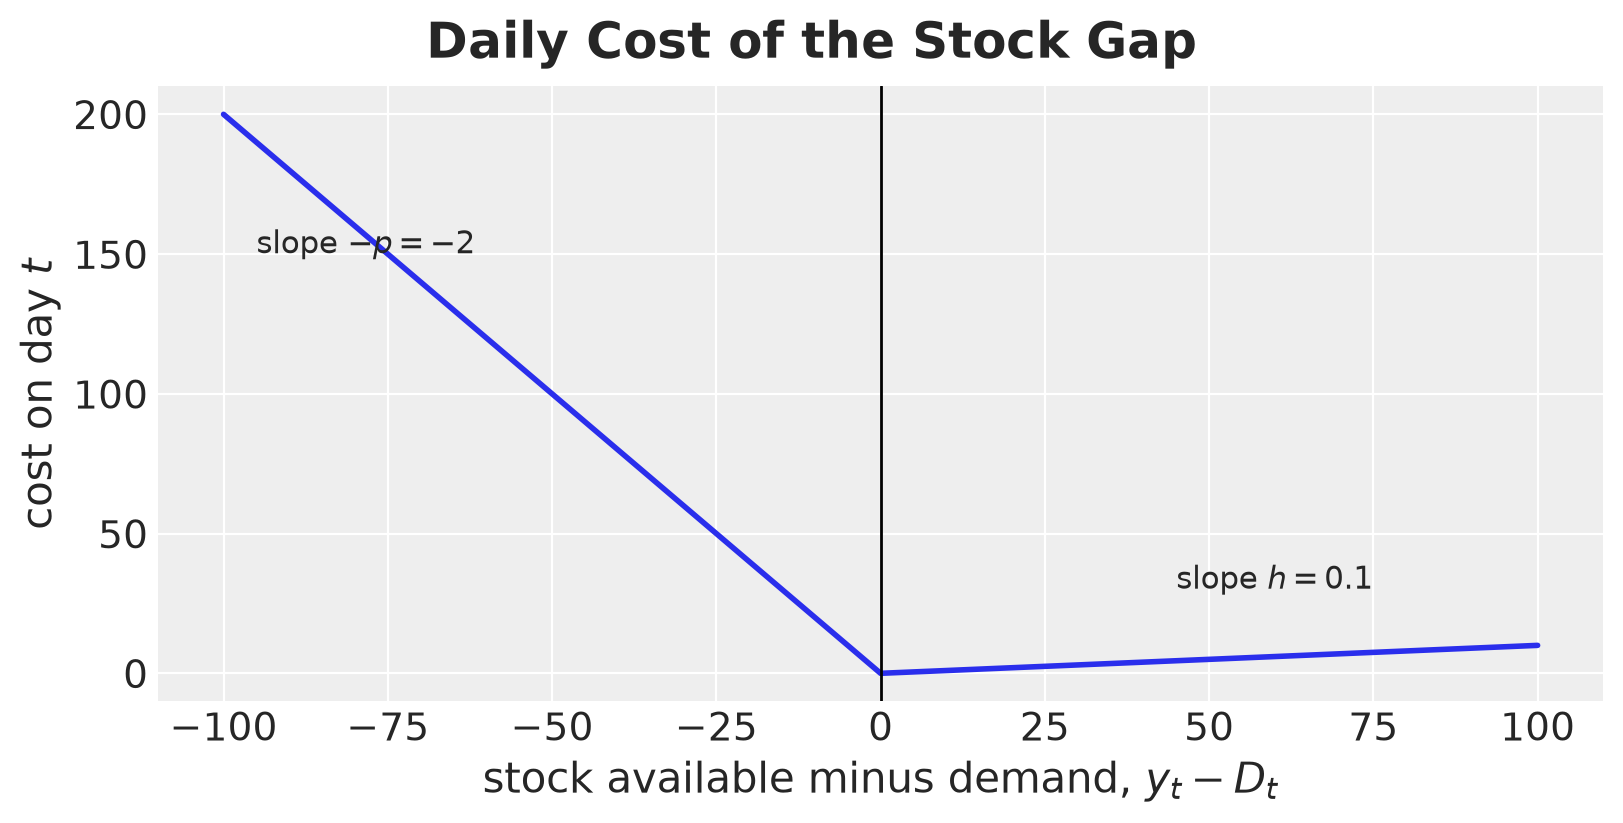

In [3]:
gap_grid = np.linspace(-100, 100, 201)
daily_cost = problem.holding_cost * np.maximum(
    gap_grid, 0.0
) + problem.lost_sales_cost * np.maximum(-gap_grid, 0.0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gap_grid, daily_cost, color="C0", linewidth=2)
ax.axvline(0.0, color="black", linewidth=1)
ax.annotate(
    f"slope $-p = -{problem.lost_sales_cost:g}$",
    xy=(-60, 120),
    xytext=(-95, 150),
    fontsize=11,
)
ax.annotate(
    f"slope $h = {problem.holding_cost:g}$", xy=(60, 6), xytext=(45, 30), fontsize=11
)
ax.set(xlabel="stock available minus demand, $y_t - D_t$", ylabel="cost on day $t$")
fig.suptitle("Daily Cost of the Stock Gap", fontsize=18, fontweight="bold");

The daily cost is zero when the stock matches the demand and grows linearly on both sides. The slope on the lost-sales side is $-p = -2$ per unit and the slope on the leftover side is $h = 0.1$ per unit, so one unit short costs twenty times as much as one unit too many on the day itself.

The two sides differ in one more way: a lost sale is charged once, while a leftover unit stays on the shelf and is charged $h$ again on every later day until a customer buys it. A unit held for $20$ days costs as much as one lost sale, so $h$ stands for the spoilage and markdown risk of a product with a short shelf life more than for the cost of capital.

Why the margin? A plan buys $A_H = \sum_t a_t$ units at the unit cost $c$ and sells $S_t$ units at the unit price, and the two totals differ across plans. Let $m$ be the margin, the price minus the cost, and let $C_H = \sum_t D_t$ be the total demand. If the units left at the end of the horizon keep their value $c$, the profit of the horizon is

$$
\text{profit} = m \, C_H + c \, I_0 - \sum_{t=1}^{H} \left[ h \, I_t + m \, L_t \right].
$$

The first two terms do not depend on the plan, so maximizing the profit is the same as minimizing the loss $L$ with $p = m$. A lost sale costs the margin we would have earned on it, not the price, because we did not pay for the unit either. If the leftover units lose value at the end of the horizon, that loss is a cost of the plan too, and $h$ has to include the cost of the capital tied up in stock and any shrinkage while the units wait.

The forecasting model gives us the posterior predictive distribution of the demand path $D$. We represent it by $S$ joint draws $D^{(1)}, \dots, D^{(S)}$, one path of $H$ days each, which we call scenarios. The plan $a$ must be fixed before we observe any demand, so one plan has to hold up across all of these scenarios. We approximate the expected loss of a plan by its sample average over the scenarios:

$$
\text{E}[L(a, D)] \approx \frac{1}{S} \sum_{s=1}^{S} L(a, D^{(s)}).
$$

Here is the main difference with a backlog model, in which unmet demand waits and the stock can go negative. With lost sales the days are linked only through the stock that carries over: a leftover unit on day $t$ is available on day $t + 1$, and a lost sale on day $t$ is gone. The stock $I_t$ is still a simple function of the plan, the positive part of $I_{t-1} + a_t - D_t$, and we show in the cross check section that the loss is convex in $a$, which is what the optimizer and the linear program need.

We compare four ways of turning the scenarios into a plan.

### Mean Forecast Plan

We replace the distribution by the mean path of the scenarios, $\bar{D} = \frac{1}{S} \sum_{s} D^{(s)}$, and solve the deterministic problem

$$
\min_{a \geq 0} \; L(a, \bar{D}).
$$

This is what a point forecast gives you. Against a single path, the cheapest plan brings the stock available on each day to the demand of that day and leaves nothing on the shelf, so the orders follow the mean path, after the initial stock is used up.

### Chance-Constrained Plan

We ask for a service level instead of a cost. Let $\alpha$ be the stockout probability we accept on any given day. The constraint is

$$
\text{P}(D_t \leq y_t) \geq 1 - \alpha \quad \text{for every } t = 1, \dots, H,
$$

and we look for a plan with the smallest cumulative orders that satisfies it. Note that the constraint holds day by day. It says that on any single day the chance of a lost sale is at most $\alpha$. It does not say that the chance of at least one lost sale somewhere in the $15$ days is at most $\alpha$.

That probability is larger, because the plan has $15$ chances to fail. How much larger depends on how the days move together. If the stockout events were independent across days, the probability would be $1 - (1 - \alpha)^{15} \approx 54\%$ for $\alpha = 0.05$. The events are positively dependent, for two reasons: a stockout on day $t$ leaves no stock for day $t + 1$, and the shared demand level moves all days together. Both lower the probability.

We report both numbers in the evaluation: the stockout probability on a given day, which the constraint controls, and the probability of at least one stockout in the horizon, which it does not.

How do we build the plan? The stock available on day $t$ is $y_t = I_{t-1} + a_t$, and the carried stock $I_{t-1}$ depends on the scenario and on the orders of the earlier days. So we go day by day. Given the orders of days $1$ to $t - 1$, every scenario carries a known stock $I_{t-1}^{(s)}$ into day $t$, and the shortfall that the order has to cover is $D_t^{(s)} - I_{t-1}^{(s)}$. The smallest order that leaves at most a fraction $\alpha$ of the scenarios short is the $(1 - \alpha)$ quantile of that shortfall across the scenarios,

$$
a_t = \left( Q_{1-\alpha}\!\left(D_t - I_{t-1}\right) \right)^{+}.
$$

One forward pass over the days builds the whole plan, and no optimizer is needed. Note that the constraint counts how often we run out and ignores by how much.

### Expected Cost Plan

We minimize the sample average of the loss,

$$
\min_{a \geq 0} \; \frac{1}{S} \sum_{s=1}^{S} L(a, D^{(s)}),
$$

which is the sample average approximation of the Bayes decision. To see what this plan does, look at one day in isolation. The stock available is $y_t$, the demand is $D_t$, a unit left over costs $h$ and a unit short costs $p$. This single-period problem has a name, the newsvendor problem, after the vendor who buys newspapers in the morning without knowing how many will sell.

Its solution has a simple form. Suppose we raise the stock by one unit. With probability $\text{P}(D_t \leq y_t)$ the unit is left over and costs $h$, and with the remaining probability it covers a unit of demand and saves $p$. The expected cost stops decreasing when the two balance:

$$
h \, \text{P}(D_t \leq y_t) = p \, \left[1 - \text{P}(D_t \leq y_t)\right]
\quad \Longleftrightarrow \quad
\text{P}(D_t \leq y_t) = \frac{p}{p + h}.
$$

The optimal stock is the $p / (p + h)$ quantile of the demand distribution, and the ratio $p / (p + h)$ is called the critical fractile. Let's compute the fractile for our costs and plot the expected cost of a single period as a function of the stock, for a Normal demand with mean $60$ and standard deviation $15$.

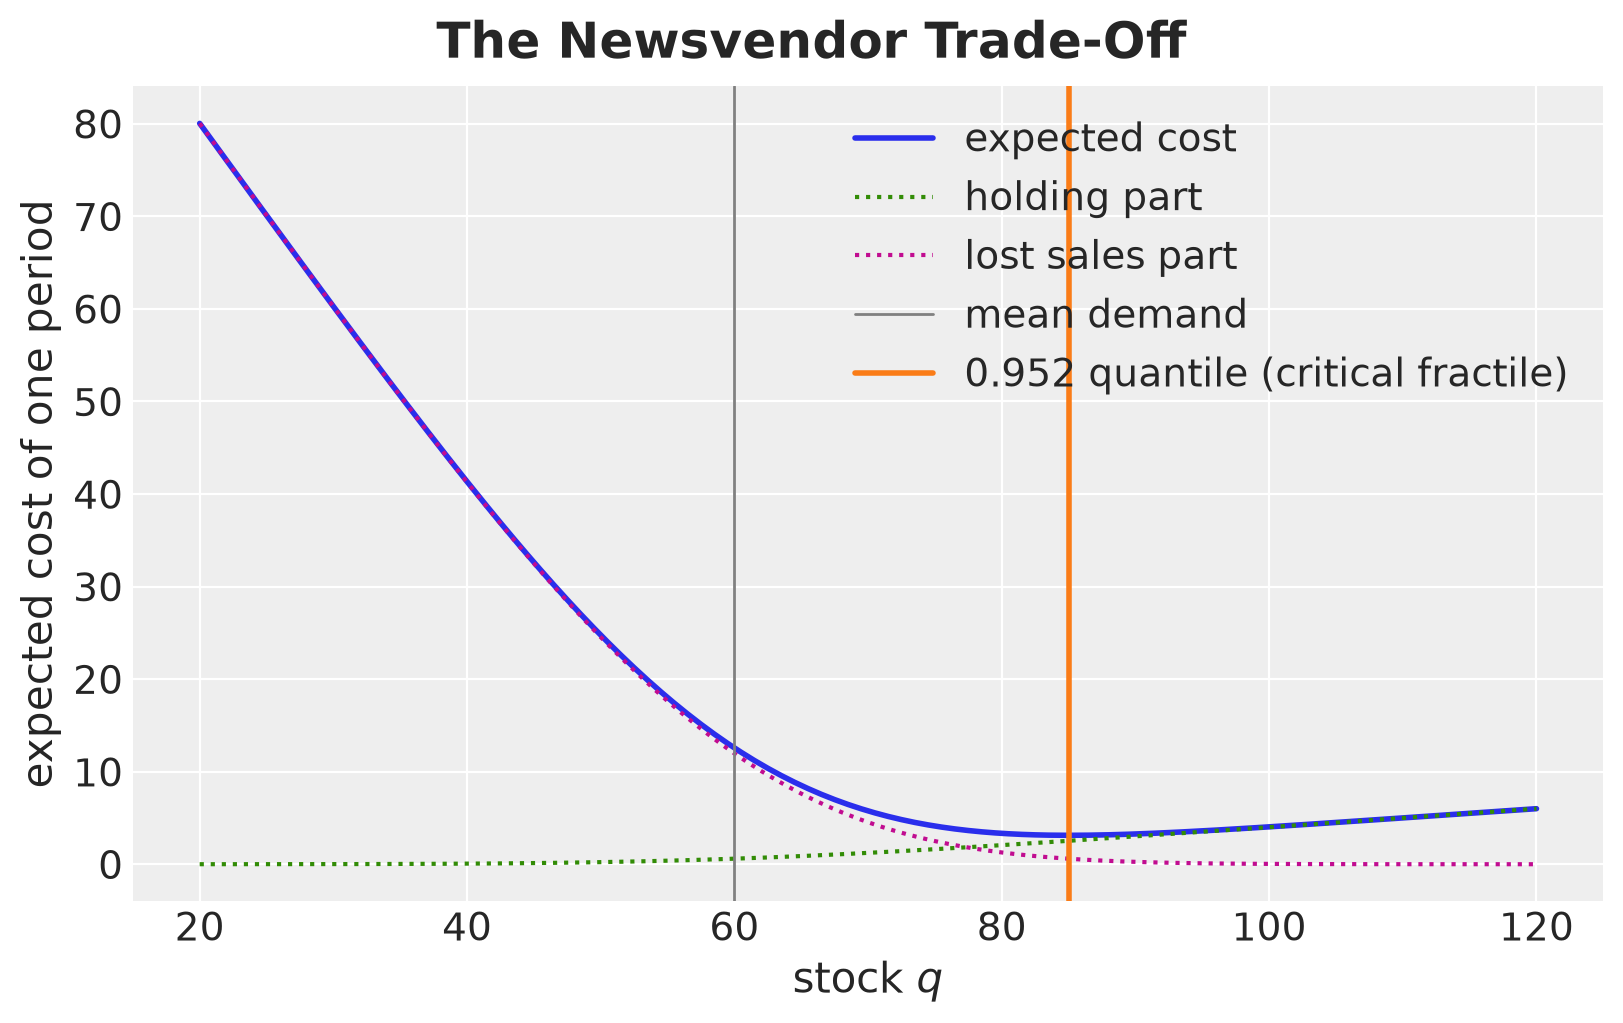

In [4]:
critical_fractile = problem.lost_sales_cost / (
    problem.lost_sales_cost + problem.holding_cost
)

demand_mean, demand_sd = 60.0, 15.0
stock_grid = np.linspace(20, 120, 201)
z = (stock_grid - demand_mean) / demand_sd
# closed forms of E[(q - D)^+] and E[(D - q)^+] for a Normal demand
expected_leftover = demand_sd * (z * stats.norm.cdf(z) + stats.norm.pdf(z))
expected_shortage = demand_sd * (stats.norm.pdf(z) - z * (1 - stats.norm.cdf(z)))
holding_part = problem.holding_cost * expected_leftover
lost_sales_part = problem.lost_sales_cost * expected_shortage
optimal_stock = demand_mean + demand_sd * stats.norm.ppf(critical_fractile)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    stock_grid,
    holding_part + lost_sales_part,
    color="C0",
    linewidth=2,
    label="expected cost",
)
ax.plot(stock_grid, holding_part, color="C2", linestyle=":", label="holding part")
ax.plot(stock_grid, lost_sales_part, color="C3", linestyle=":", label="lost sales part")
ax.axvline(demand_mean, color="gray", linewidth=1, label="mean demand")
ax.axvline(
    optimal_stock,
    color="C1",
    linewidth=2,
    label=f"{critical_fractile:.3f} quantile (critical fractile)",
)
ax.legend(loc="upper right")
ax.set(xlabel="stock $q$", ylabel="expected cost of one period")
fig.suptitle("The Newsvendor Trade-Off", fontsize=18, fontweight="bold");

The expected cost has its minimum at the $0.952$ quantile, about $85$ units, and not at the mean of $60$. The lost sales part makes the curve steep on the left and the holding part makes it flat on the right, so a stock above the mean is cheaper than the mean itself.

Our problem has $15$ days, and the days are linked by the stock that carries over. A unit ordered for day $t$ that is not sold stays on the shelf and costs $h$ again on every later day until it is sold, and the leftovers of day $t - 1$ cushion day $t$. The single-period rule ignores both effects, so it is not the solution of the multi-period problem. The first effect wins: in the loss, a leftover unit has no purchase value left, so all it can do is replace a later order that costs nothing in the loss, while its holding charge is real. The single-period rule therefore overstocks.

With a backlog instead of lost sales the stock would be an affine function of the orders, the expected loss would separate day by day and every day would be a newsvendor problem with a quantile solution. The positive part in $I_t$ removes that structure, and the dynamic version of the problem, with a delivery lead time and orders that react to the stock, is a hard problem in its own right, see [Zipkin (2008)](https://doi.org/10.1287/opre.1070.0471) and the review of [Bijvank and Vis (2011)](https://doi.org/10.1016/j.ejor.2011.02.004). Our plan is fixed in advance, so it is the solution of a convex program, and we solve it numerically. We keep the single-period rule as a reference: on each day, order up to the $p / (p + h)$ quantile of the shortfall $D_t - I_{t-1}$, with the same forward pass as the chance-constrained plan. We call it the myopic newsvendor plan.

Note that the expected cost plan has no service target of its own. The stockout frequency it accepts is a consequence of the costs, and we read it from the outputs below. On the last day of the horizon the problem is a single-period one, since a leftover there is charged holding only once, so the optimal stockout probability on that day is exactly $h / (p + h)$.

The myopic rule is also the order rule of the winning VN2 entry. Szabłowski (2026) computes the fractile $c_s / (c_s + c_h)$ from the competition costs, maps it to a Normal quantile around a point forecast with a calibrated spread, and orders up to that level after projecting the inventory through the lead time. The report names the limitation of the Normal step:

> In production, $q^\star$ would be implemented via empirical quantiles or a probabilistic forecast, avoiding any normality assumption.

That is what we do here: we read the quantile from the scenarios of the probabilistic forecast.

### CVaR Plan

We put a price on the tail. Let $\text{VaR}_\alpha(L) = Q_{1-\alpha}(L)$ be the $(1 - \alpha)$ quantile of the loss, the value at risk. The conditional value at risk is the expected loss beyond that quantile:

$$
\text{CVaR}_\alpha(L) = \text{E}\left[ L \mid L \geq \text{VaR}_\alpha(L) \right].
$$

Here is how we estimate it from the scenarios. We compute the loss of the plan in every scenario, which gives $S$ numbers, and we sort them from largest to smallest. Let $L_{(1)} \geq L_{(2)} \geq \dots \geq L_{(S)}$ denote the sorted losses, so that $L_{(1)}$ is the largest loss and $L_{(S)}$ the smallest. Let $k = \alpha S$ be an integer. The sample estimate of the conditional value at risk is the mean of the $k$ largest losses:

$$
\widehat{\text{CVaR}}_\alpha(L) = \frac{1}{k} \sum_{i=1}^{k} L_{(i)}.
$$

This equals the definition above as long as no two losses tie at the quantile, which we do not expect with real-valued losses. Let's draw the two quantities on a skewed loss density, a LogNormal with log-mean $5$ and log-standard deviation $0.6$, for the tail probability $\alpha = 0.05$. Both quantities have closed forms for this density, which we use for the lines.

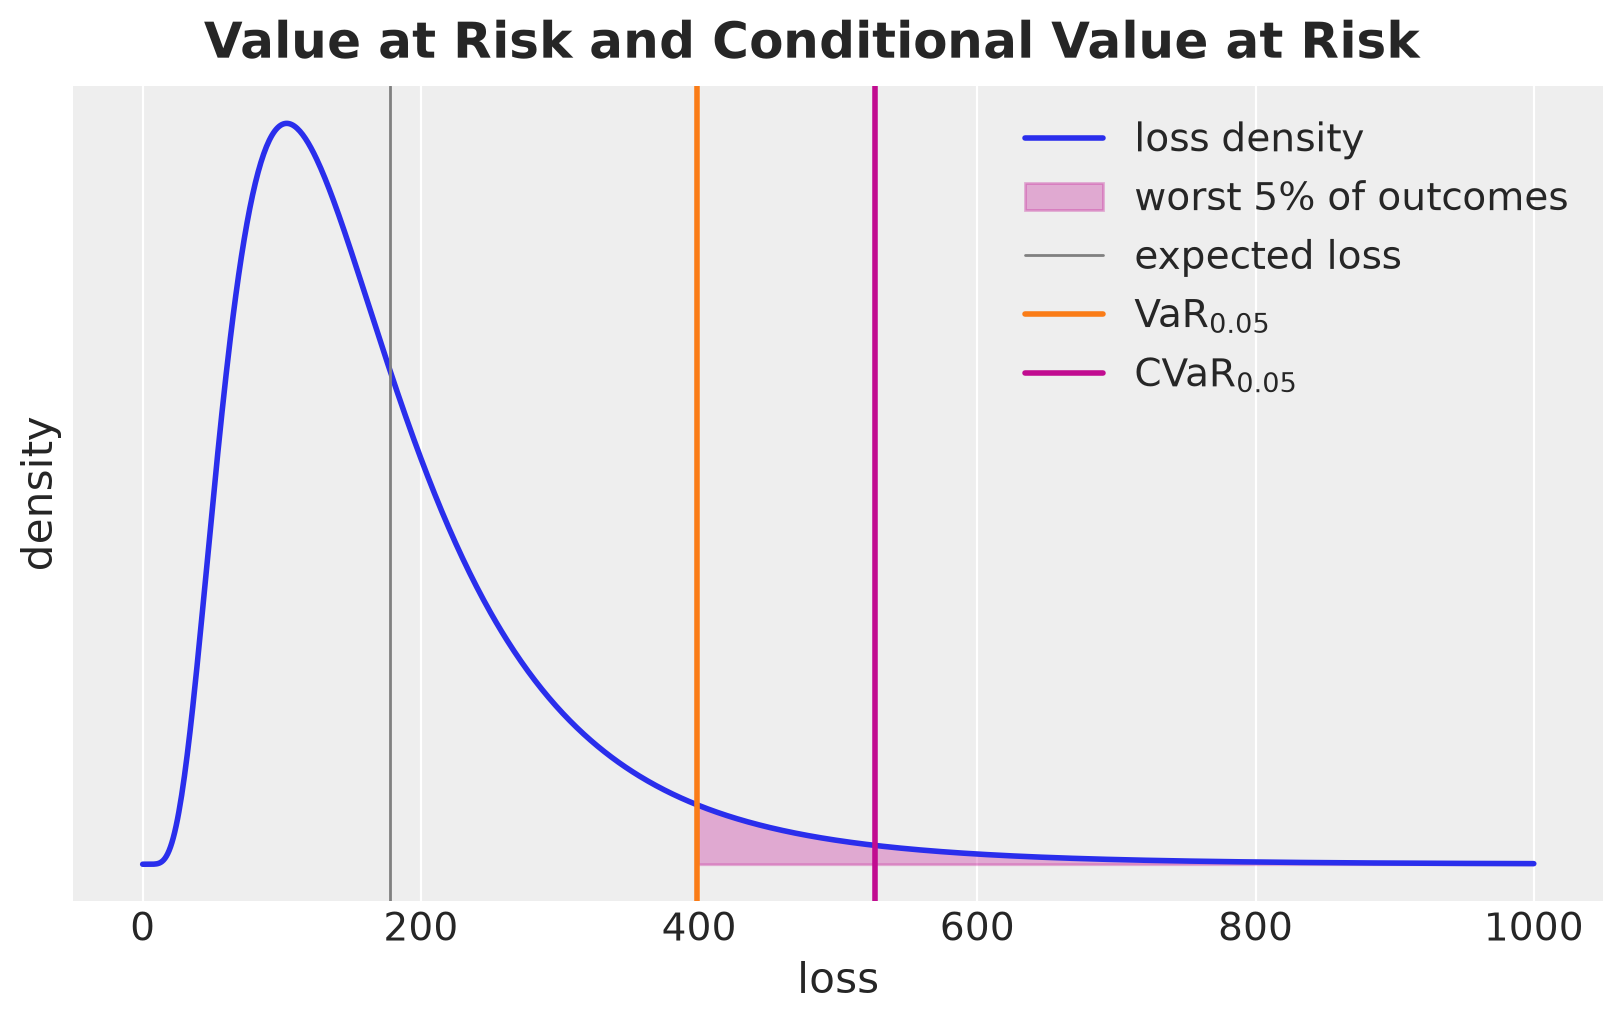

In [5]:
log_mean, log_sd = 5.0, 0.6
loss_grid = np.linspace(0, 1_000, 1_001)
loss_density = stats.lognorm.pdf(loss_grid, s=log_sd, scale=np.exp(log_mean))
z_alpha = stats.norm.ppf(1 - problem.alpha)
expected_loss_example = np.exp(log_mean + log_sd**2 / 2)
var_example = np.exp(log_mean + log_sd * z_alpha)
cvar_example = expected_loss_example * stats.norm.cdf(log_sd - z_alpha) / problem.alpha

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(loss_grid, loss_density, color="C0", linewidth=2, label="loss density")
ax.fill_between(
    loss_grid,
    loss_density,
    where=loss_grid >= var_example,
    color="C3",
    alpha=0.3,
    label=f"{TAIL_LABEL} of outcomes",
)
ax.axvline(expected_loss_example, color="gray", linewidth=1, label="expected loss")
ax.axvline(var_example, color="C1", linewidth=2, label=VAR_LABEL)
ax.axvline(cvar_example, color="C3", linewidth=2, label=CVAR_LABEL)
ax.legend(loc="upper right")
ax.set(xlabel="loss", ylabel="density", yticks=[])
fig.suptitle(
    "Value at Risk and Conditional Value at Risk", fontsize=18, fontweight="bold"
);

The value at risk is the point that the loss exceeds with probability $5\%$. The conditional value at risk is the average loss in the shaded region beyond it, so it sits further to the right. It is well above the expected loss because the density has a long right tail.

We use the same $\alpha = 0.05$ for the CVaR tail and for the chance constraint. We minimize

$$
\min_{a \geq 0} \; \text{E}[L(a, D)] + \lambda \, \text{CVaR}_\alpha(L(a, D)),
$$

where $\lambda \geq 0$ is the weight we put on the worst $\alpha$ fraction of the outcomes. With $\lambda = 0$ we recover the expected cost plan. The CVaR term counts how bad the worst outcomes are, not how often they happen.

All plans use the same scenarios. The differences we see below come from the rule alone. Let's generate the data.

## Generate Data

We simulate daily demand from a generative model with a slowly drifting level, a weekly pattern, price promotions and negative binomial noise. We write the model in NumPyro, fix the true parameters with the `do` handler and take one draw with `Predictive`.

Let's fix the length of the history, the horizon and the promotion settings in a `Setup` tuple. We keep one year of daily history ($52$ weeks) and a horizon of $15$ days.

In [6]:
class Setup(NamedTuple):
    """Length of the history and the horizon, and the promotion settings."""

    t_obs: int = 364  # one year of daily history
    horizon: int = 15  # days to plan
    discount: float = 0.3  # price cut in a promotion week
    promo_prob: float = 0.1  # chance that a given week of the history is a promotion

    @property
    def duration(self) -> int:
        return self.t_obs + self.horizon


setup = Setup()

Why price? A covariate helps the forecast only if we know its future values. Price qualifies because the retailer sets it, so the promotion calendar for the horizon is part of the plan. Weather or competitor actions would need a forecast of their own.

A promotion lasts one calendar week and cuts the list price by $30\%$. In the history, each week is a promotion week with probability $0.1$. In the horizon the calendar is the retailer's plan: the second week of the horizon (days $8$ to $14$) is a promotion week, and we pass it to the generator as an input.

Here is the data generating process. Let $\delta_t$ be the daily increment of the level, $\ell_t$ the level, $f(t)$ the vector of Fourier features of the weekly cycle, $r_t$ the price relative to the list price and $\mu_t$ the expected demand on day $t$:

$$
\begin{aligned}
\delta_t &\sim \text{Normal}(0, \sigma_\delta), \qquad \ell_t = \sum_{\tau \leq t} \delta_\tau, \\
\log \mu_t &= \beta_0 + \ell_t + f(t)^\top \beta + \gamma \log r_t, \\
D_t &\sim \text{NegativeBinomial}(\mu_t, \phi),
\end{aligned}
$$

where $\beta_0$ is the `intercept`, $\beta$ the Fourier coefficients `beta`, $\gamma$ the price `elasticity`, $\sigma_\delta$ the `drift_scale` and $\phi$ the `concentration` of the negative binomial (a larger $\phi$ is closer to a Poisson). The price enters as a log, and this is what makes $\gamma$ an elasticity. Taking exponentials,

$$
\mu_t = \exp\left(\beta_0 + \ell_t + f(t)^\top \beta\right) \cdot r_t^{\gamma},
$$

so a relative price $r_t$ multiplies the demand by $r_t^{\gamma}$. In a promotion week $r_t = 0.7$, and with $\gamma = -1.5$ the demand is multiplied by $0.7^{-1.5} \approx 1.71$.

First, let's build the Fourier design matrix over the full duration (history plus horizon) and define the generator, together with the true parameter values that we intervene on. The promotion weeks of the history are Bernoulli draws under a `week` plate, repeated over the seven days of each week. The `log_price` site is deterministic so that we can read the price path back from the draw.

In [7]:
fourier = fourier_features(setup.duration, period=7.0, num_terms=3)
# the retailer's plan for the horizon: a promotion in its second week
promo_future = jnp.zeros(setup.horizon).at[7:14].set(1.0)


def demand_generator(
    fourier: Float[Array, "duration features"],
    promo_future: Float[Array, " horizon"],
    setup: Setup,
) -> None:
    """Daily demand with a drifting level, a weekly pattern and price promotions."""
    duration, num_features = fourier.shape
    intercept = numpyro.sample("intercept", dist.Normal(4.0, 1.0))
    beta = numpyro.sample(
        "beta", dist.Normal(0.0, 0.3).expand([num_features]).to_event(1)
    )
    elasticity = numpyro.sample("elasticity", dist.Normal(0.0, 1.0))
    drift_scale = numpyro.sample("drift_scale", dist.HalfNormal(0.05))
    concentration = numpyro.sample("concentration", dist.Gamma(20.0, 1.0))

    # one Bernoulli per week of history, repeated over its seven days
    with numpyro.plate("week", setup.t_obs // 7):
        promo_week = numpyro.sample("promo_week", dist.Bernoulli(setup.promo_prob))

    promo = jnp.concatenate([jnp.repeat(promo_week, 7), promo_future])
    log_price = numpyro.deterministic(
        "log_price", promo * jnp.log(1.0 - setup.discount)
    )

    with numpyro.plate("time", duration):
        drift = numpyro.sample("drift", dist.Normal(0.0, drift_scale))
        level = jnp.cumsum(drift)  # random walk level
        log_rate = intercept + level + fourier @ beta + elasticity * log_price
        numpyro.sample("y", dist.NegativeBinomial2(jnp.exp(log_rate), concentration))


true_params = {
    "intercept": jnp.log(60.0),
    "beta": jnp.array([0.15, 0.05, -0.08, 0.10, 0.03, -0.02]),
    "elasticity": jnp.array(-1.5),
    "drift_scale": jnp.array(0.01),
    "concentration": jnp.array(30.0),
}

Next, we take one draw from the intervened model. We keep the demand and the price path, and we split the demand into the observed history and the true future. The covariate matrix of the forecasting model is the Fourier design plus the log relative price as a last column. The negative binomial draws are integers already, and we cast the true future to floats once because the inventory simulator works in floats.

In [8]:
rng_key, key_data = random.split(rng_key)
generator = Predictive(handlers.do(demand_generator, data=true_params), num_samples=1)
draw = generator(key_data, fourier, promo_future, setup)

demand_full = draw["y"][0]
log_price = draw["log_price"][0]
covariates = jnp.concatenate([fourier, log_price[:, None]], axis=1)

# time at axis -2, one observation dim at -1
data = demand_full[: setup.t_obs, None]
demand_future_true = demand_full[setup.t_obs :].astype(jnp.float32)
days = np.arange(setup.duration)
days_future = days[setup.t_obs :]
promo_days_future = days_future[np.asarray(promo_future) > 0]

Let's look at the demand series and the price path below it. The dashed line marks the start of the planning horizon.

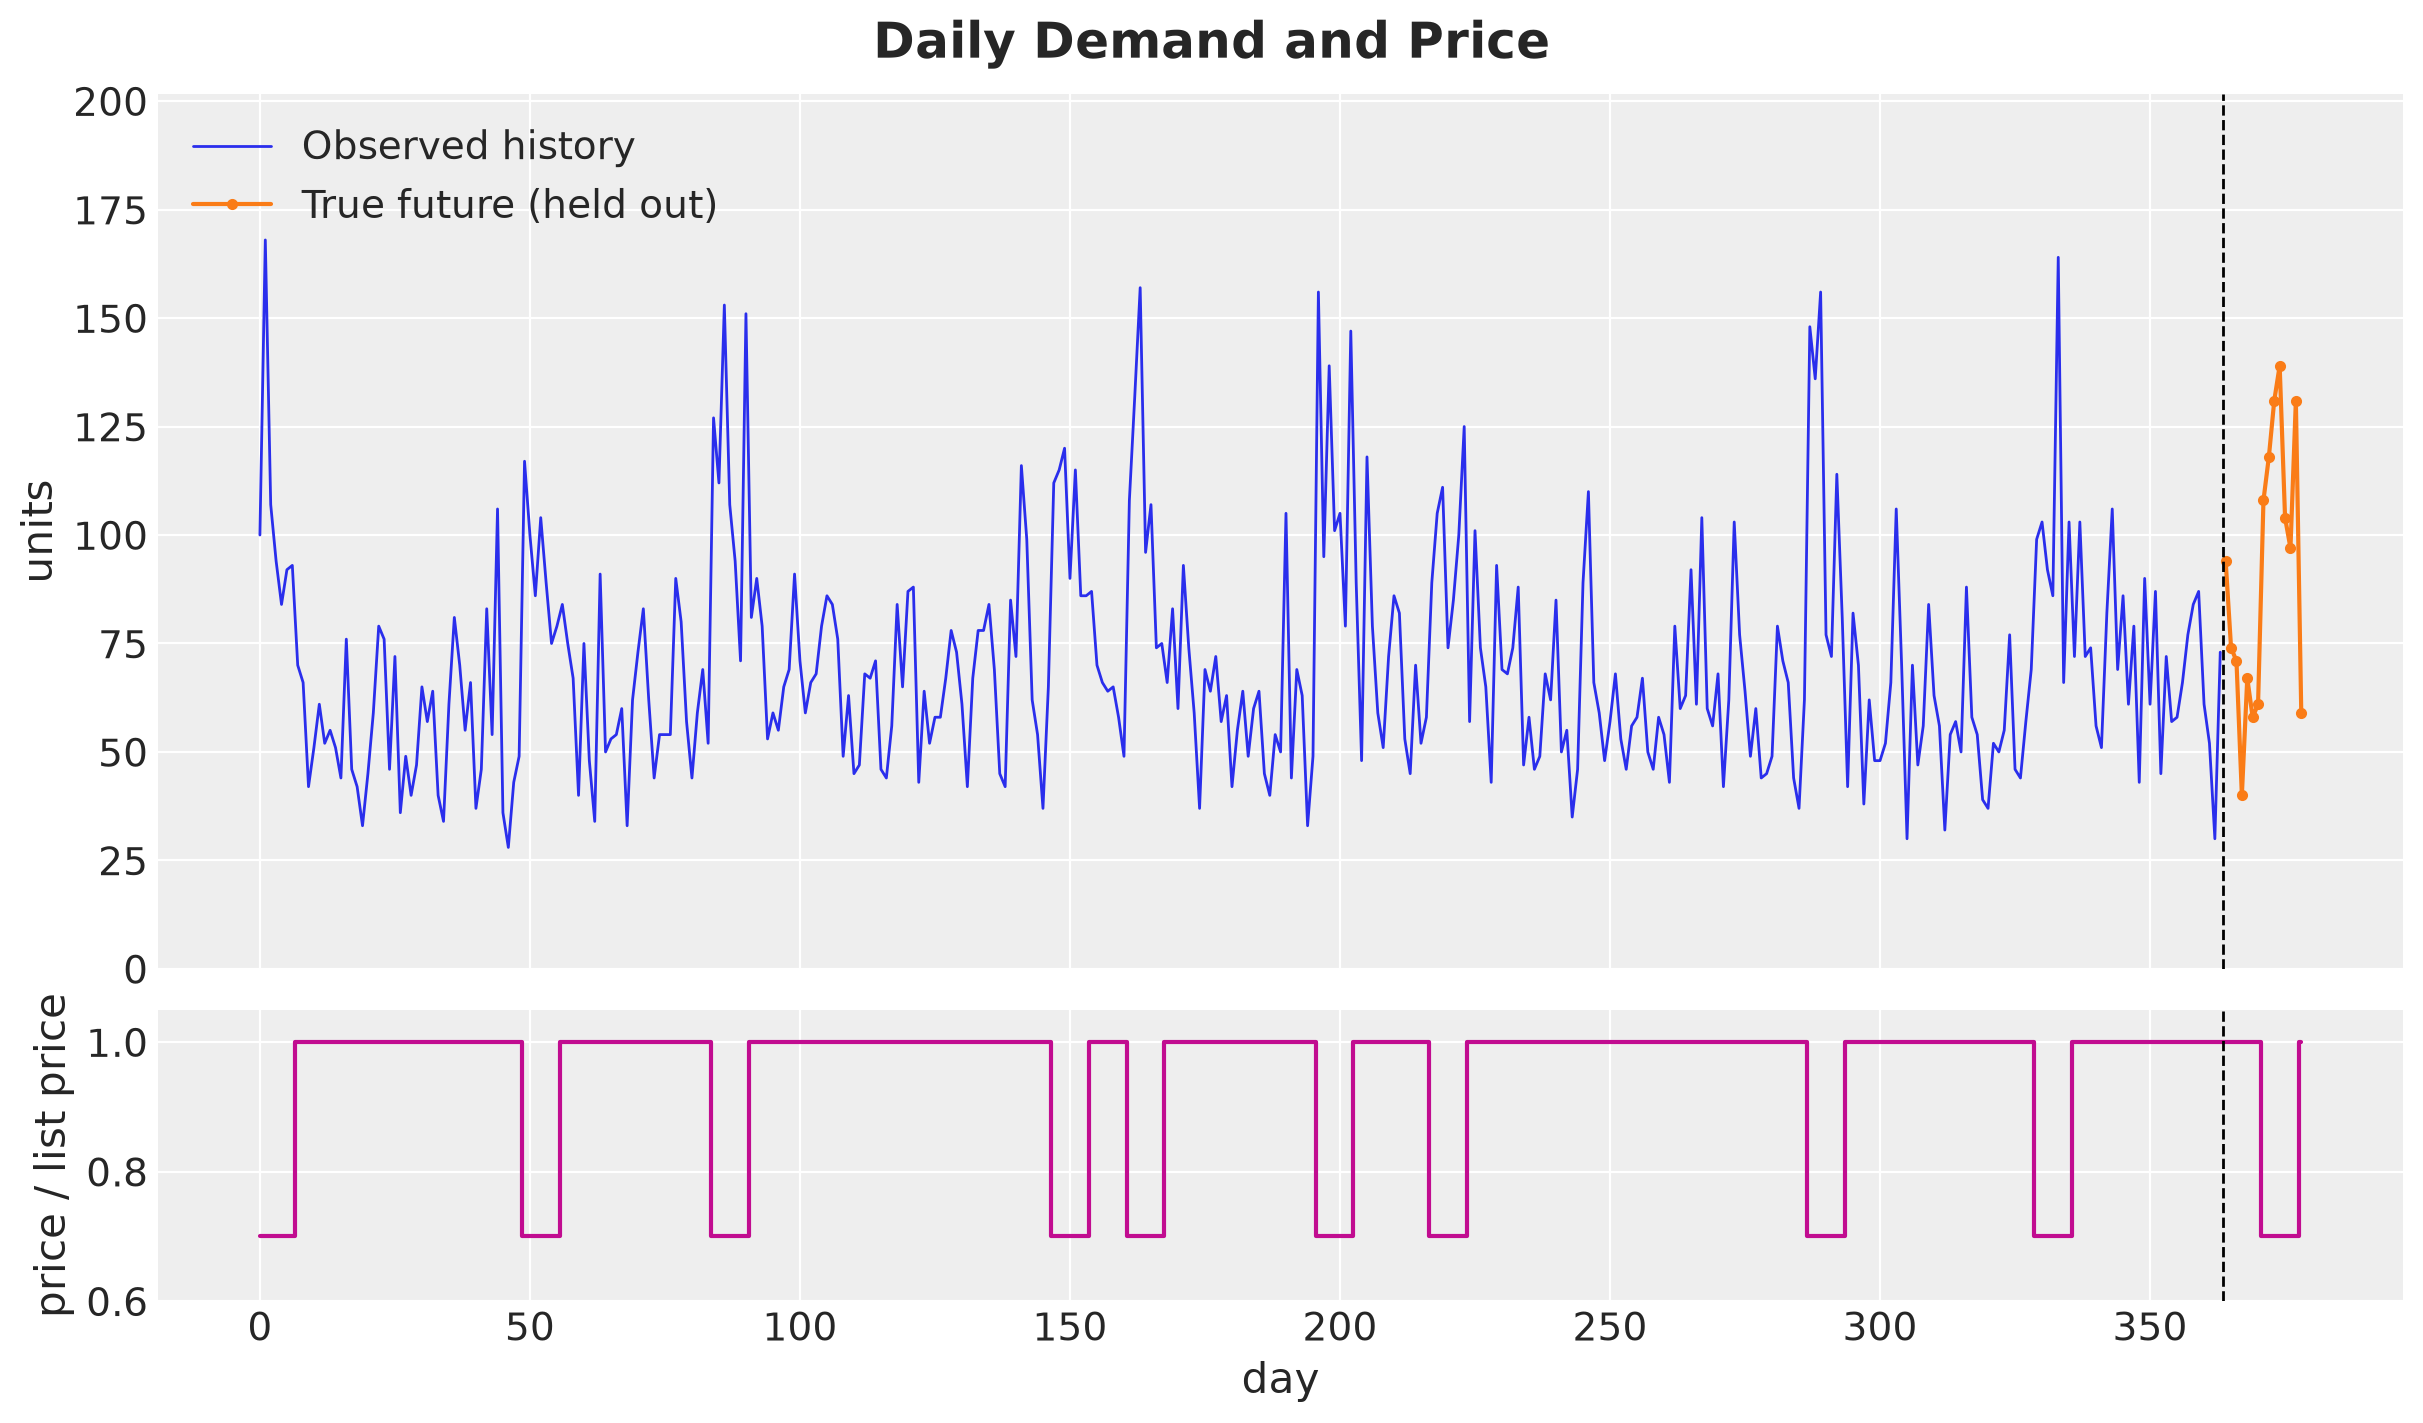

In [9]:
fig, axes = plt.subplots(
    nrows=2, figsize=(12, 7), sharex=True, height_ratios=[3, 1], layout="constrained"
)
ax = axes[0]
ax.plot(
    days[: setup.t_obs],
    np.asarray(data[:, 0]),
    color="C0",
    linewidth=1,
    label="Observed history",
)
ax.plot(
    days_future,
    np.asarray(demand_future_true),
    "o-",
    markersize=3,
    color="C1",
    label="True future (held out)",
)
ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--", linewidth=1)
ax.legend(loc="upper left")
ax.set(ylabel="units", ylim=(0, 1.2 * float(demand_full.max())))
ax = axes[1]
ax.step(days, np.exp(np.asarray(log_price)), where="mid", color="C3")
ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="day", ylabel="price / list price", ylim=(0.6, 1.05))
fig.suptitle("Daily Demand and Price", fontsize=18, fontweight="bold");

We see a weekly cycle on top of a level that drifts over the year, and a block of high demand in every promotion week. The blocks are the part of the series that the price covariate explains. The true future appears in the plots as a reference, and we score the plans on it at the very end.

## Forecasting Model

The forecasting model has the same structure as the generator, so it is well specified. We write it as a `numpyro_forecast` model: a plain function `(covariates, data=None)` whose first line derives the train/forecast split from the array shapes.

- **Horizon.** `Horizon.from_data` reads the observed length from `data` and the full duration from `covariates`. The horizon is whatever the covariates have beyond the data.
- **Innovations.** `innovations` samples the level increments under a `time` plate over the history and under a separate `time_future` plate over the horizon, so one model both trains and forecasts.
- **Prediction.** `predict` with a link function registers `obs` over the training window and `forecast` over the horizon, here with a negative binomial likelihood on the log rate.

Let's define the model. The last column of `covariates` is the log relative price. The prior on `elasticity` is centered at zero, so the data determine its sign and size.

In [10]:
def demand_model(
    covariates: Float[Array, "duration features"],
    data: Int[Array, "t_obs 1"] | None = None,
) -> None:
    """Local level plus weekly seasonality plus price, negative binomial likelihood."""
    horizon = Horizon.from_data(covariates, data)
    fourier, log_price = covariates[..., :-1], covariates[..., -1]
    num_features = fourier.shape[-1]
    intercept = numpyro.sample("intercept", dist.Normal(4.0, 1.0))
    beta = numpyro.sample(
        "beta", dist.Normal(0.0, 0.3).expand([num_features]).to_event(1)
    )
    elasticity = numpyro.sample("elasticity", dist.Normal(0.0, 1.0))
    drift_scale = numpyro.sample("drift_scale", dist.HalfNormal(0.05))
    concentration = numpyro.sample("concentration", dist.Gamma(20.0, 1.0))
    # non-centered increments: the sampler sees standardized drifts
    drift = innovations(
        horizon, "drift", dist.Normal(0.0, drift_scale), reparam=LocScaleReparam(0)
    )
    level = jnp.cumsum(drift, axis=-2)
    regression = (fourier @ beta + elasticity * log_price)[..., None]
    log_rate = intercept + level + regression

    def likelihood(eta: Float[Array, "..."]) -> Distribution:
        return dist.NegativeBinomial2(jnp.exp(eta), concentration)

    predict(horizon, likelihood, log_rate)

Let's render the model on the training window to see its structure.

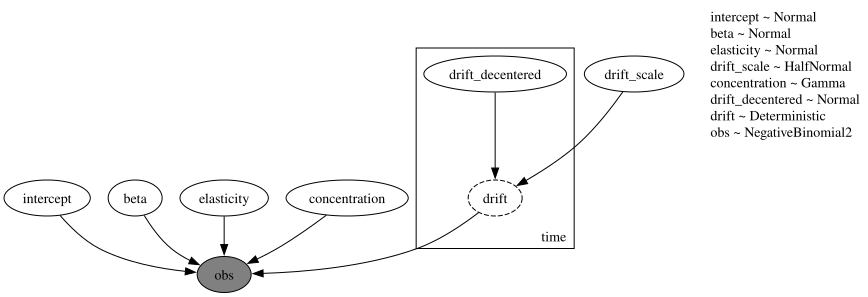

In [11]:
numpyro.render_model(
    demand_model,
    model_args=(covariates[: setup.t_obs], data),
    render_distributions=True,
    render_params=True,
)

The global parameters sit outside the `time` plate. Inside it we see `drift_decentered`, the standardized increments that the `LocScaleReparam` samples, and the deterministic `drift` that rescales them by `drift_scale`. The observation site `obs` collects the whole training window. On the training window there is no horizon, so the `time_future` plate does not appear.

## Model Fitting

We fit the model with NUTS, four chains of $1{,}000$ draws each. Every draw is one joint scenario later on, so we keep all $4{,}000$ of them.

In [12]:
rng_key, key_fit = random.split(rng_key)
mcmc = MCMC(
    NUTS(demand_model, target_accept_prob=0.98),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
    progress_bar=False,
)
mcmc.run(key_fit, covariates[: setup.t_obs], data)
posterior = mcmc.get_samples()

`to_datatree` turns the posterior into an `xarray.DataTree` in the ArviZ schema. Because `covariates` extends beyond `data`, the tree also carries in-sample posterior predictive draws and the forecast draws over the horizon.

In [13]:
rng_key, key_tree = random.split(rng_key)
idata = to_datatree(key_tree, demand_model, posterior, data, covariates, num_chains=4)
idata

<xarray.DataTree>
Group: /
│   Attributes:
│       inference_library:  numpyro
│       creation_library:   numpyro_forecast
│       sample_dims:        ['chain', 'draw']
├── Group: /posterior
│       Dimensions:                 (chain: 4, draw: 1000, beta_dim_0: 6,
│                                    drift_dim_0: 364, drift_dim_1: 1,
│                                    drift_decentered_dim_0: 364,
│                                    drift_decentered_dim_1: 1)
│       Coordinates:
│         * chain                   (chain) int64 32B 0 1 2 3
│         * draw                    (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│         * beta_dim_0              (beta_dim_0) int64 48B 0 1 2 3 4 5
│         * drift_dim_0             (drift_dim_0) int64 3kB 0 1 2 3 ... 360 361 362 363
│         * drift_dim_1             (drift_dim_1) int64 8B 0
│         * drift_decentered_dim_0  (drift_decentered_dim_0) int64 3kB 0 1 2 ... 362 363
│         * drift_decentered_dim_1  (drift_decentered_dim_1) int64 8B 0
│       Data variables:
│           beta                    (chain, draw, beta_dim_0) float32 96kB 0.1667 ......
│           concentration           (chain, draw) float32 16kB 29.68 25.97 ... 28.81
│           drift                   (chain, draw, drift_dim_0, drift_dim_1) float32 6MB ...
│           drift_decentered        (chain, draw, drift_decentered_dim_0, drift_decentered_dim_1) float32 6MB ...
│           drift_scale             (chain, draw) float32 16kB 0.01377 ... 0.01845
│           elasticity              (chain, draw) float32 16kB -1.543 -1.538 ... -1.459
│           intercept               (chain, draw) float32 16kB 4.074 3.932 ... 4.041
│       Attributes:
│           created_at:                 2026-10-23T20:18:56.782816+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /posterior_predictive
│       Dimensions:  (chain: 4, draw: 1000, time: 364, obs_dim: 1)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) int64 3kB 0 1 2 3 4 5 6 7 ... 357 358 359 360 361 362 363
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (chain, draw, time, obs_dim) int32 6MB 125 139 129 58 ... 74 50 76
│       Attributes:
│           created_at:                 2026-10-23T20:18:57.342215+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:  (time: 364, obs_dim: 1)
│       Coordinates:
│         * time     (time) int64 3kB 0 1 2 3 4 5 6 7 ... 357 358 359 360 361 362 363
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (time, obs_dim) int32 1kB 100 168 107 94 84 92 ... 87 61 52 30 73
│       Attributes:
│           created_at:                 2026-10-23T20:18:57.342528+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                []
├── Group: /constant_data
│       Dimensions:        (time: 364, covariate_dim: 7)
│       Coordinates:
│         * time           (time) int64 3kB 0 1 2 3 4 5 6 ... 358 359 360 361 362 363
│         * covariate_dim  (covariate_dim) int64 56B 0 1 2 3 4 5 6
│       Data variables:
│           covariates     (time, covariate_dim) float32 10kB 0.0 0.0 ... -0.901 -0.0
│       Attributes:
│           created_at:                 2026-10-23T20:18:57.342767+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                [

The tree holds the posterior, the in-sample posterior predictive, the observed data and the forecast draws as separate groups, so every ArviZ function works on it directly. Let's check the sampler diagnostics for the global parameters.

In [14]:
global_params = ["intercept", "beta", "elasticity", "drift_scale", "concentration"]
az.summary(idata, var_names=global_params)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,4.048,0.054,3.9,4.1,4492,2981,1.00,0.00081,0.00088
beta[0],0.1579,0.0172,0.13,0.19,12149,2547,1.00,0.00016,0.00037
beta[1],0.0201,0.0169,-0.013,0.051,11175,2744,1.00,0.00016,0.00034
beta[2],-0.0593,0.0172,-0.092,-0.028,9674,2527,1.00,0.00018,0.00037
beta[3],0.1055,0.0168,0.072,0.14,9863,2816,1.00,0.00017,0.00031
beta[4],0.0149,0.0166,-0.018,0.045,9567,2664,1.00,0.00017,0.00032
beta[5],-0.0108,0.0173,-0.043,0.022,9589,2286,1.00,0.00018,0.00032
elasticity,-1.488,0.092,-1.7,-1.3,9178,3159,1.00,0.00096,0.0017
drift_scale,0.0114,0.0049,0.0026,0.02,1234,1645,1.00,0.00014,9.2e-05
concentration,26.89,2.55,22,32,7751,3067,1.00,0.029,0.046


The $\hat{R}$ values are at $1.0$ and the effective sample sizes are above $1{,}000$ for every parameter, which is good! Let's also look at the traces.

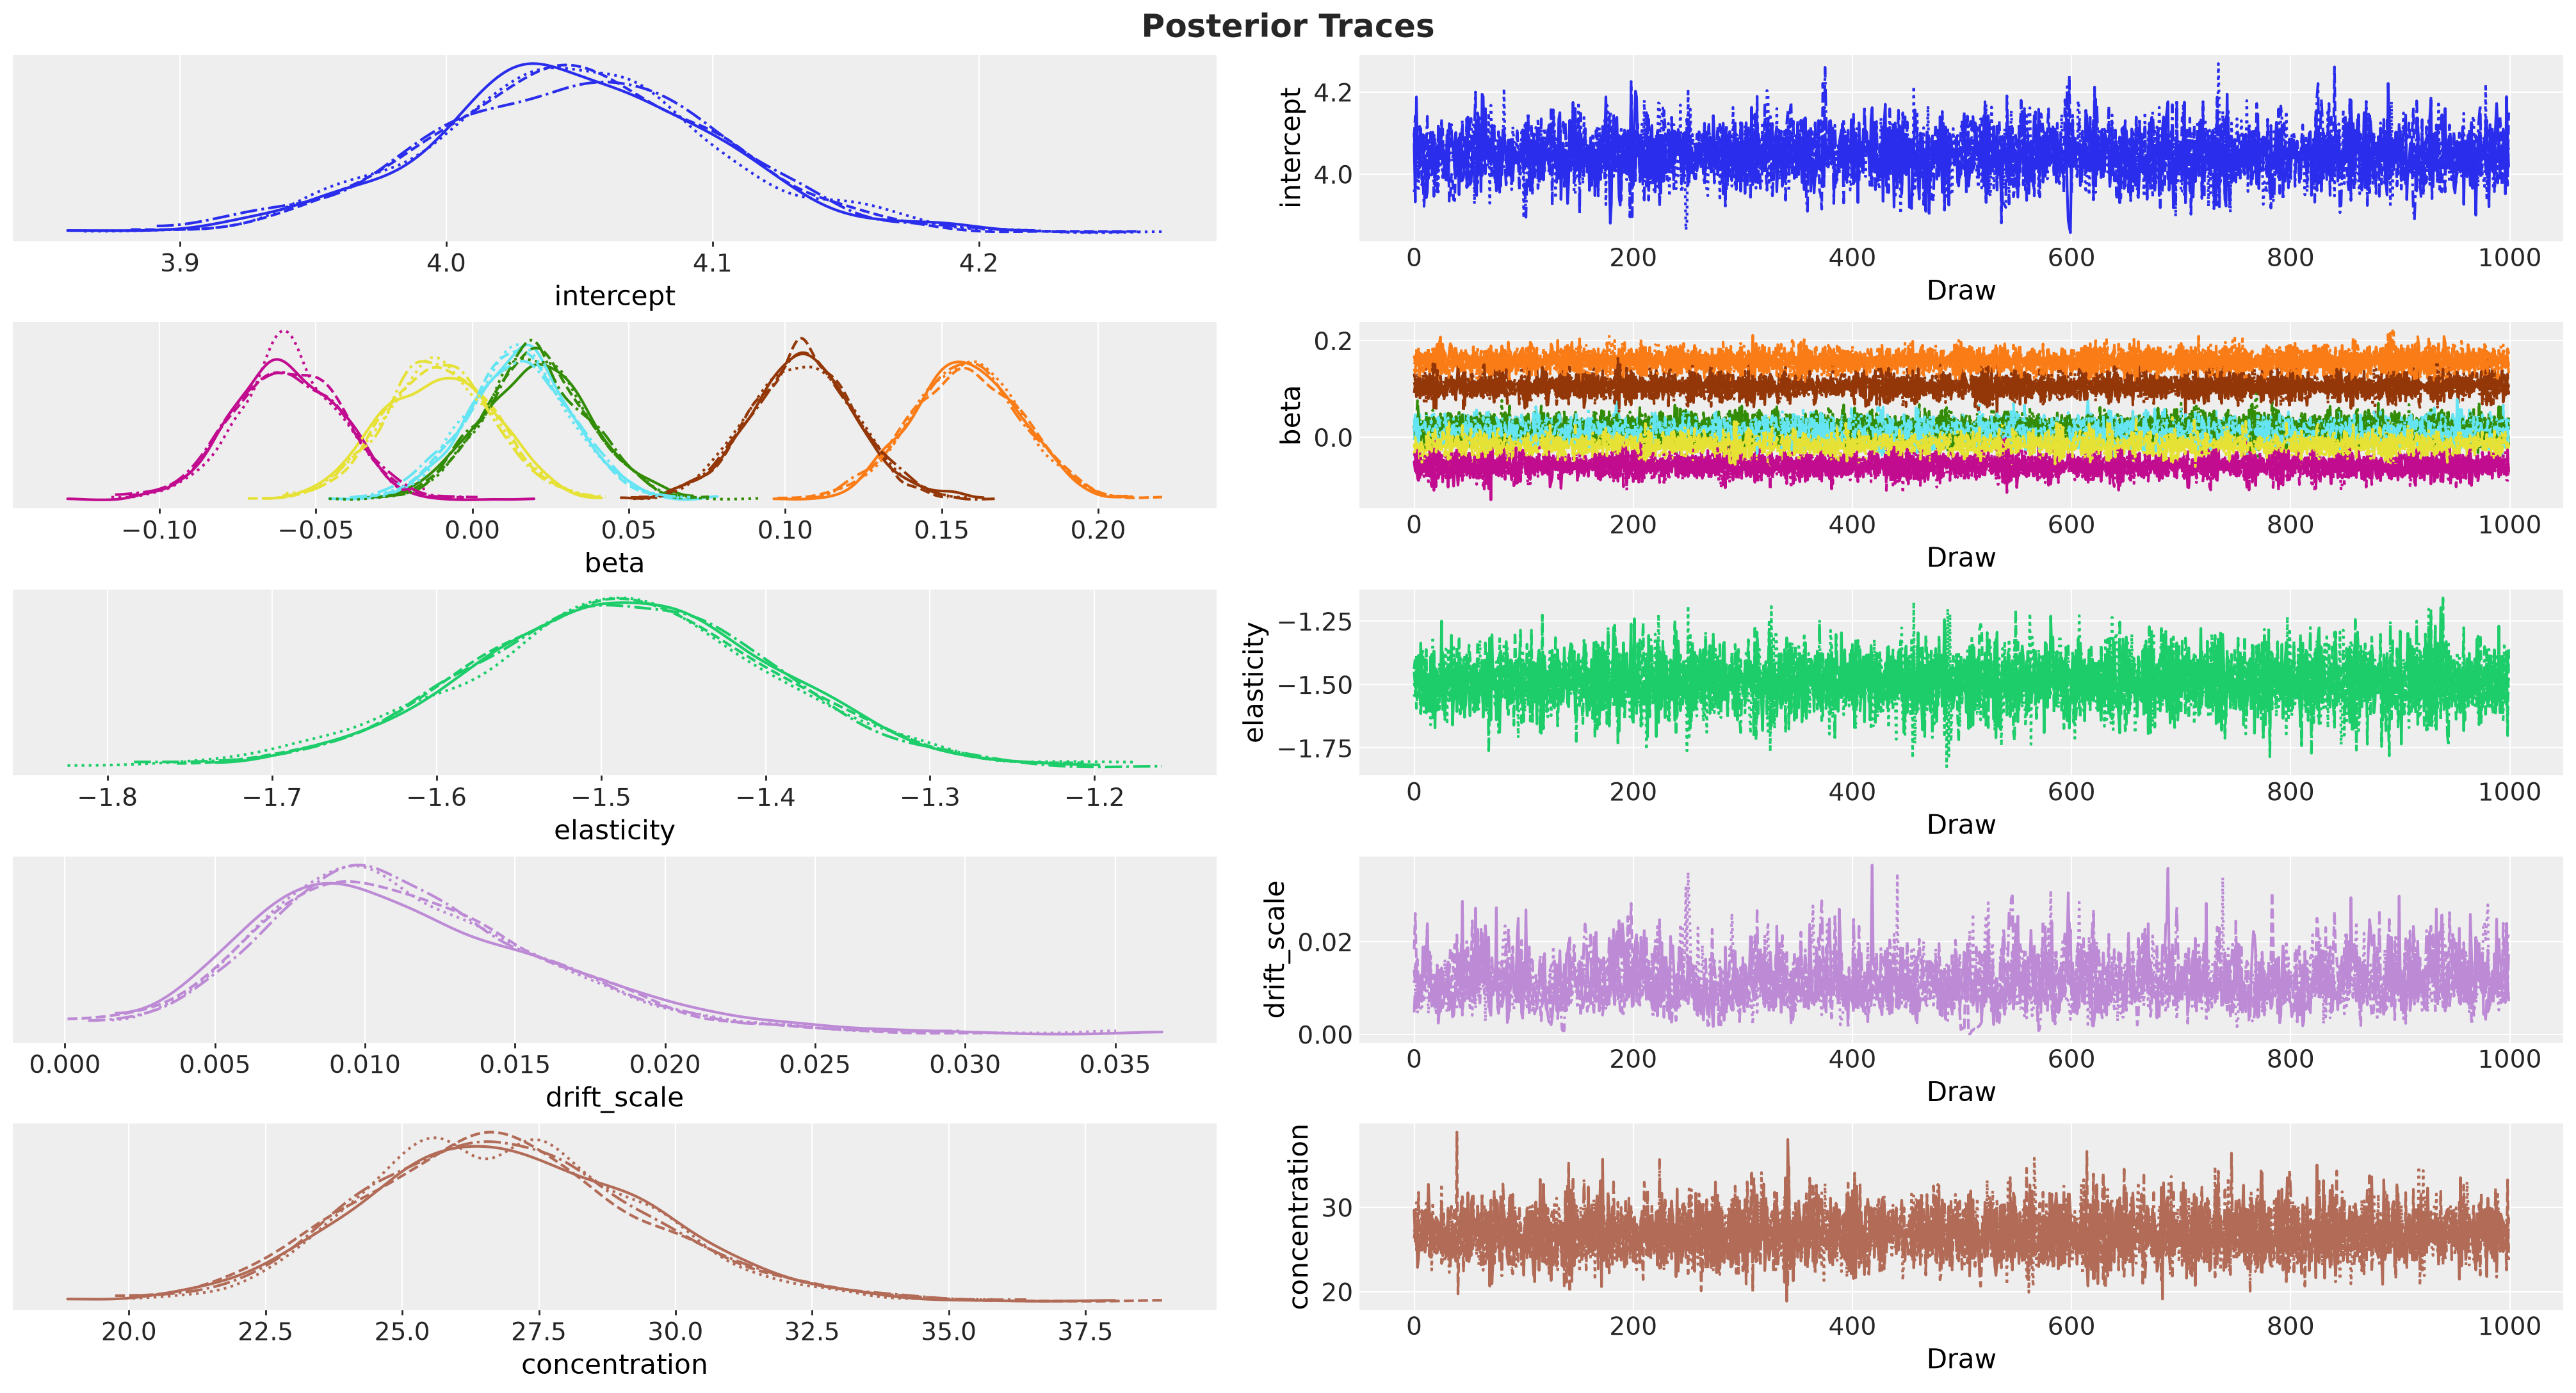

In [15]:
pc = az.plot_trace_dist(idata, var_names=global_params)
pc.viz["figure"].item().suptitle("Posterior Traces", fontsize=18, fontweight="bold");

The chains mix well. Next, we check that the posterior recovers the parameters we fixed in the generator. The vertical lines are the true values.

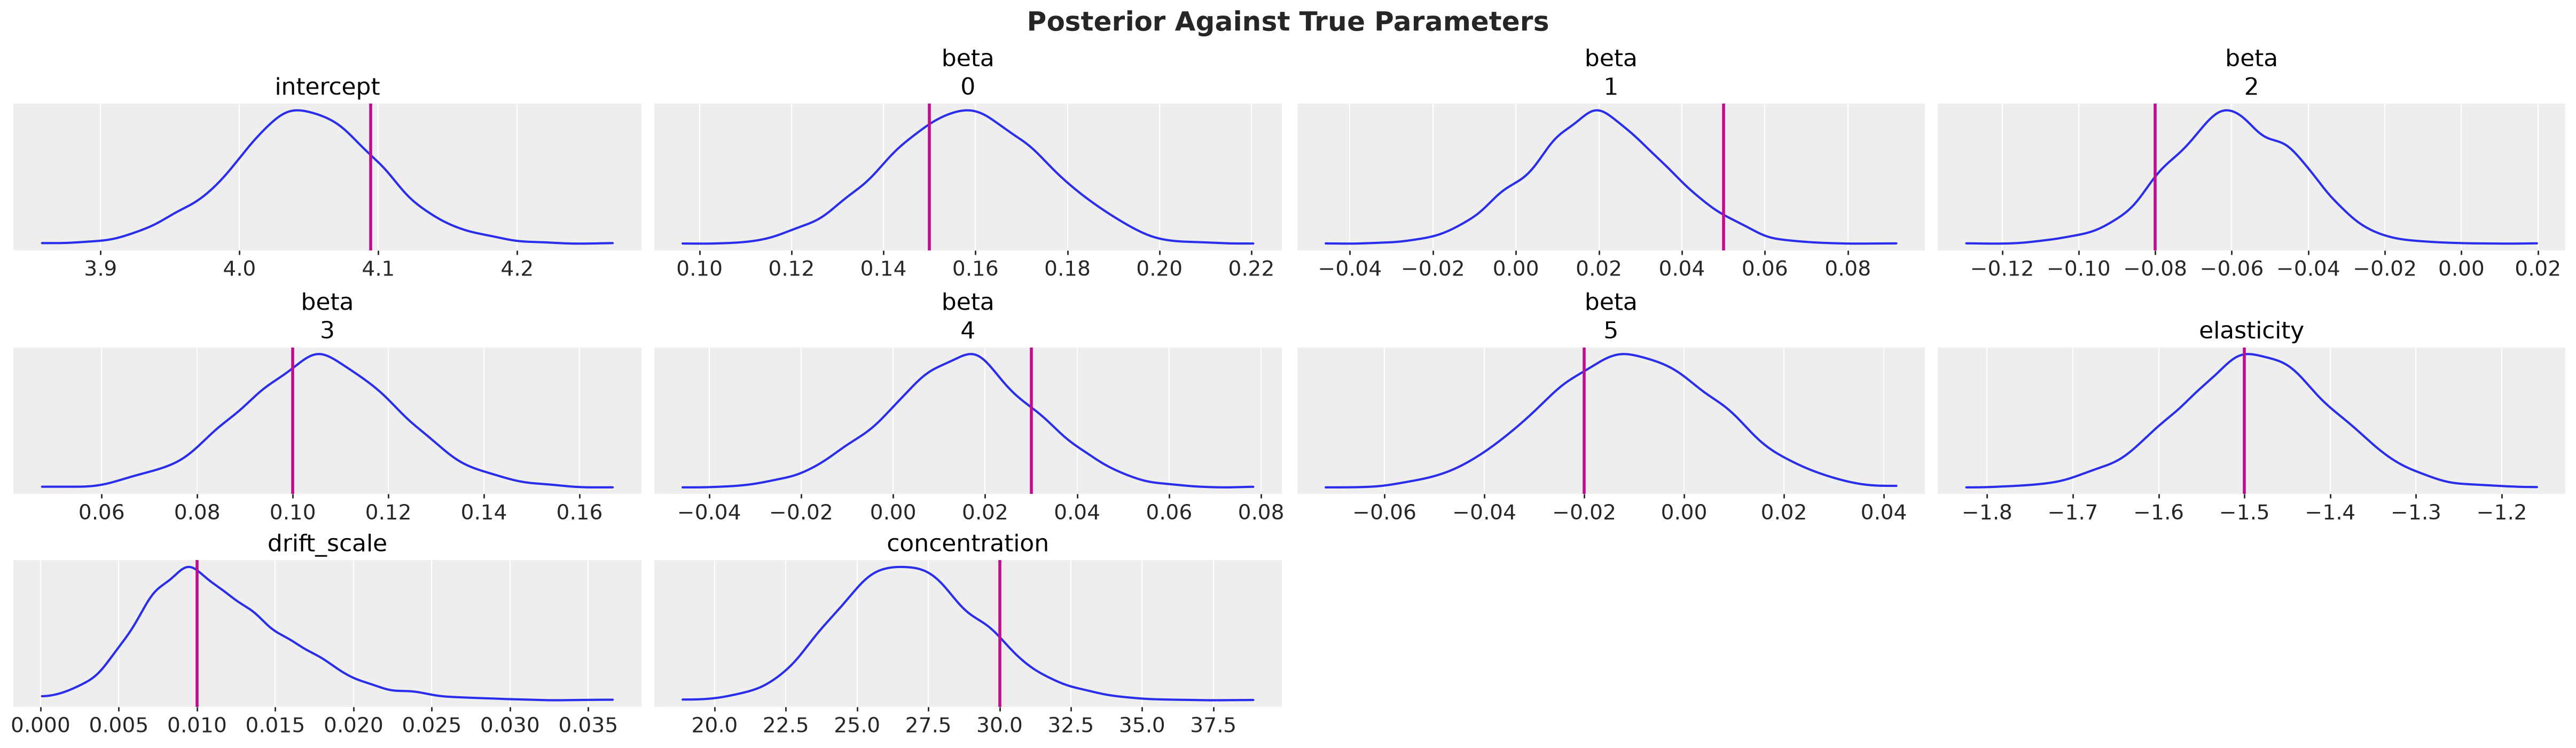

In [16]:
true_values = xr.Dataset(
    {
        "intercept": float(true_params["intercept"]),
        "beta": (idata["posterior"]["beta"].dims[-1], np.asarray(true_params["beta"])),
        "elasticity": float(true_params["elasticity"]),
        "drift_scale": float(true_params["drift_scale"]),
        "concentration": float(true_params["concentration"]),
    }
)

pc = az.plot_dist(
    idata,
    var_names=global_params,
    kind="kde",
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
)
az.add_lines(
    pc,
    values=true_values,
    aes_by_visuals={"ref_line": []},
    visuals={
        "ref_line": {"color": "C3", "linestyle": "-", "linewidth": 2, "zorder": 2}
    },
)
pc.viz["figure"].item().suptitle(
    "Posterior Against True Parameters", fontsize=18, fontweight="bold"
);

The true values sit inside the posterior mass for every parameter. The `elasticity` is identified from the promotion weeks in the history, which is what makes the price covariate useful over the horizon. Next, let's compare the in-sample posterior predictive distribution with the observed series over the last $90$ days of history. We pack the draws into a small tree and plot it with `az.plot_lm`, with the $50\%$ and $94\%$ HDI bands. `plot_lm` draws the inner band opaque, so we add a small helper that lightens both bands and keeps the mean line visible.

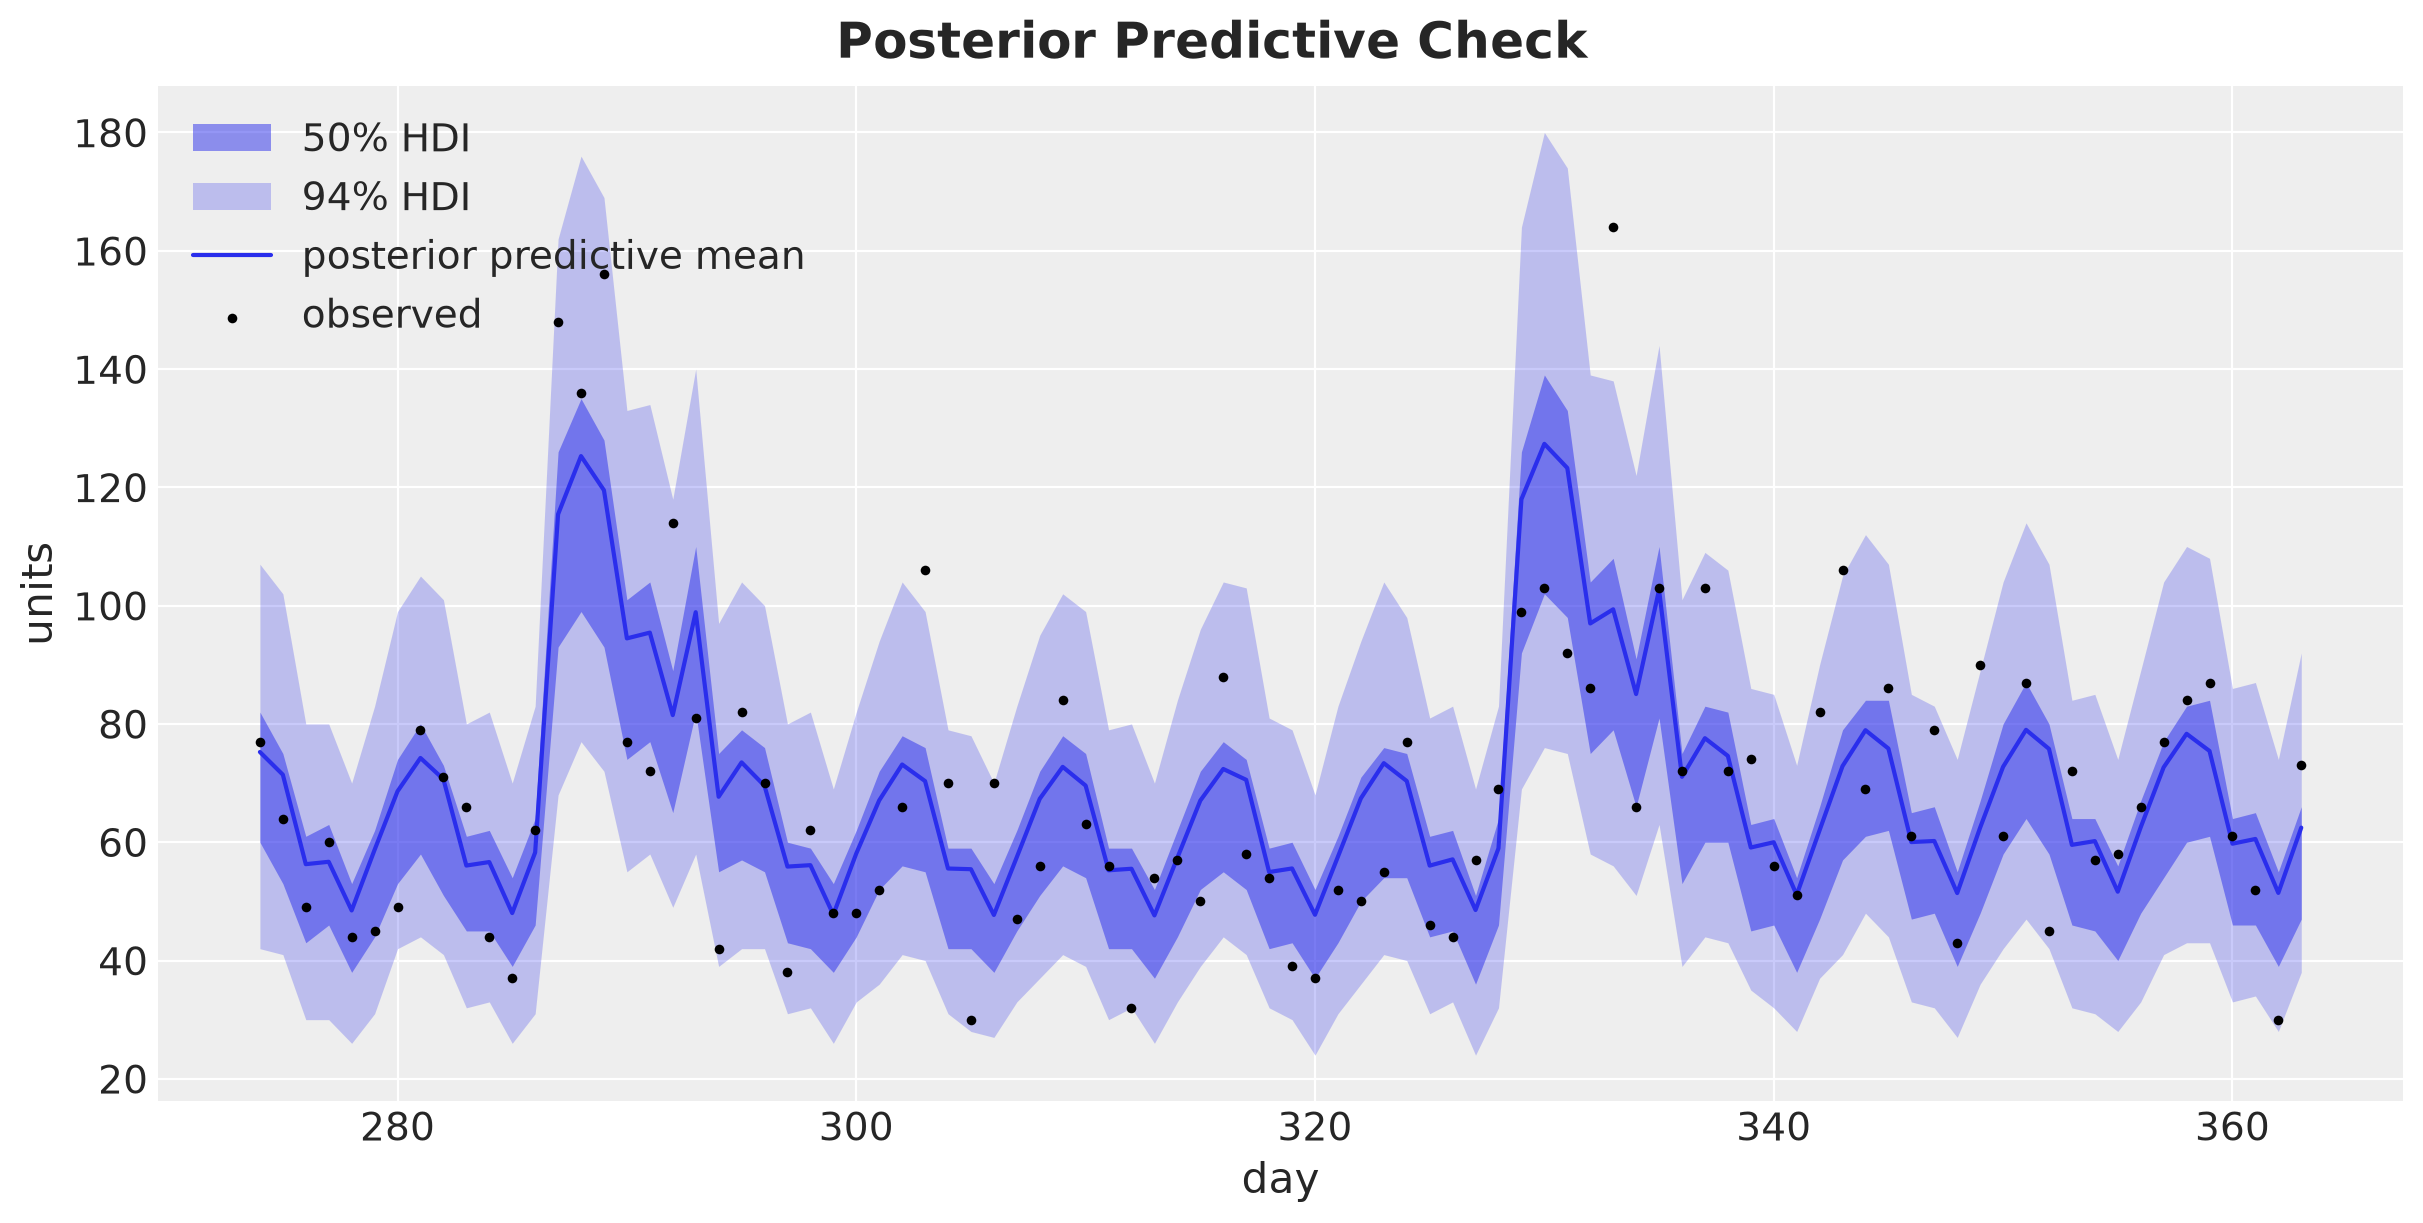

In [17]:
def lighten_bands(pc: az.PlotCollection, x: str) -> None:
    """Set the alpha of the 50% and 94% HDI bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]

    for prob, alpha in [(0.5, 0.5), (HDI_PROB, 0.25)]:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


last_quarter = slice(setup.t_obs - 90, setup.t_obs)
ppc_tree = az.from_dict(
    {
        "posterior_predictive": {
            "obs": idata["posterior_predictive"]["obs"]
            .sel(obs_dim=0)
            .values[:, :, last_quarter]
        },
        "observed_data": {"obs": np.asarray(data[last_quarter, 0])},
        "constant_data": {"day": days[last_quarter].astype(float)},
    },
    coords={"time": days[last_quarter]},
    dims={"obs": ["time"], "day": ["time"]},
)

pc = az.plot_lm(
    ppc_tree,
    x="day",
    y="obs",
    y_obs="obs",
    smooth=False,
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C0"},
        "pe_line": {"color": "C0", "alpha": 1.0},
        "observed_scatter": {"color": "black", "alpha": 1.0, "s": 12},
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "day")
ax = pc.viz["plot"]["day"].item()
pc.viz["ci_band"]["day"].sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} HDI")
pc.viz["ci_band"]["day"].sel(prob=0.5).item().set_label("50% HDI")
pc.viz["pe_line"]["day"].item().set_label("posterior predictive mean")
pc.viz["observed_scatter"]["day"].item().set_label("observed")
ax.legend(loc="upper left")
ax.set(xlabel="day", ylabel="units", title="")
pc.viz["figure"].item().suptitle(
    "Posterior Predictive Check", fontsize=18, fontweight="bold"
);

The band covers $86$ of the $90$ observations, close to the nominal $94\%$, and the mean tracks both the weekly cycle and the two promotion weeks. The model is a reasonable description of the history, so let's move to the horizon.

## Demand Scenarios

`to_datatree` stores the forecast draws as `obs` in the `predictions` group, shaped `(chain, draw, time, obs_dim)`. We flatten the sample dimensions into a scenario matrix of shape $(S, H)$, where each row is one *joint* draw of the $15$ days. We then shuffle the rows and split them. The first $1{,}000$ scenarios are the optimization set that every plan sees. We hold out the remaining $3{,}000$ and use them only to score the plans.

A note on day numbers. The plots keep the day index of the series, so the horizon runs from day $364$ to day $378$. In the text we count the days of the horizon from $1$ to $15$, so day $1$ of the horizon is day $364$ on the plots and the promotion week, days $8$ to $14$ of the horizon, is days $371$ to $377$.

In [18]:
N_SCENARIOS_OPT = 1_000

scenarios = jnp.asarray(
    idata["predictions"]["obs"].values.reshape(-1, setup.horizon), dtype=jnp.float32
)
rng_key, key_split = random.split(rng_key)
scenarios = scenarios[random.permutation(key_split, scenarios.shape[0])]
demand_opt, demand_eval = scenarios[:N_SCENARIOS_OPT], scenarios[N_SCENARIOS_OPT:]

Let's plot the forecast as a fan over the last $60$ days of history. The shaded column is the promotion week in the horizon.

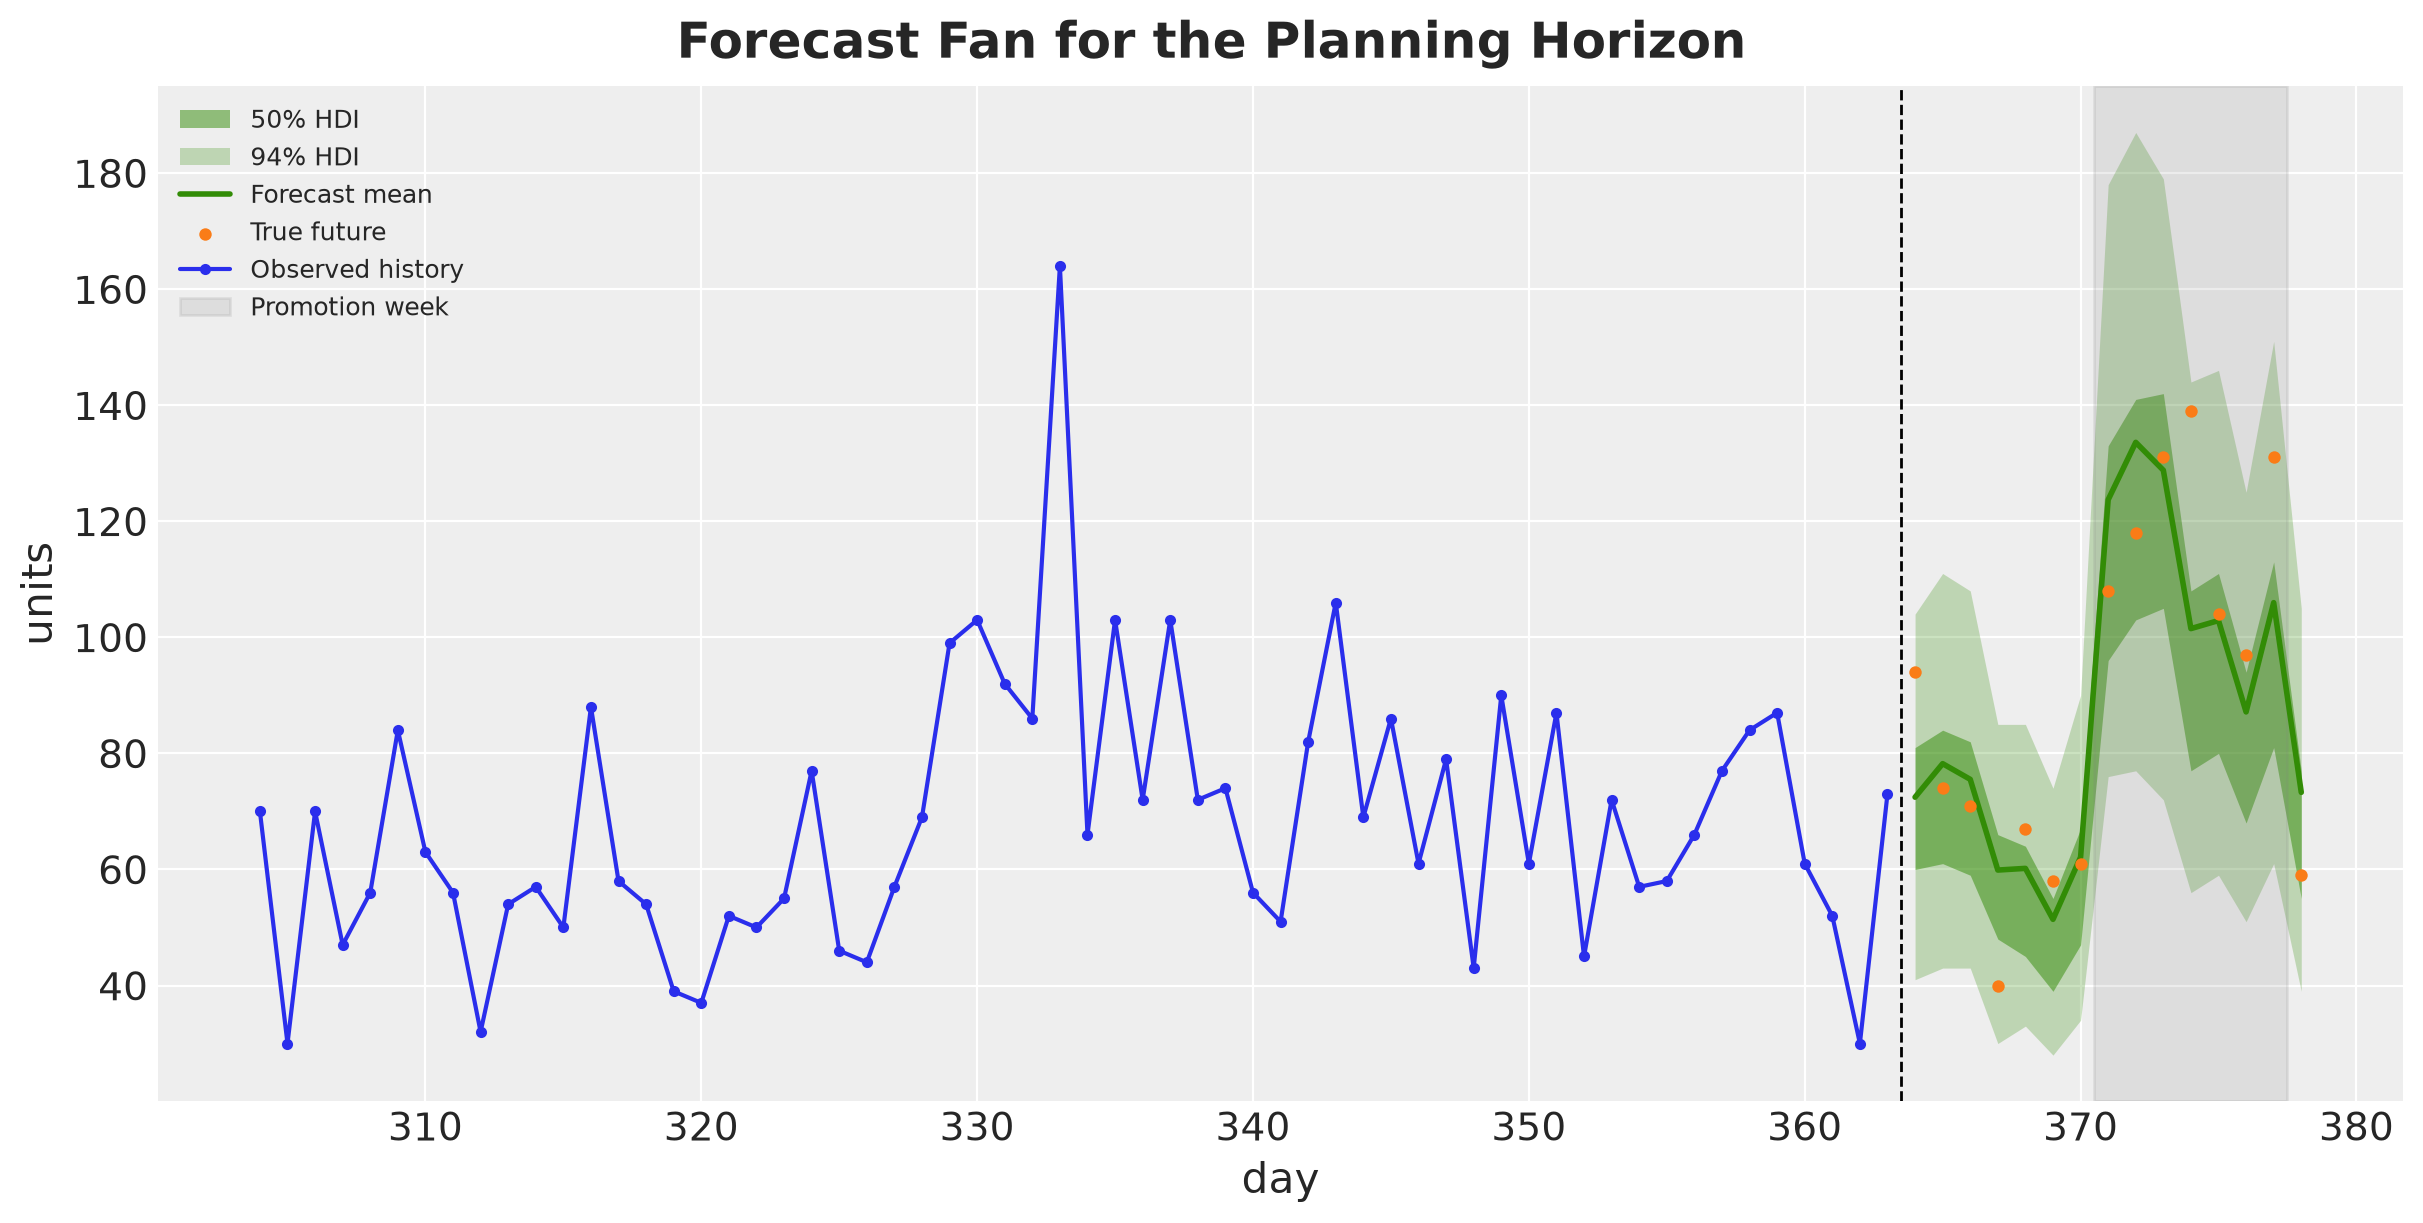

In [19]:
def shade_promotion(ax: plt.Axes) -> None:
    """Shade the promotion days of the horizon."""
    ax.axvspan(
        promo_days_future[0] - 0.5,
        promo_days_future[-1] + 0.5,
        color="gray",
        alpha=0.15,
        label="Promotion week",
    )


forecast_tree = az.from_dict(
    {
        "posterior_predictive": {
            "obs": idata["predictions"]["obs"].sel(obs_dim=0).values
        },
        "observed_data": {"obs": np.asarray(demand_future_true)},
        "constant_data": {"day": days_future.astype(float)},
    },
    coords={"time": days_future},
    dims={"obs": ["time"], "day": ["time"]},
)

pc = az.plot_lm(
    forecast_tree,
    x="day",
    y="obs",
    y_obs="obs",
    smooth=False,
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C2"},
        "pe_line": {"color": "C2", "alpha": 1.0, "linewidth": 2},
        "observed_scatter": {"color": "C1", "alpha": 1.0, "s": 20},
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "day")
ax = pc.viz["plot"]["day"].item()
pc.viz["ci_band"]["day"].sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} HDI")
pc.viz["ci_band"]["day"].sel(prob=0.5).item().set_label("50% HDI")
pc.viz["pe_line"]["day"].item().set_label("Forecast mean")
pc.viz["observed_scatter"]["day"].item().set_label("True future")
last_two_months = slice(setup.t_obs - 60, setup.t_obs)
ax.plot(
    days[last_two_months],
    np.asarray(data[last_two_months, 0]),
    "o-",
    markersize=3,
    color="C0",
    label="Observed history",
)
ax.axvline(setup.t_obs - 0.5, color="black", linestyle="--", linewidth=1)
shade_promotion(ax)
ax.legend(loc="upper left", fontsize=9)
ax.set(xlabel="day", ylabel="units", title="")
pc.viz["figure"].item().suptitle(
    "Forecast Fan for the Planning Horizon", fontsize=18, fontweight="bold"
);

The fan follows the weekly cycle and jumps in the promotion week because the model knows the price path. It widens slowly with the horizon because the level keeps drifting. Next, let's look at $30$ individual scenarios from the optimization set. These paths are what the optimizer sees.

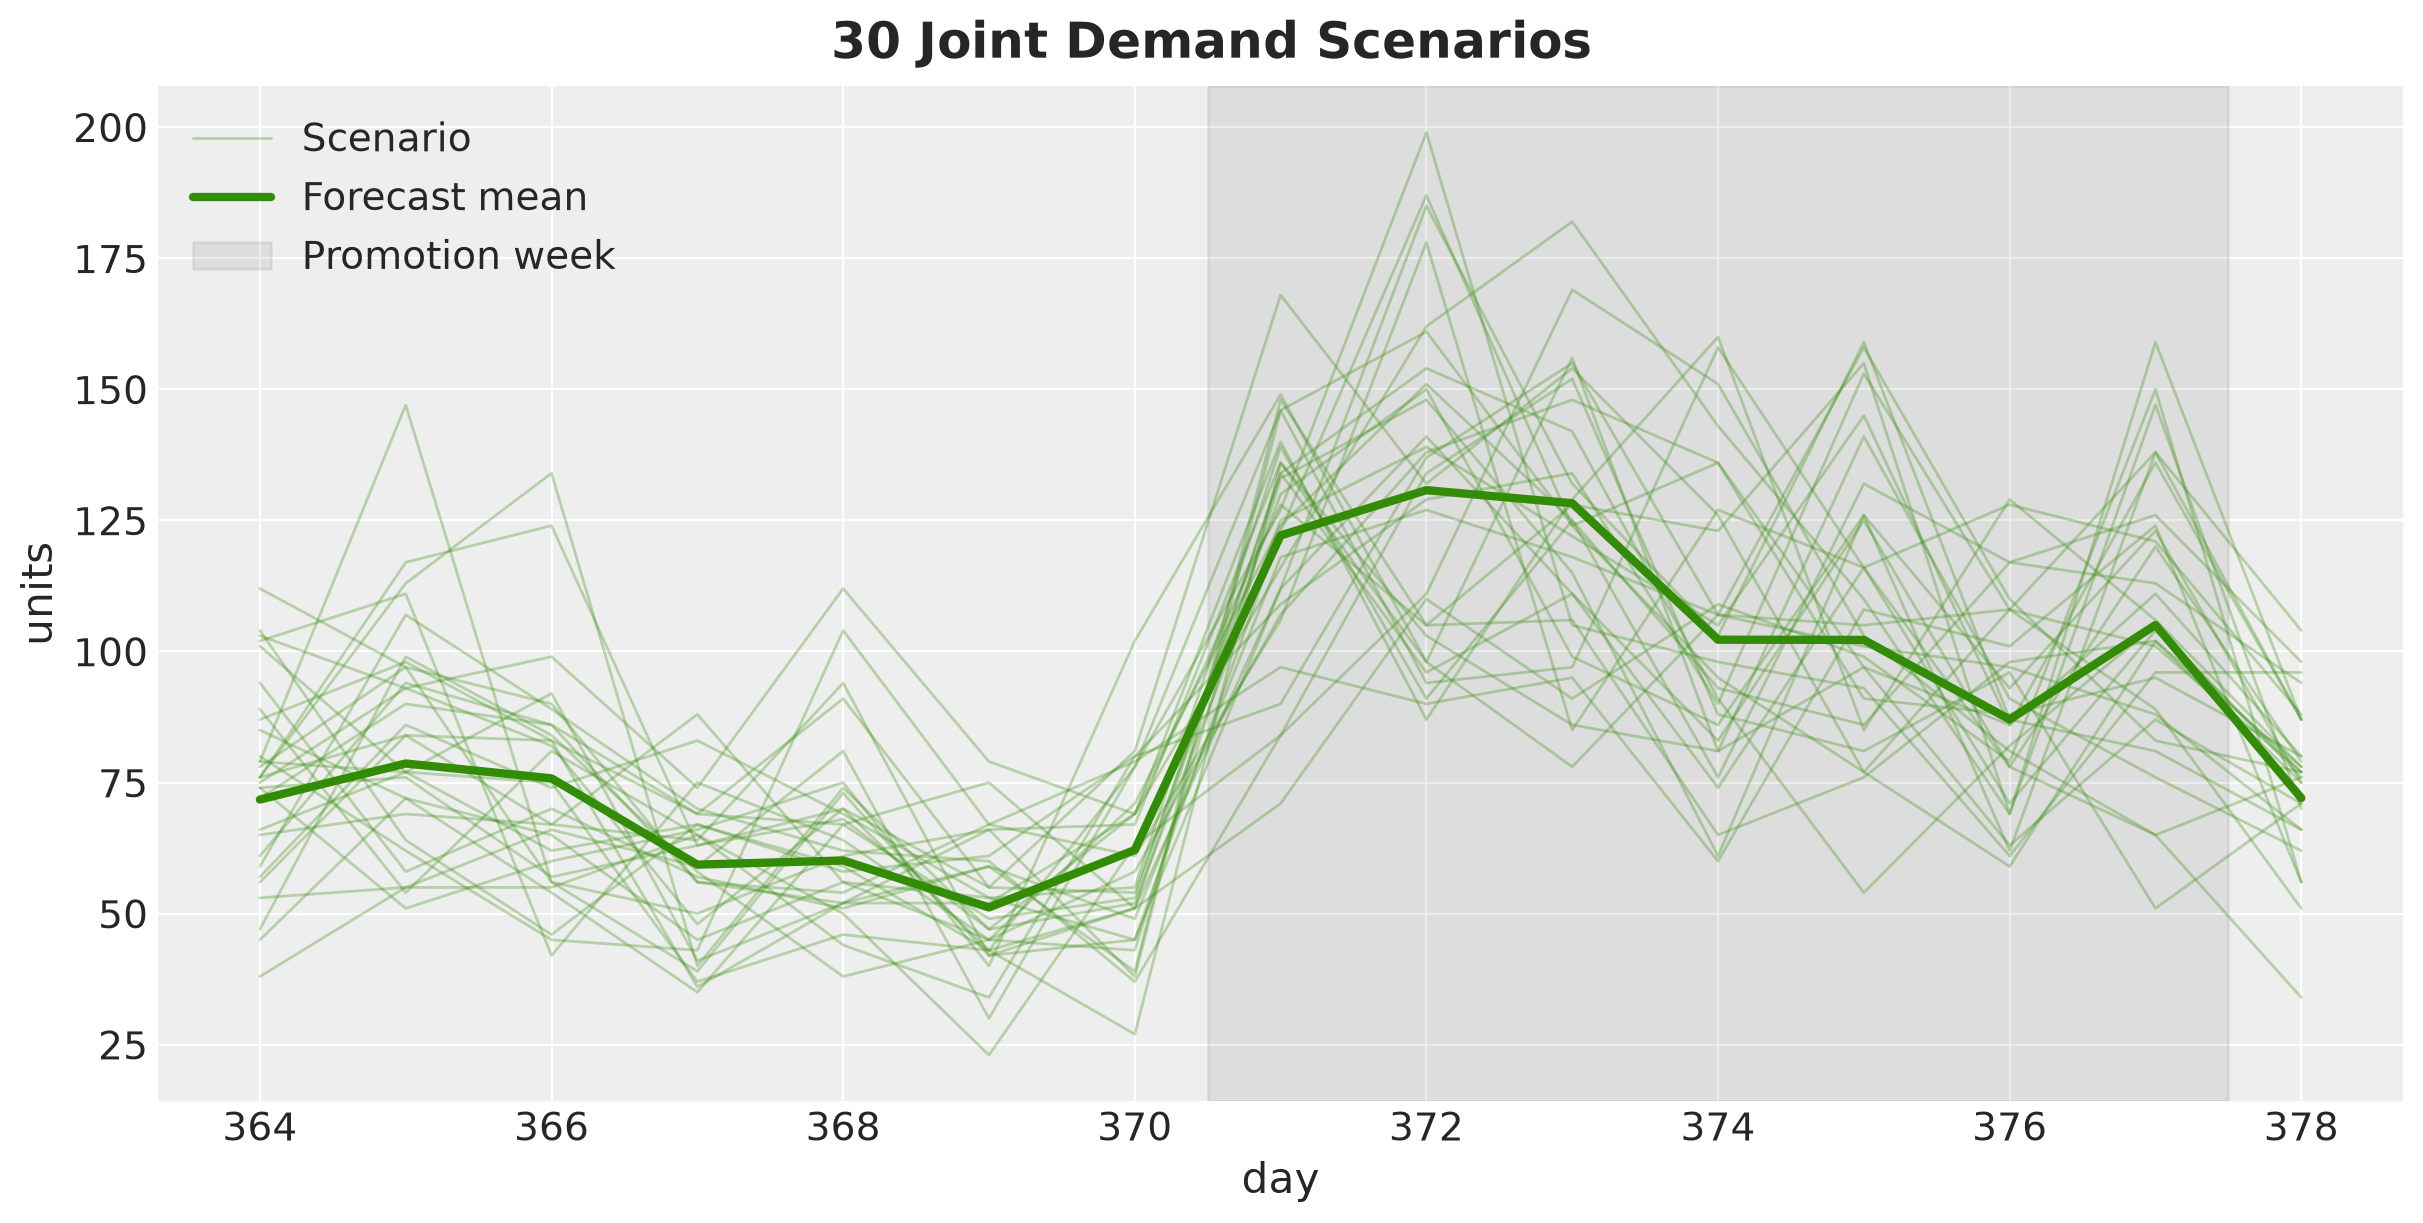

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))
lines = ax.plot(
    days_future, np.asarray(demand_opt[:30]).T, color="C2", alpha=0.3, linewidth=1
)
lines[0].set_label("Scenario")
ax.plot(
    days_future,
    np.asarray(demand_opt.mean(axis=0)),
    color="C2",
    linewidth=3,
    label="Forecast mean",
)
shade_promotion(ax)
ax.legend(loc="upper left")
ax.set(xlabel="day", ylabel="units")
fig.suptitle("30 Joint Demand Scenarios", fontsize=18, fontweight="bold");

Each path is one joint draw of the $15$ days: the optimizer scores a plan against each of them, and the rule decides how to aggregate the scores. The paths are noisy around the mean, and they share the level and the promotion lift.

Why do we insist on joint draws? With lost sales, the stock that a scenario carries into day $t$ is what is left of the earlier days of the same scenario, so a plan is scored against whole paths, and the buffer it carries has to cover the demand of several consecutive days. The shared level and the shared parameters make the days positively correlated, and only joint draws carry that correlation. We check in the evaluation section what a plan built on scenarios without that correlation does.

## Inventory Simulator

The loss $L(a, D)$ is a recursion over days, so we write it as a `jax.lax.scan` that carries the stock on hand. Each step sells what it can, records the lost sales and the leftover, and charges the two costs. The scan returns the loss, the stock path and the lost sales path, since the evaluation needs all three. Vectorizing over scenarios is one `jax.vmap` with `in_axes=(None, 0, None)`: the plan is shared, the demand path is batched. The `problem` tuple holds Python floats, so we mark it static under `jax.jit`. A `Scalar` is a float array with no axes.

In [21]:
Scalar = Float[Array, ""]


def simulate(
    orders: Float[Array, " horizon"], demand: Float[Array, " horizon"], problem: Problem
) -> tuple[Scalar, Float[Array, " horizon"], Float[Array, " horizon"]]:
    """Loss, stock path and lost sales path of one plan against one demand path."""

    def step(
        inventory: Scalar, inputs: tuple[Scalar, Scalar]
    ) -> tuple[Scalar, tuple[Scalar, Scalar, Scalar]]:
        # carry: stock left at the end of the previous day
        # inputs: today's order and today's demand
        order_t, demand_t = inputs
        available = inventory + order_t  # y_t, the stock available today
        sales_t = jnp.minimum(available, demand_t)
        lost_t = demand_t - sales_t  # demand that found an empty shelf
        inventory = available - sales_t  # leftover, never negative
        cost_t = problem.holding_cost * inventory + problem.lost_sales_cost * lost_t
        return inventory, (inventory, lost_t, cost_t)

    initial_inventory = jnp.asarray(problem.initial_inventory, dtype=orders.dtype)
    _, (inventory_path, lost_path, cost_path) = jax.lax.scan(
        step, initial_inventory, (orders, demand)
    )
    return cost_path.sum(), inventory_path, lost_path


# one plan against a batch of demand paths
simulate_scenarios = jax.jit(
    jax.vmap(simulate, in_axes=(None, 0, None)), static_argnames="problem"
)

We also need the tail average. For $S$ equally weighted scenarios, $\text{CVaR}_\alpha$ is the mean of the $k = \alpha S$ largest losses, which `jax.lax.top_k` selects in one call. We keep $k$ as a Python integer so that the shape is static.

In [22]:
def cvar(losses: Float[Array, " scenarios"], alpha: float) -> Scalar:
    """Mean of the k = alpha * S largest losses, with k an integer."""
    k = max(1, round(alpha * losses.shape[0]))  # static: top_k needs a Python integer
    worst, _ = jax.lax.top_k(losses, k)  # the k largest losses, no sort needed
    return worst.mean()

Let's test the simulator on the first of the four plans, the mean forecast plan. We build it with the forward pass described above, which also gives the chance-constrained plan and the myopic newsvendor plan later on. The function walks through the days with a `jax.lax.scan` over the scenario matrix: on day $t$ it computes the shortfall $D_t - I_{t-1}$ of every scenario, orders the `prob` quantile of the shortfall (clipped at zero), and carries the leftover stock of every scenario into the next day.

The mean forecast plan is the same forward pass on a single path, the mean of the scenarios, where the quantile level does not matter. Against that path the plan leaves nothing on the shelf: the initial stock covers most of day one and every later order equals the mean demand of its day. We keep the mean demand path, since the order plan figure uses it.

In [23]:
def plan_order_up_to(
    demand: Float[Array, "scenarios horizon"], prob: float, problem: Problem
) -> Float[Array, " horizon"]:
    """Daily orders that cover the shortfall in a fraction prob of the scenarios."""

    def step(
        inventory: Float[Array, " scenarios"], demand_t: Float[Array, " scenarios"]
    ) -> tuple[Float[Array, " scenarios"], Scalar]:
        # carry: stock every scenario brings into the day; input: the day's demand
        shortfall = demand_t - inventory
        # the smallest order that leaves at most a fraction 1 - prob of scenarios short
        order_t = jnp.maximum(jnp.quantile(shortfall, prob, method="inverted_cdf"), 0.0)
        # the leftover carried into the next day, unmet demand is lost
        inventory = jnp.maximum(inventory + order_t - demand_t, 0.0)
        return inventory, order_t

    initial_inventory = jnp.full(
        demand.shape[0], problem.initial_inventory, dtype=demand.dtype
    )
    _, orders = jax.lax.scan(step, initial_inventory, demand.T)
    return orders


mean_demand_opt = demand_opt.mean(axis=0)
orders_mean = plan_order_up_to(mean_demand_opt[None, :], 0.5, problem)

This plan has zero loss on the mean path by construction. Let's score it on the optimization scenarios, plot the distribution of its loss and mark the expected loss, the value at risk and the conditional value at risk.

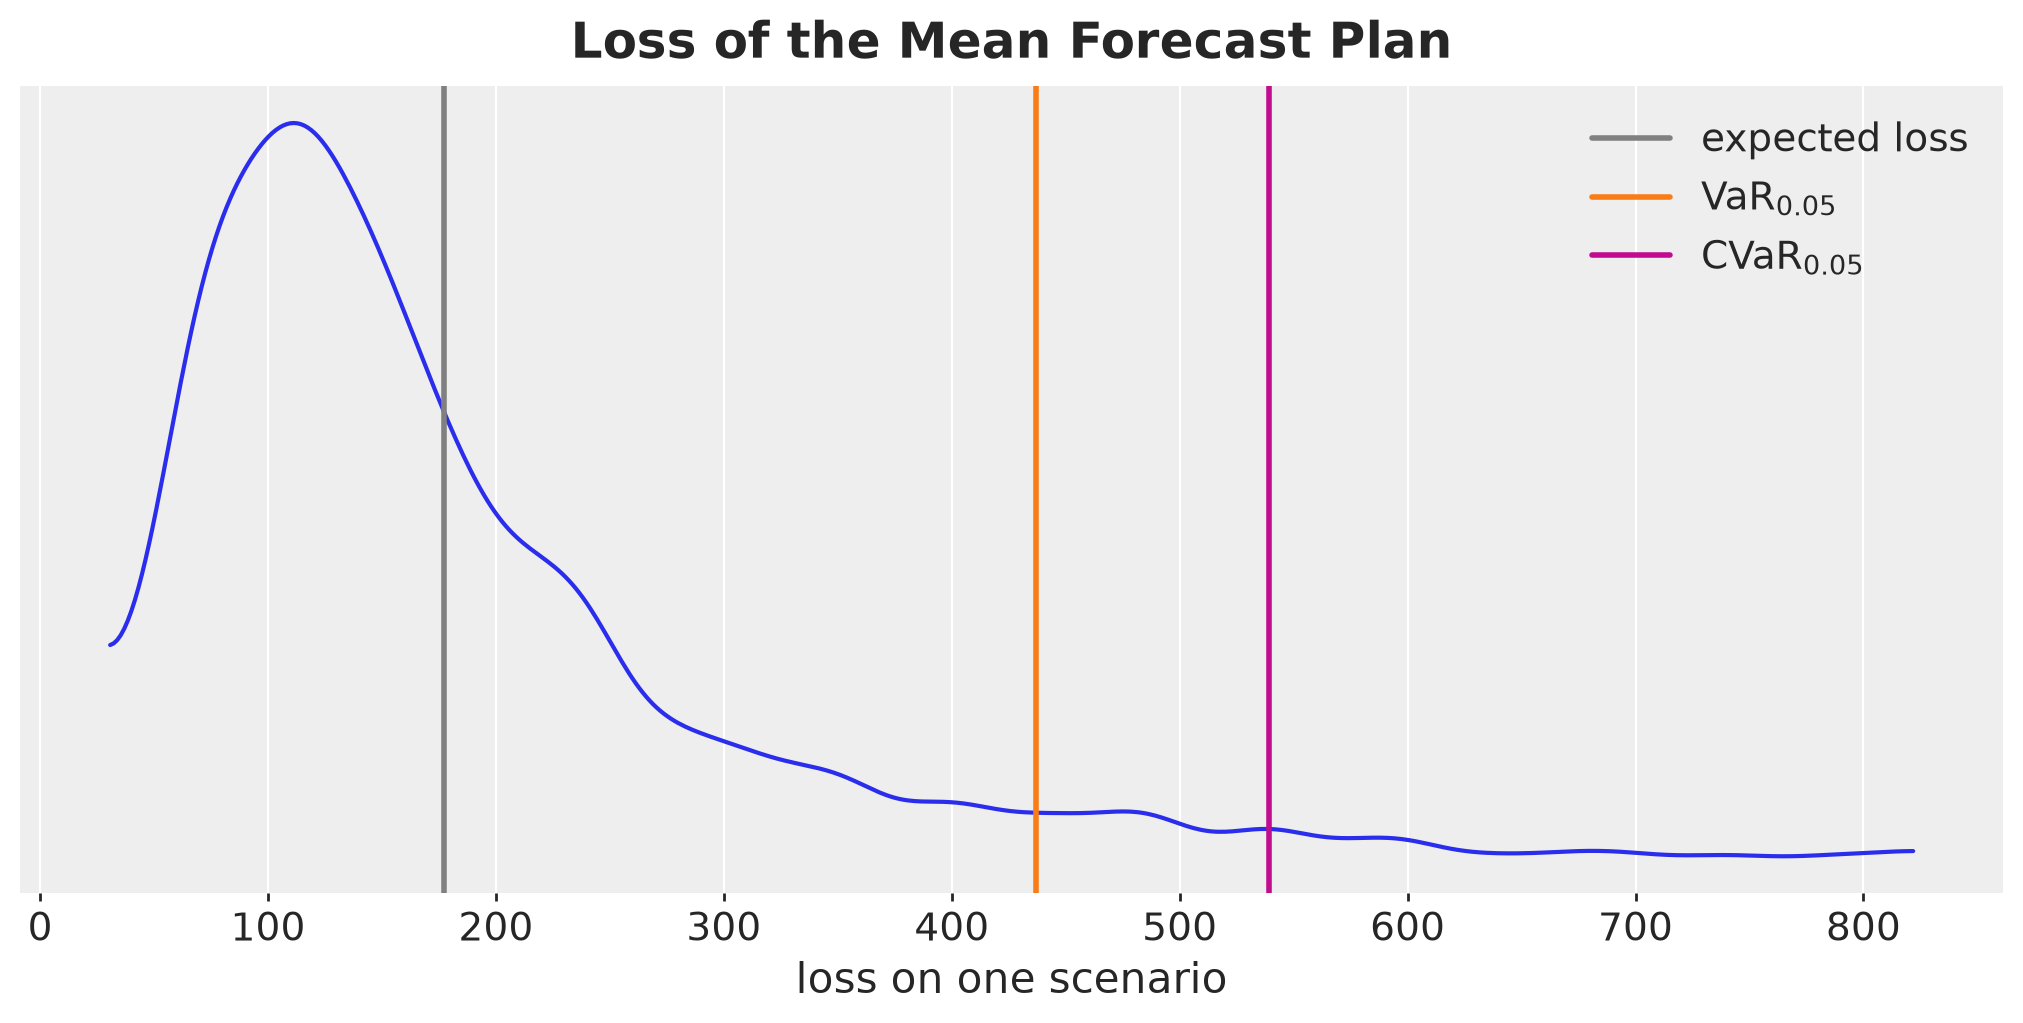

In [24]:
losses_mean_plan, _, _ = simulate_scenarios(orders_mean, demand_opt, problem)

pc = az.plot_dist(
    xr.Dataset({"loss": (("sample",), np.asarray(losses_mean_plan))}),
    sample_dims=["sample"],
    kind="kde",
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
    figure_kwargs={"figsize": (10, 5)},
)
ax = pc.viz["plot"]["loss"].item()
ax.axvline(
    float(losses_mean_plan.mean()), color="gray", linewidth=2, label="expected loss"
)
ax.axvline(
    float(jnp.quantile(losses_mean_plan, 1 - problem.alpha)),
    color="C1",
    linewidth=2,
    label=VAR_LABEL,
)
ax.axvline(
    float(cvar(losses_mean_plan, problem.alpha)),
    color="C3",
    linewidth=2,
    label=CVAR_LABEL,
)
ax.legend(loc="upper right")
ax.set(xlabel="loss on one scenario", title="")
pc.viz["figure"].item().suptitle(
    "Loss of the Mean Forecast Plan", fontsize=18, fontweight="bold"
);

The loss distribution has the shape of the concept plot above: most scenarios cost little, and a long right tail of high-demand scenarios pushes the tail average far beyond the expected loss. The plan that costs nothing on the mean path has an expected loss of $177$ over the scenarios, a value at risk of $437$ and a conditional value at risk of $539$, three times the expected loss. We score it on the held-out scenarios in the evaluation section.

## Decision Plans

The mean forecast plan is built. The chance-constrained plan and the myopic newsvendor plan come from the same forward pass with a quantile level, and the expected cost plan and the CVaR plan go through the JAX solver.

### Chance-Constrained Orders

We run the forward pass on the joint scenarios with the quantile level $1 - \alpha$. `method="inverted_cdf"` returns the smallest value with at least a fraction $1 - \alpha$ of the scenarios at or below it, so on every day the plan covers the shortfall of at least $95\%$ of the optimization scenarios with the smallest possible order.

In [25]:
orders_cc = plan_order_up_to(demand_opt, 1 - problem.alpha, problem)

### Expected Cost Orders

Only the CVaR plan needs an optimizer, and we solve the $\lambda = 0$ case with it as well so that the linear program below checks both solves. The objective $\text{E}[L] + \lambda \, \text{CVaR}_\alpha(L)$ is convex in $a$, which we show in the cross check section, and the only constraint is $a \geq 0$.

We use projected gradient descent with Adam: after each step we clip the orders at zero, which is the Euclidean projection onto the feasible set. The whole optimization loop is a `jax.lax.scan` inside `jax.jit`, so there is no Python overhead per step, and the same function vectorizes over $\lambda$ with `jax.vmap`.

The objective is piecewise linear, so the gradient is a subgradient and Adam oscillates around the kinks unless the step size shrinks. We use a one-cycle learning rate schedule (warm up, then decay) and chain it with `optax.contrib.reduce_on_plateau`, which halves the step size whenever the objective stops improving. The plateau rule needs the objective value, so we pass it to `optimizer.update`. The solver returns the objective and the effective step size at every step, and we confirm the optimum against a linear program below.

In [26]:
def objective(
    orders: Float[Array, " horizon"],
    demand: Float[Array, "scenarios horizon"],
    lam: ScalarLike,
    problem: Problem,
) -> Scalar:
    """Expected loss plus lam times the CVaR of the loss over the scenarios."""
    losses, _, _ = simulate_scenarios(orders, demand, problem)
    return losses.mean() + lam * cvar(losses, problem.alpha)


def solve(
    demand: Float[Array, "scenarios horizon"],
    lam: ScalarLike,
    orders_init: Float[Array, " horizon"],
    problem: Problem,
    n_steps: int = 3_000,
    learning_rate: float = 1.0,
) -> tuple[
    Float[Array, " horizon"], Float[Array, " n_steps"], Float[Array, " n_steps"]
]:
    """Projected Adam on the expected cost plus lam times CVaR, as a lax.scan."""
    # one cycle: warm up to the peak rate over the first 30% of the steps, then decay
    schedule = optax.linear_onecycle_schedule(
        transition_steps=n_steps,
        peak_value=learning_rate,
        pct_start=0.3,
        pct_final=0.85,
        div_factor=2,
        final_div_factor=3,
    )
    optimizer = optax.chain(
        optax.adam(learning_rate=schedule),
        # average the objective over blocks of 10 steps; halve the step size after
        # 50 blocks (500 steps) without a 0.1% improvement, then wait 50 blocks
        optax.contrib.reduce_on_plateau(
            factor=0.5,
            patience=50,
            cooldown=50,
            accumulation_size=10,
            rtol=1e-3,
            min_scale=1e-2,
        ),
    )
    value_and_grad = jax.value_and_grad(objective)

    def step(
        carry: tuple[Float[Array, " horizon"], optax.OptState], _: None
    ) -> tuple[tuple[Float[Array, " horizon"], optax.OptState], tuple[Scalar, Scalar]]:
        orders, opt_state = carry
        value, grads = value_and_grad(orders, demand, lam, problem)
        # the plateau rule reads the objective, so we pass it as a keyword
        updates, opt_state = optimizer.update(grads, opt_state, orders, value=value)
        orders = jnp.maximum(orders + updates, 0.0)  # projection onto a >= 0
        scale = optax.tree_utils.tree_get(opt_state, "scale")  # plateau multiplier
        return (orders, opt_state), (value, scale)

    (orders, _), (values, scales) = jax.lax.scan(
        step, (orders_init, optimizer.init(orders_init)), None, length=n_steps
    )
    step_sizes = jax.vmap(schedule)(jnp.arange(n_steps)) * scales
    return orders, values, step_sizes


solve_jit = jax.jit(solve, static_argnames=("problem", "n_steps"))

We start from the mean forecast plan and set $\lambda = 0$. We also build the myopic newsvendor plan with the forward pass at the critical fractile and compare the two, with the expected loss of each plan on the optimization scenarios in the legend.

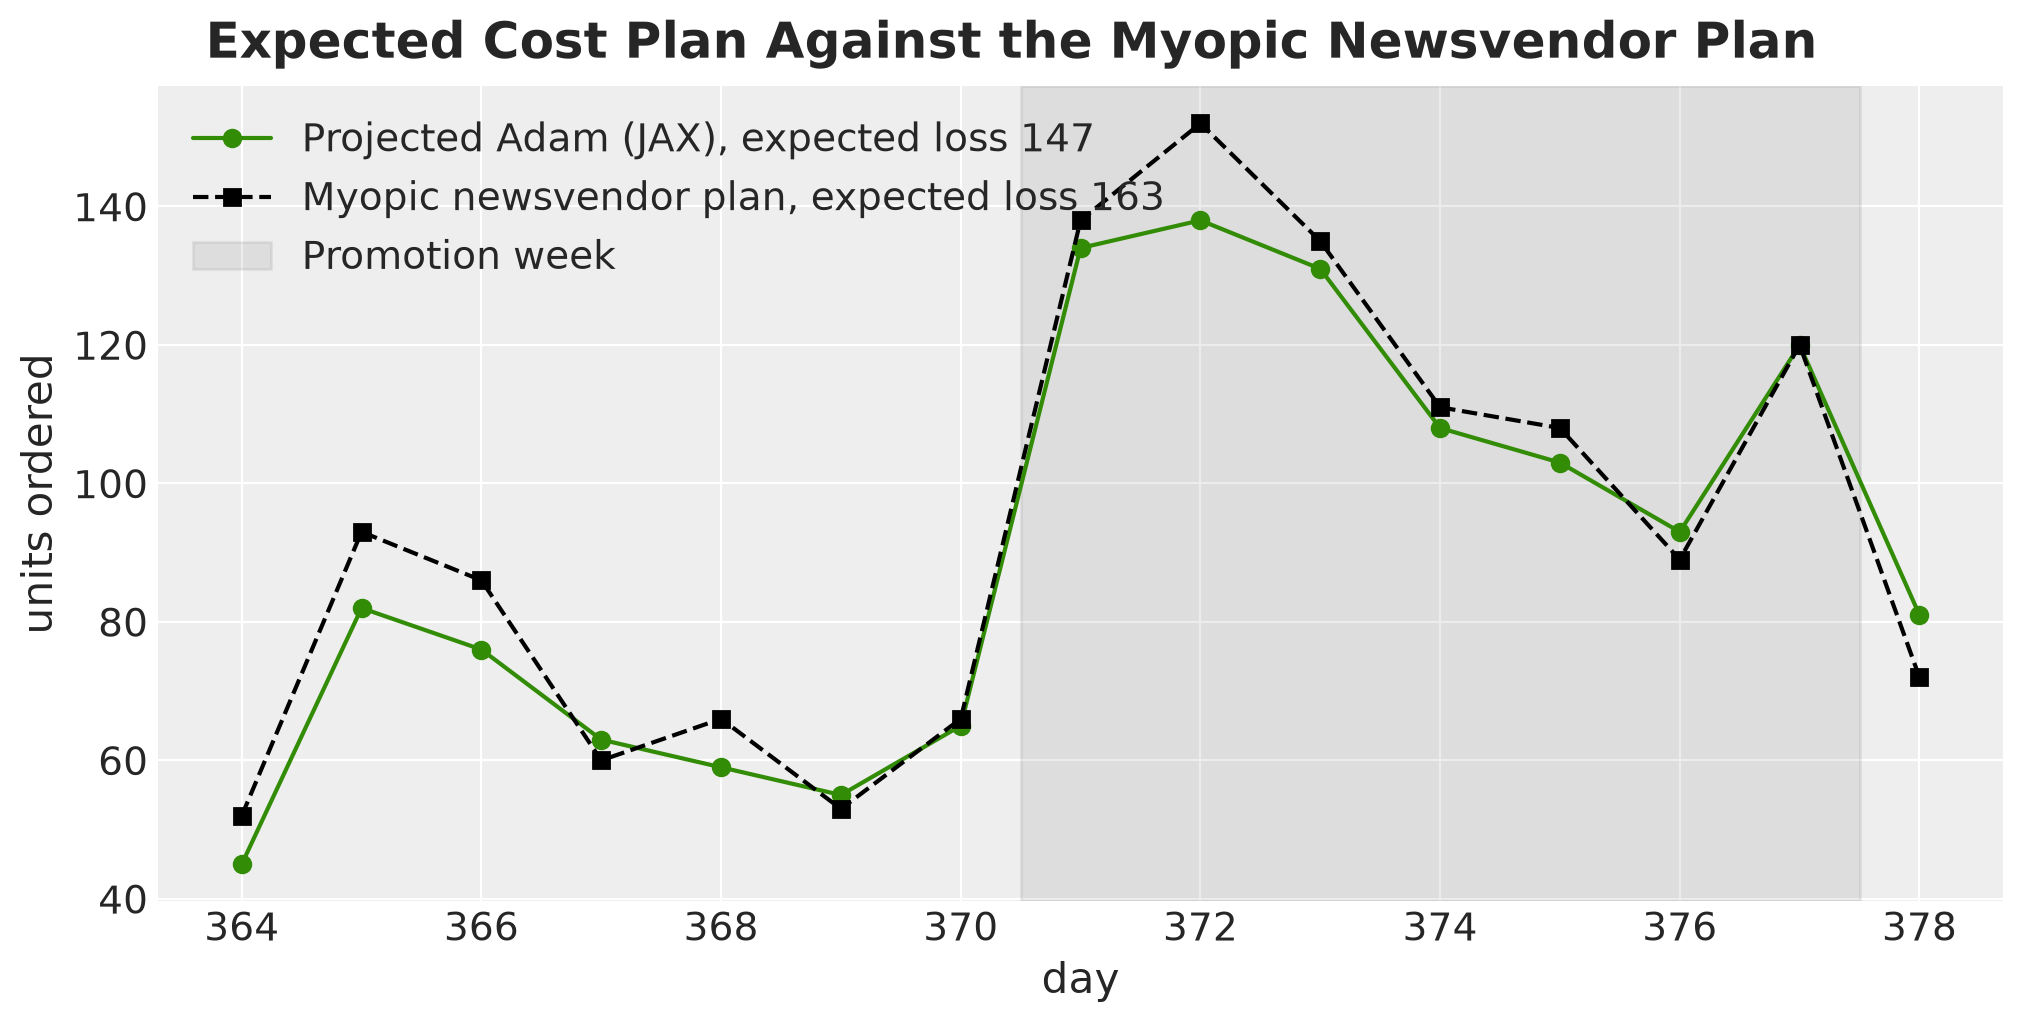

In [27]:
orders_saa, trace_saa, step_sizes_saa = solve_jit(demand_opt, 0.0, orders_mean, problem)
orders_newsvendor = plan_order_up_to(demand_opt, critical_fractile, problem)
cost_saa = objective(orders_saa, demand_opt, 0.0, problem)
cost_newsvendor = objective(orders_newsvendor, demand_opt, 0.0, problem)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    days_future,
    np.asarray(orders_saa),
    "o-",
    color="C2",
    label=f"Projected Adam (JAX), expected loss {cost_saa:.0f}",
)
ax.plot(
    days_future,
    np.asarray(orders_newsvendor),
    "s--",
    color="black",
    label=f"Myopic newsvendor plan, expected loss {cost_newsvendor:.0f}",
)
shade_promotion(ax)
ax.legend(loc="upper left")
ax.set(xlabel="day", ylabel="units ordered")
fig.suptitle(
    "Expected Cost Plan Against the Myopic Newsvendor Plan",
    fontsize=18,
    fontweight="bold",
);

The two plans follow the same shape, and the myopic plan orders more on most days and in total, $1{,}401$ units against $1{,}353$. The extra stock costs $11\%$ in expected loss, $163$ against $147$ on the optimization scenarios.

The single-period rule charges a leftover unit one day of holding, while in the multi-period problem the unit stays on the shelf until a customer buys it, so the optimizer keeps less stock. It orders more than the myopic rule on four days only, by the largest margin on the last day, where a leftover is charged once. Note also that the myopic plan is almost the chance-constrained plan: both come from the same forward pass, at the quantile levels $0.952$ and $0.95$.

### CVaR Orders

Now we put a price on the tail with $\lambda = 1$: one unit of average loss in the worst $5\%$ of scenarios counts as much as one unit of expected loss.

In [28]:
orders_cvar, trace_cvar, step_sizes_cvar = solve_jit(
    demand_opt, 1.0, orders_mean, problem
)

Let's look at the optimizer traces for both solves: the objective on top and the effective step size, the schedule times the plateau multiplier, below it.

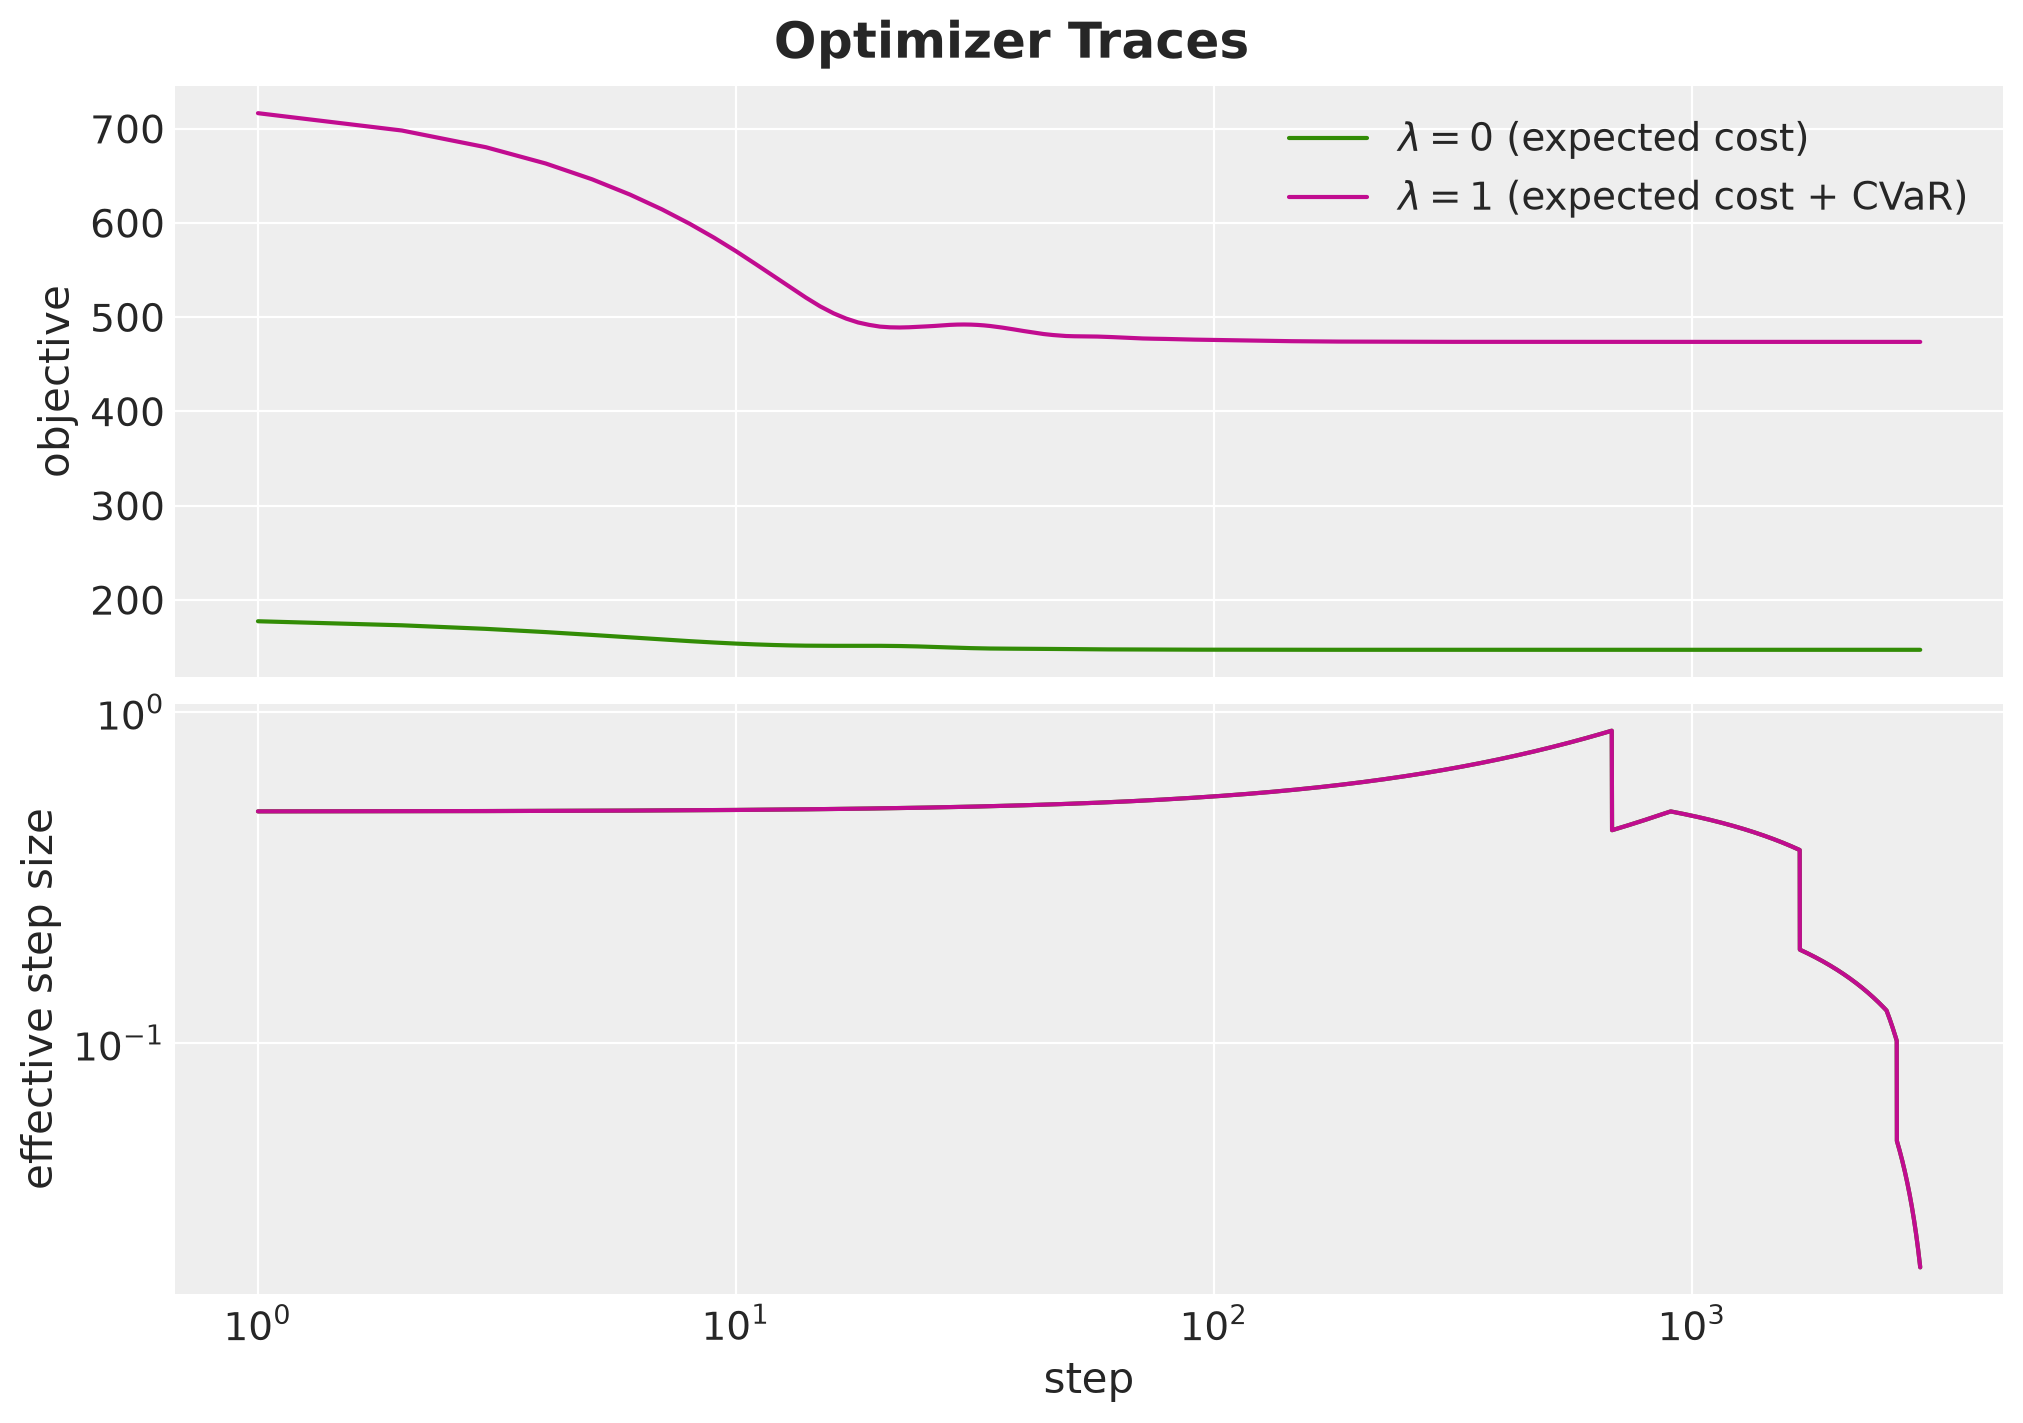

In [29]:
steps = np.arange(1, trace_saa.shape[0] + 1)

fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, layout="constrained")
ax = axes[0]
ax.plot(
    steps, np.asarray(trace_saa), color="C2", label=r"$\lambda = 0$ (expected cost)"
)
ax.plot(
    steps,
    np.asarray(trace_cvar),
    color="C3",
    label=r"$\lambda = 1$ (expected cost + CVaR)",
)
ax.legend()
ax.set(ylabel="objective", xscale="log")
ax = axes[1]
ax.plot(steps, np.asarray(step_sizes_saa), color="C2")
ax.plot(steps, np.asarray(step_sizes_cvar), color="C3")
ax.set(xlabel="step", ylabel="effective step size", yscale="log")
fig.suptitle("Optimizer Traces", fontsize=18, fontweight="bold");

Both objectives drop within the first $50$ steps and improve slowly after that, down to $147$ for the expected cost and $474$ for the expected cost plus CVaR. The step size rises with the one-cycle schedule toward its peak at step $900$. The plateau rule cuts in before the peak, near step $700$, because the objective no longer improves, and halves the step size three times in total, about $1{,}000$ steps apart, which is the patience plus the cooldown. The final step size of $0.02$ units lets the iterates settle. The two solves share the same step size path, so the two lines of the lower panel coincide.

We now have the four plans, so let's collect them in a list of `Plan` tuples and compare them. We fix one color per plan and use it in every figure that follows. The shaded column is again the promotion week.

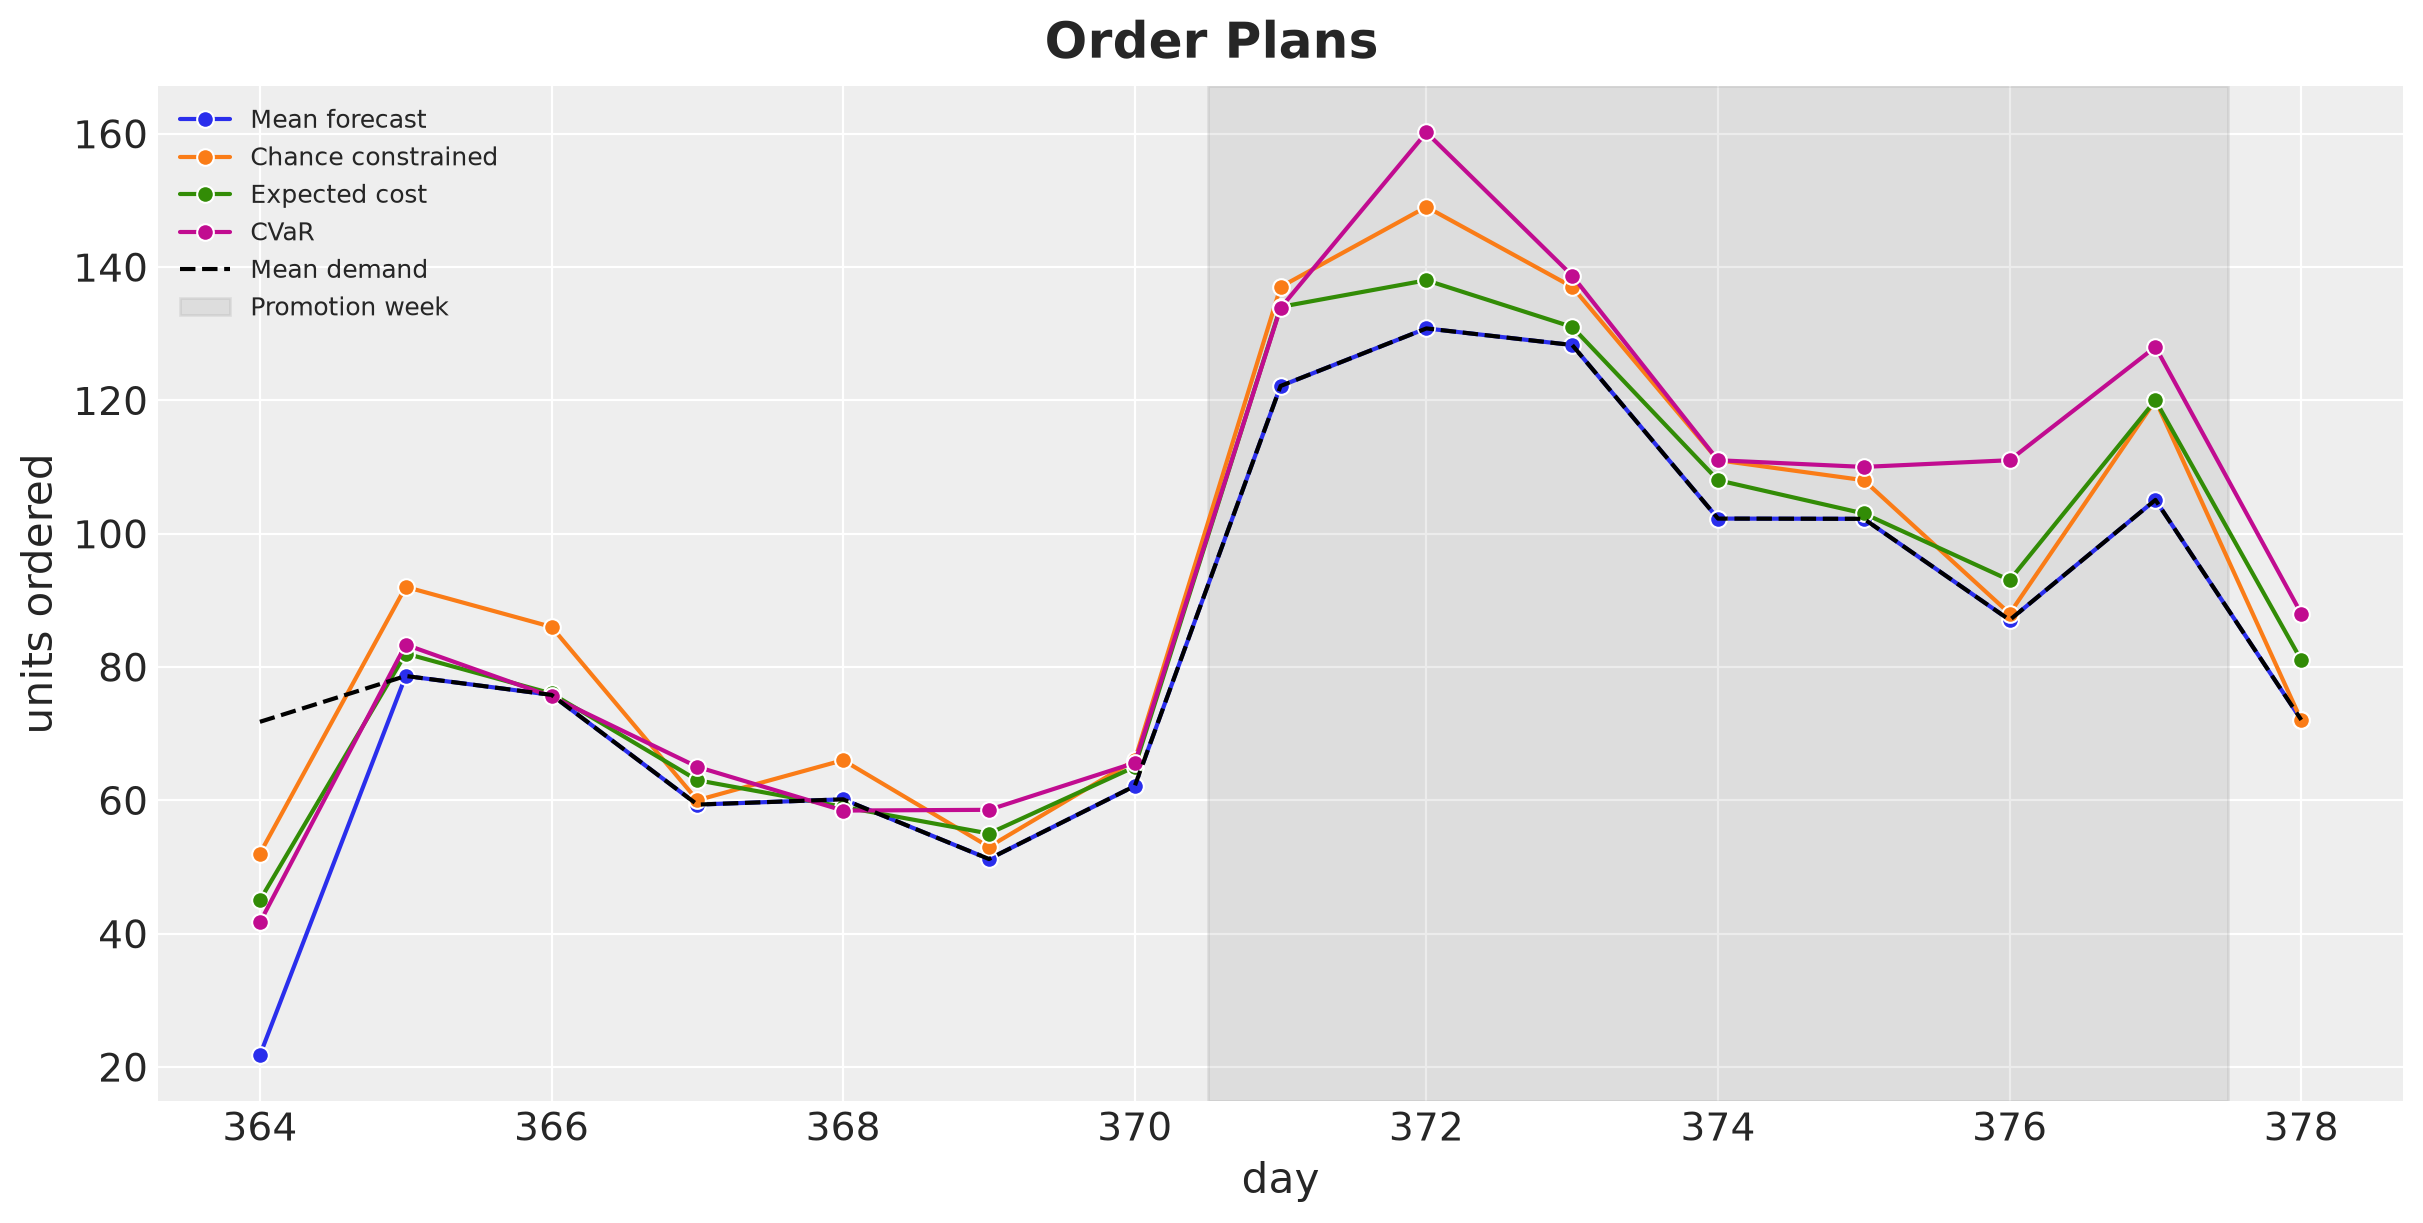

In [30]:
class Plan(NamedTuple):
    """One order plan with its name."""

    name: str
    orders: Float[Array, " horizon"]


plans = [
    Plan("Mean forecast", orders_mean),
    Plan("Chance constrained", orders_cc),
    Plan("Expected cost", orders_saa),
    Plan("CVaR", orders_cvar),
]
plan_names = [plan.name for plan in plans]
PLAN_COLORS = {name: f"C{i}" for i, name in enumerate(plan_names)}
orders_long = pl.DataFrame(
    {
        "plan": np.repeat(plan_names, setup.horizon),
        "day": np.tile(days_future, len(plans)),
        "orders": np.concatenate([np.asarray(plan.orders) for plan in plans]),
    }
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=orders_long,
    x="day",
    y="orders",
    hue="plan",
    hue_order=plan_names,
    palette=PLAN_COLORS,
    marker="o",
    ax=ax,
)
ax.plot(
    days_future,
    np.asarray(mean_demand_opt),
    color="black",
    linestyle="--",
    label="Mean demand",
)
shade_promotion(ax)
ax.legend(loc="upper left", fontsize=9)
ax.set(xlabel="day", ylabel="units ordered")
fig.suptitle("Order Plans", fontsize=18, fontweight="bold");

The mean forecast plan follows the mean demand, with a first order of $22$ units because the $50$ units of initial stock cover most of day one. The three other plans order a buffer, and every plan orders more in the promotion week. The buffer sits in the stock available, not in every single order: on day one the three plans order $42$ to $52$ units, below the mean demand of $72$, because the initial stock covers the rest.

The buffer exists because every plan is fixed in advance, so it has to hedge the demand of several days at once, and because a lost sale costs twenty times what a leftover unit costs on one day.

The chance-constrained plan orders the most in the first week and carries the largest cumulative order through day $12$. The CVaR plan orders the most in the second week, which is where the high-demand scenarios of the tail separate from the rest, and from day $13$ on its cumulative orders are the largest of the four. Its path is less smooth than the chance-constrained plan because the $50$ scenarios of the tail shape it.

## Out of Sample Evaluation

We score every plan on the $3{,}000$ held-out scenarios. Besides the expected loss and the tail average, we report the stockout probability per day (the fraction of scenario and day pairs with a lost sale, which is the average over days of the per-day probability) and the probability of at least one stockout in the horizon. We simulate each plan once and keep the losses, the stock paths and the lost sales for the figures below.

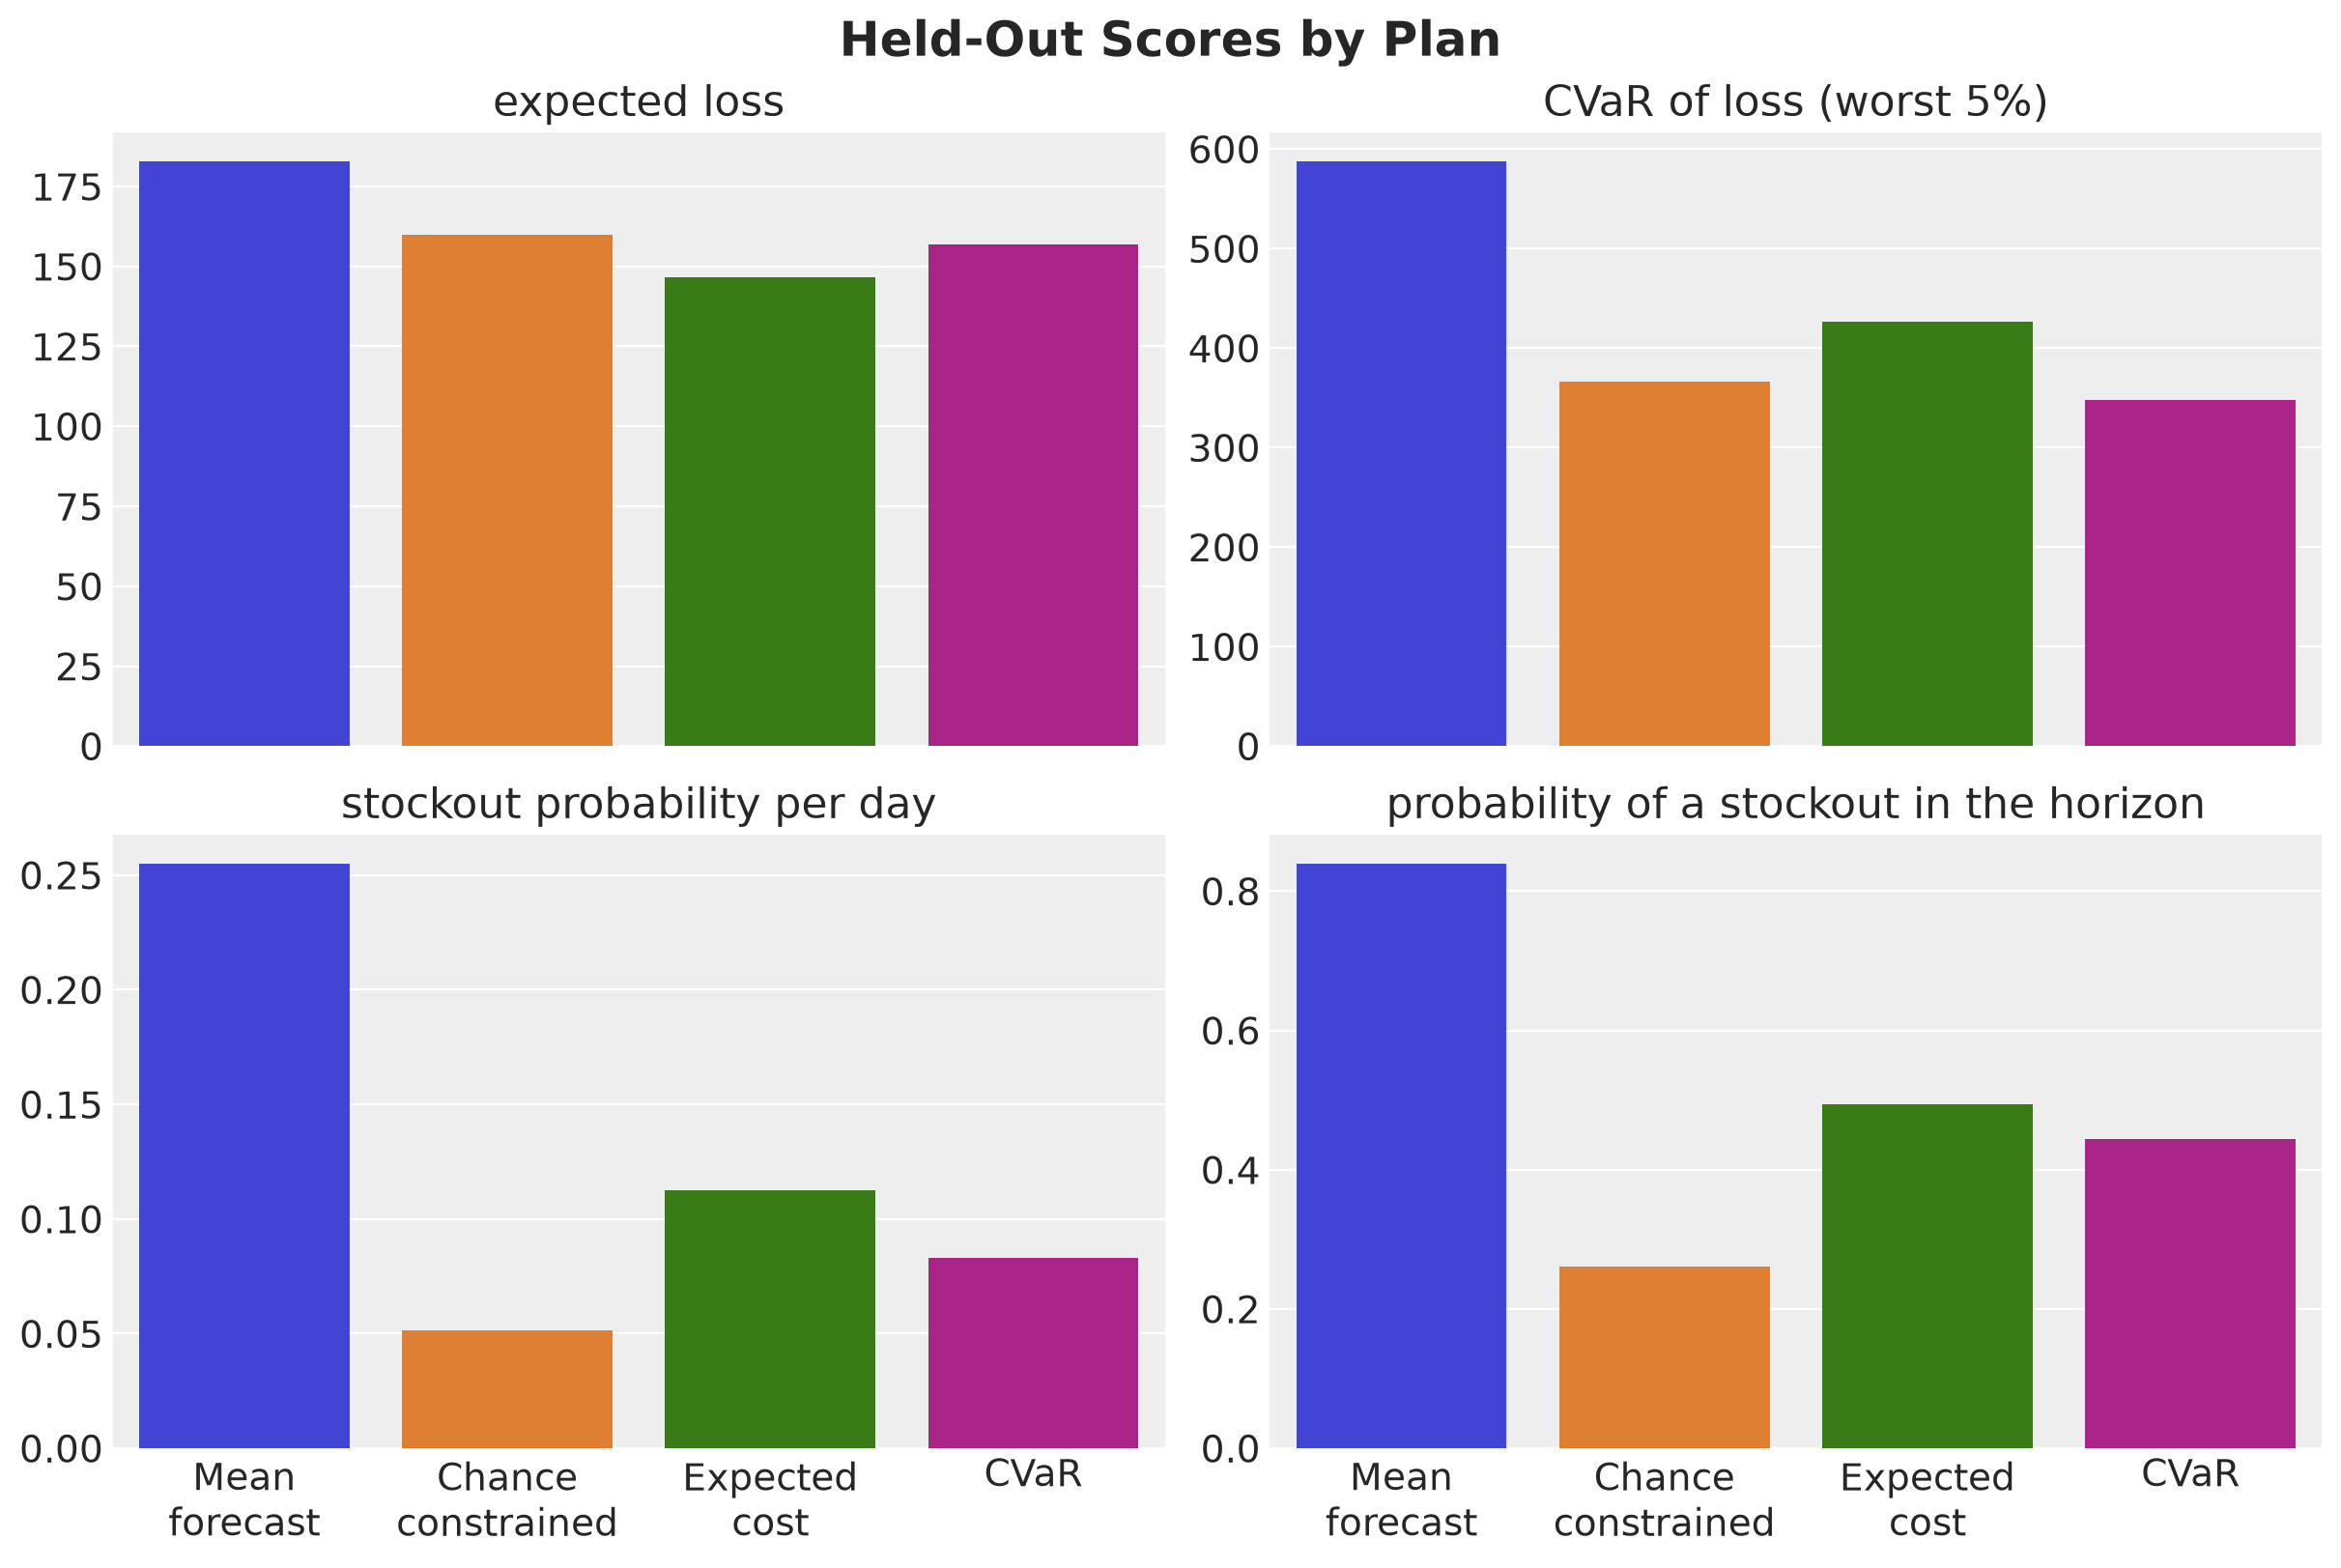

In [31]:
CVAR_METRIC = f"CVaR of loss ({TAIL_LABEL})"
STOCKOUT_METRIC = "stockout probability per day"


def summarize(
    losses: Float[Array, " scenarios"],
    lost_sales: Float[Array, "scenarios horizon"],
    alpha: float,
) -> dict[str, float]:
    """Expected loss, CVaR and stockout frequencies of one plan over the scenarios."""
    stockout = lost_sales > 0  # a day with at least one unit of lost sales
    return {
        "expected loss": float(losses.mean()),
        CVAR_METRIC: float(cvar(losses, alpha)),
        STOCKOUT_METRIC: float(stockout.mean()),
        "probability of a stockout in the horizon": float(stockout.any(axis=1).mean()),
    }


scores = {
    plan.name: simulate_scenarios(plan.orders, demand_eval, problem) for plan in plans
}
results = pl.DataFrame(
    [
        {"plan": name, **summarize(losses, lost_sales, problem.alpha)}
        for name, (losses, _, lost_sales) in scores.items()
    ]
)
metrics = [column for column in results.columns if column != "plan"]
plan_labels = [name.replace(" ", "\n") for name in plan_names]

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(12, 8), sharex=True, layout="constrained"
)

for ax, metric in zip(axes.flat, metrics, strict=True):
    sns.barplot(
        data=results,
        x="plan",
        y=metric,
        hue="plan",
        hue_order=plan_names,
        palette=PLAN_COLORS,
        legend=False,
        ax=ax,
    )
    ax.set(title=metric, xlabel="", ylabel="")

for ax in axes[-1]:
    ax.set_xticks(range(len(plans)), plan_labels)

fig.suptitle("Held-Out Scores by Plan", fontsize=18, fontweight="bold");

Here are three important remarks.

- **The point forecast is expensive.** The mean forecast plan has the worst expected loss ($183$) and the worst tail ($588$), and it loses sales on a quarter of the days. Its zero cost on the mean path told us nothing about its cost on the distribution.
- **The expected cost plan accepts more stockouts than the single-period fractile suggests.** Its stockout probability per day is $11.2\%$, while $1 - p / (p + h) = 4.8\%$. The multi-period optimum holds less stock than the newsvendor rule, for the reason we gave in the Decision Problem section. The chance-constrained plan, which is almost the myopic newsvendor plan, pays $160$ against $147$ for the extra stock, $9\%$ more.
- **The chance constraint and CVaR buy reliability differently.** The chance-constrained plan lands at $5.2\%$ per day on the held-out scenarios, slightly above its $5\%$ target, as expected from a constraint fitted on $1{,}000$ scenarios. The CVaR plan with $\lambda = 1$ pushes the tail loss down to $348$, the lowest of the four, at an expected loss of $157$, and its stockout probability per day is $8.3\%$. Each rule is best at the metric it targets: expected loss, stockout frequency or tail average.

The chance constraint holds day by day, so let's look at the stockout probability on each day of the horizon. The dashed line is the target $\alpha = 0.05$.

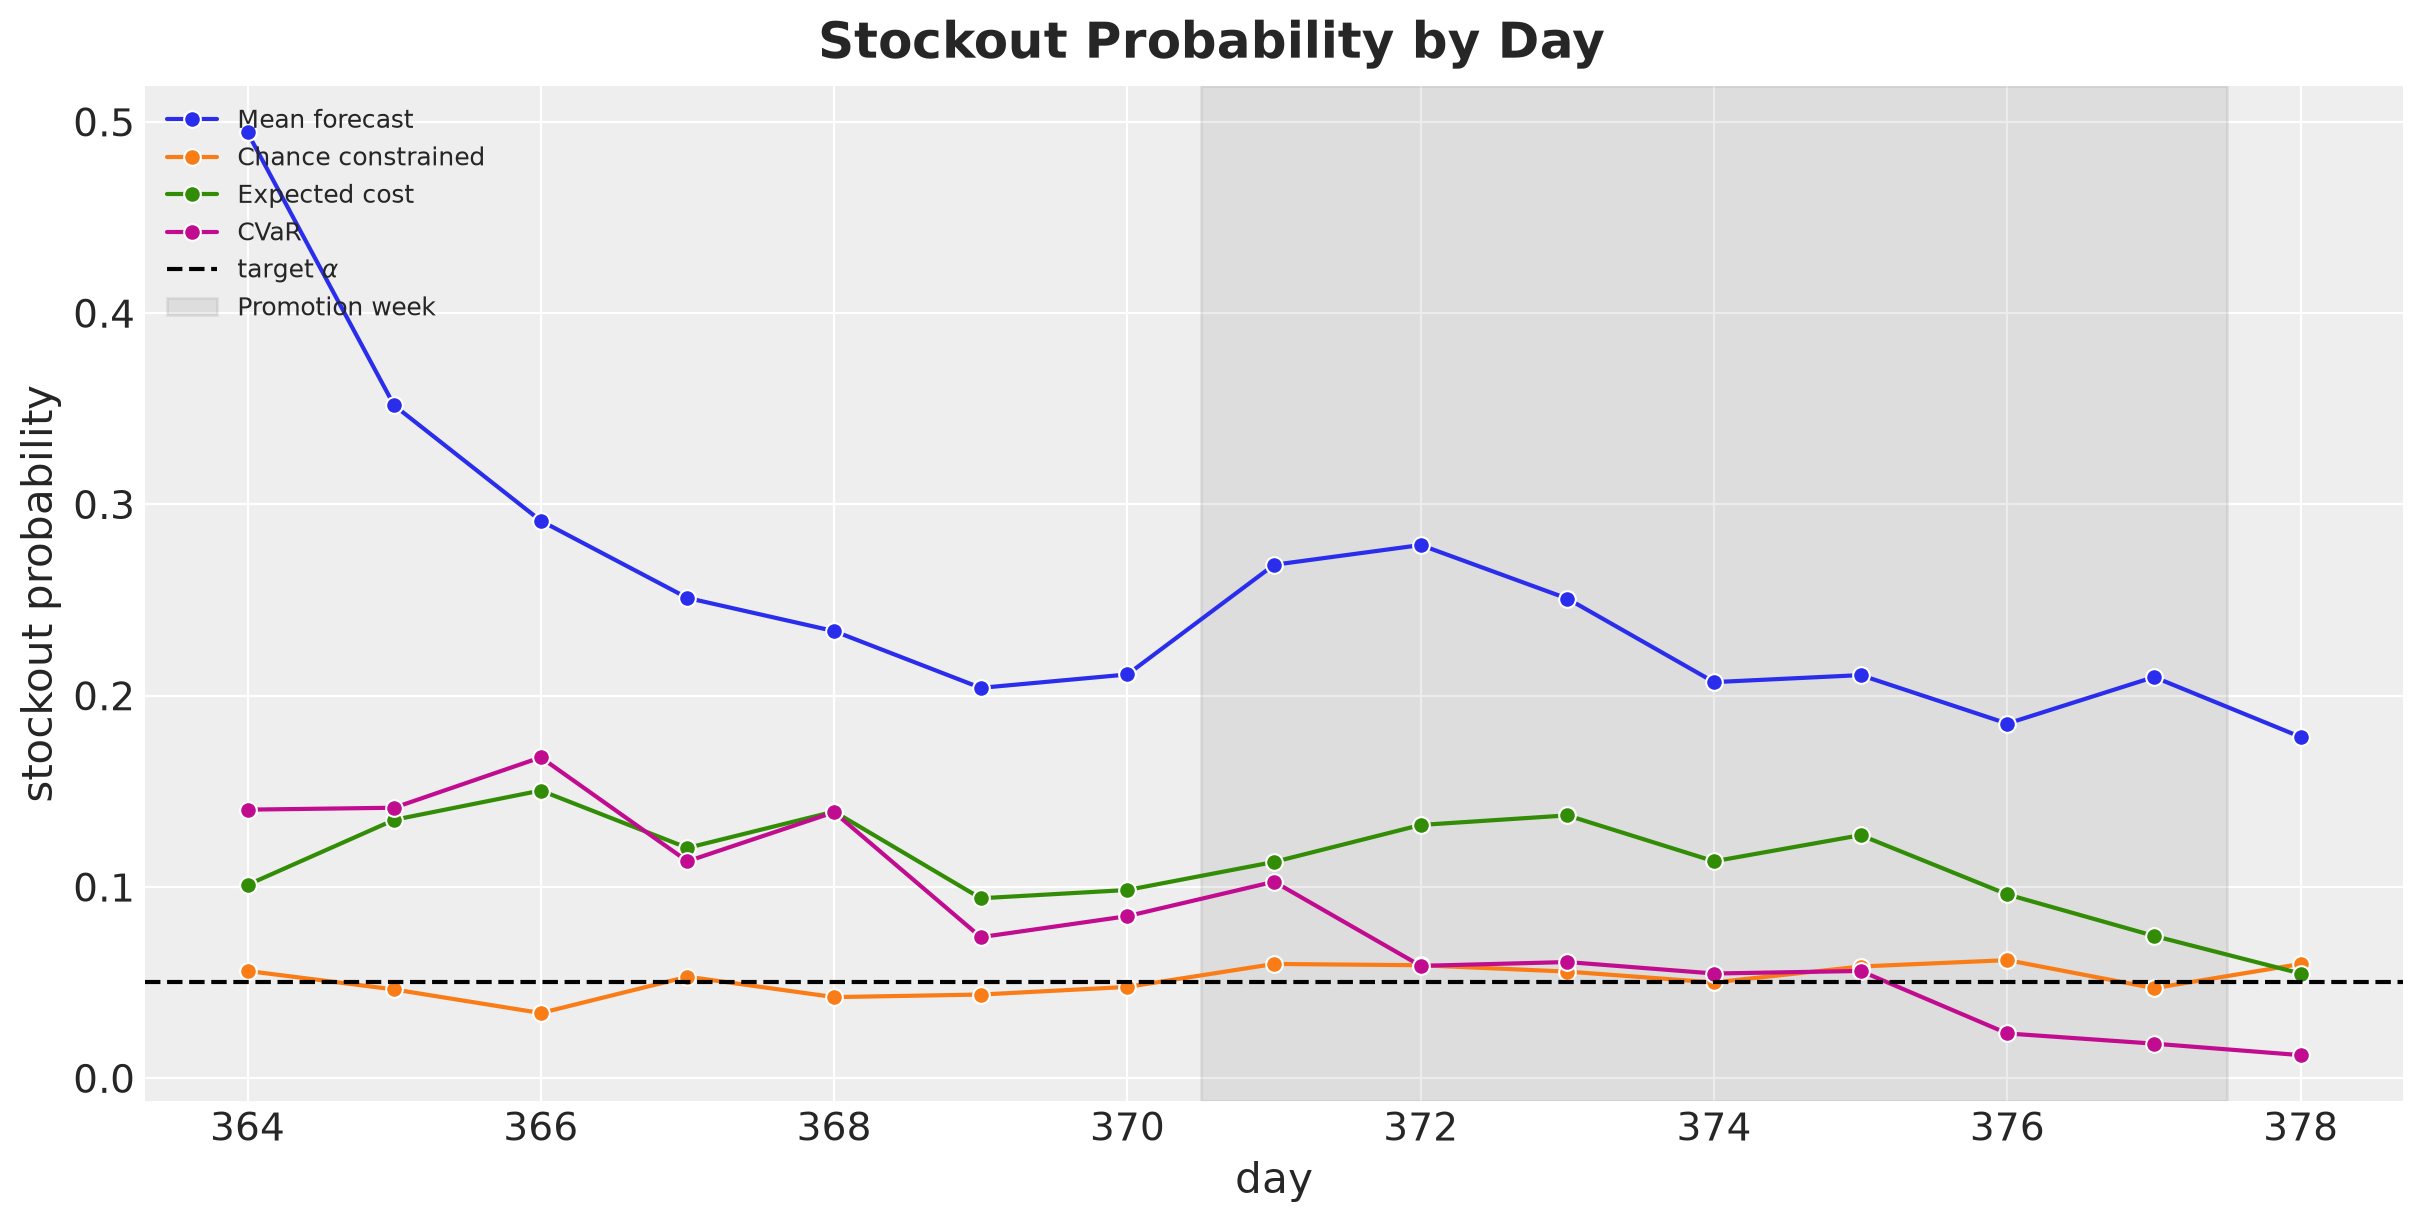

In [32]:
stockout_long = pl.DataFrame(
    {
        "plan": np.repeat(plan_names, setup.horizon),
        "day": np.tile(days_future, len(plans)),
        "stockout probability": np.concatenate(
            [
                np.asarray((lost_sales > 0).mean(axis=0))
                for _, _, lost_sales in scores.values()
            ]
        ),
    }
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=stockout_long,
    x="day",
    y="stockout probability",
    hue="plan",
    hue_order=plan_names,
    palette=PLAN_COLORS,
    marker="o",
    ax=ax,
)
ax.axhline(problem.alpha, color="black", linestyle="--", label=r"target $\alpha$")
shade_promotion(ax)
ax.legend(loc="upper left", fontsize=9)
ax.set(xlabel="day", ylabel="stockout probability")
fig.suptitle("Stockout Probability by Day", fontsize=18, fontweight="bold");

The chance-constrained plan stays between $3\%$ and $6.2\%$ on every day. The expected cost plan sits between $9\%$ and $15\%$ until the last days, where it drops to the single-period level of $5\%$, because a leftover on the last day is charged holding only once. The mean forecast plan loses sales in half of the scenarios on day one and in a fifth to a third of them afterwards, falling as the leftovers of the days with low demand build up a small buffer.

The CVaR plan is different: it runs out in $14\%$ to $17\%$ of the scenarios on the first three days and in $1\%$ to $2.5\%$ on the last three. The tail objective cares about the high-demand horizons, and those separate from the rest only after several days, so it adds stock late and not early. The early stockouts are also cheap in the tail, since stock added early would be held for days in every scenario.

This is the place to check why the scenarios have to be joint draws. Let's shuffle each day of the optimization matrix independently, which keeps every marginal distribution and destroys the correlation across days, build the chance-constrained plan on the shuffled scenarios, and score it on the held-out scenarios next to the plan built on the joint ones.

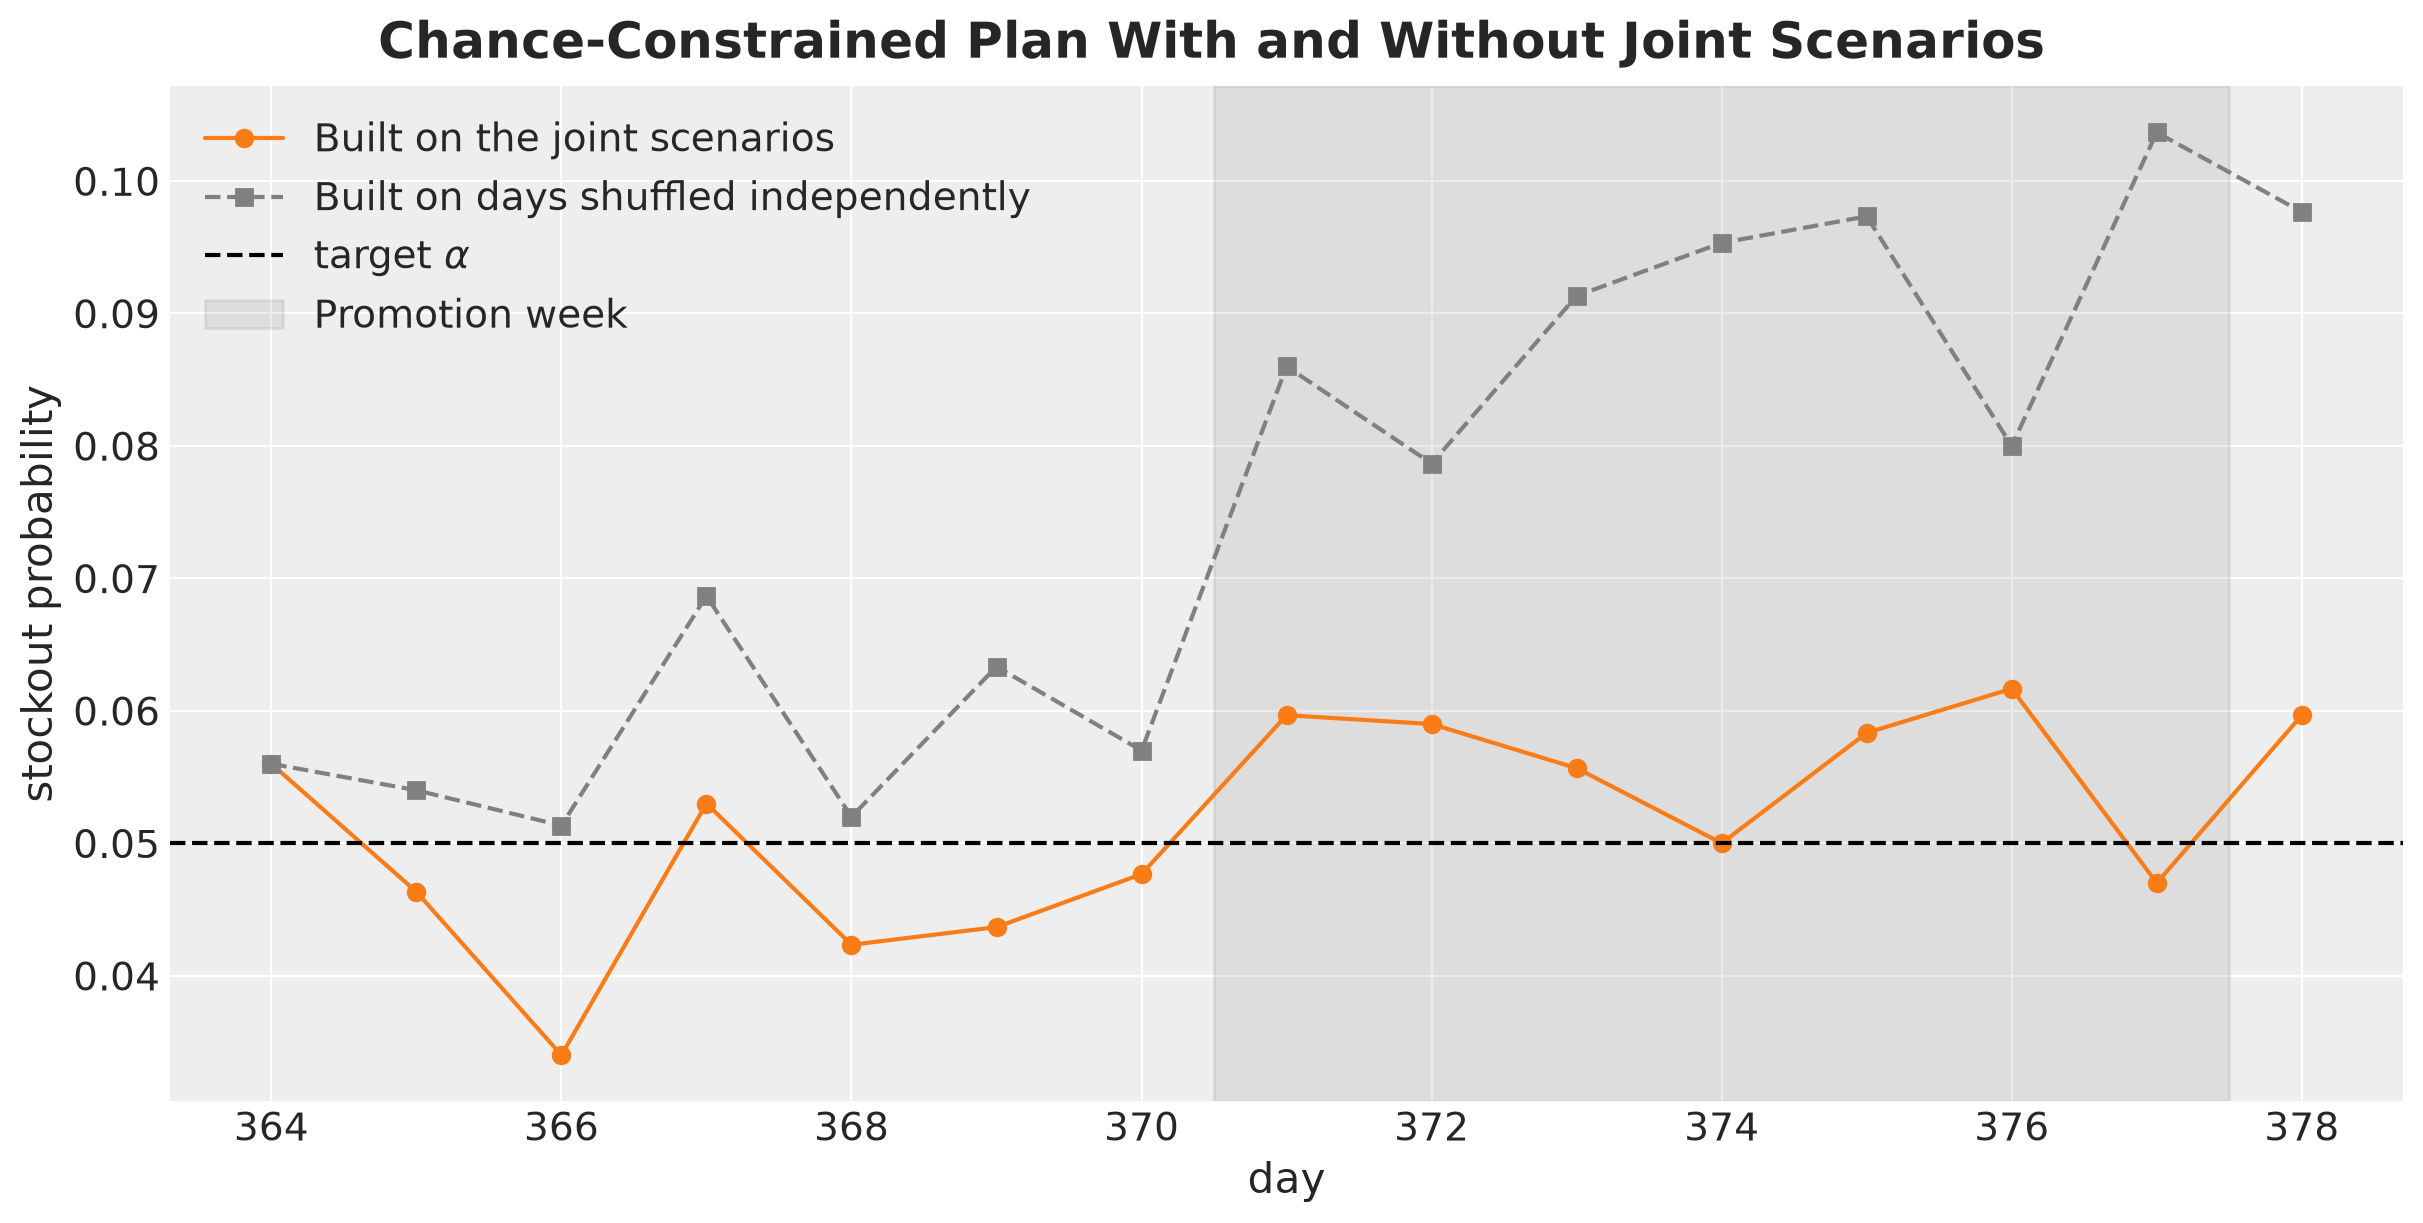

In [33]:
rng_key, key_shuffle = random.split(rng_key)
shuffle_each_day = jax.vmap(random.permutation, in_axes=(0, 1), out_axes=1)
demand_independent = shuffle_each_day(
    random.split(key_shuffle, setup.horizon), demand_opt
)
orders_cc_independent = plan_order_up_to(demand_independent, 1 - problem.alpha, problem)
_, _, lost_cc_independent = simulate_scenarios(
    orders_cc_independent, demand_eval, problem
)
_, _, lost_cc_joint = scores["Chance constrained"]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    days_future,
    np.asarray((lost_cc_joint > 0).mean(axis=0)),
    "o-",
    color="C1",
    label="Built on the joint scenarios",
)
ax.plot(
    days_future,
    np.asarray((lost_cc_independent > 0).mean(axis=0)),
    "s--",
    color="gray",
    label="Built on days shuffled independently",
)
ax.axhline(problem.alpha, color="black", linestyle="--", label=r"target $\alpha$")
shade_promotion(ax)
ax.legend(loc="upper left")
ax.set(xlabel="day", ylabel="stockout probability")
fig.suptitle(
    "Chance-Constrained Plan With and Without Joint Scenarios",
    fontsize=18,
    fontweight="bold",
);

The plan built on the shuffled scenarios stays close to the target in the first week, between $5\%$ and $7\%$, and then drifts well above it, up to $10\%$ in the promotion week, for an average of $7.5\%$ against $5.2\%$. It orders $42$ units less over the horizon, because the scenarios it was built on rarely put a high-demand day after another high-demand day, so the stock it carries is too small for the horizons where the level sits high. Only joint draws carry that correlation, and this is why we keep the scenario matrix as it comes out of the posterior.

Let's look at the loss distributions behind these numbers. We leave out the mean forecast plan, whose losses run far to the right of the other three, and we clip the horizontal axis at the $99$th percentile of the pooled losses to see the bulk of the distributions.

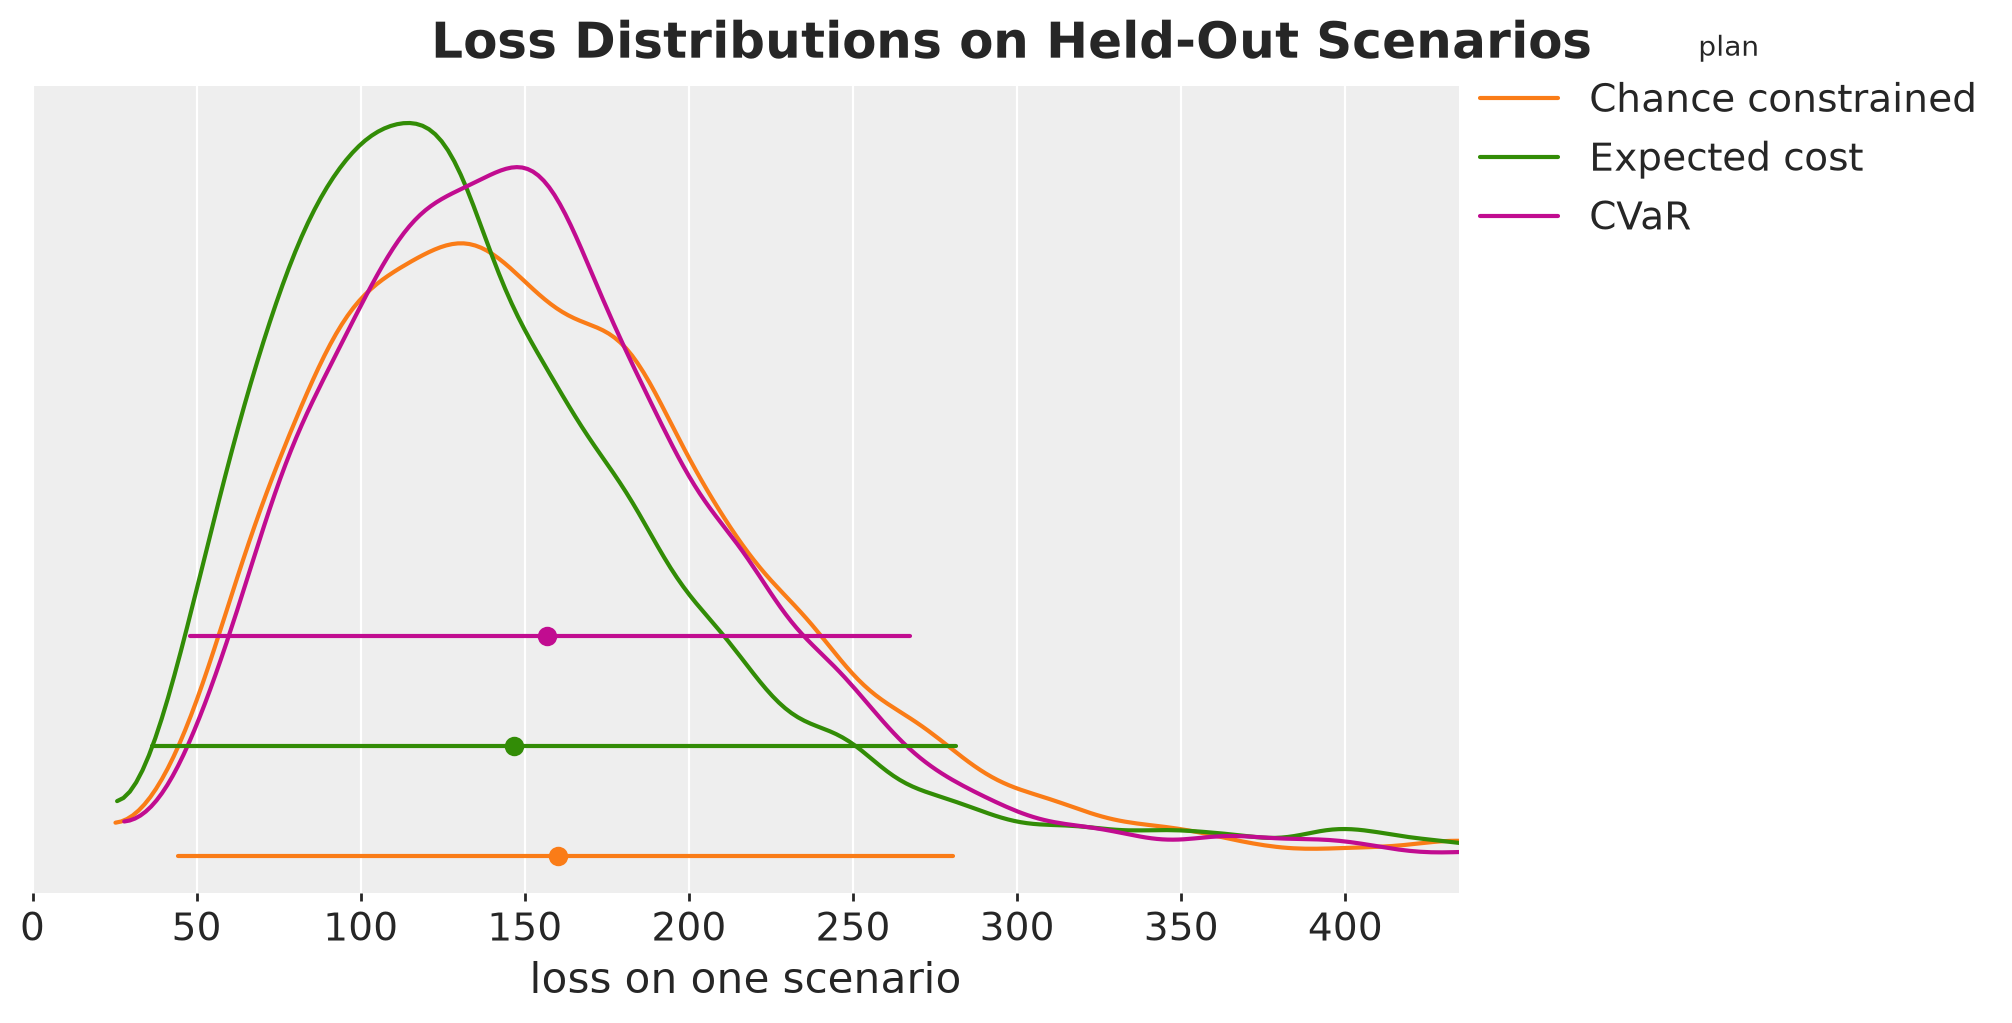

In [34]:
losses_by_plan = {
    name: xr.Dataset({"loss": (("sample",), np.asarray(losses))})
    for name, (losses, _, _) in scores.items()
    if name != "Mean forecast"
}
loss_clip = float(
    np.quantile(
        np.concatenate([ds["loss"].values for ds in losses_by_plan.values()]), 0.99
    )
)

pc = az.plot_dist(
    losses_by_plan,
    sample_dims=["sample"],
    kind="kde",
    color=[PLAN_COLORS[name] for name in losses_by_plan],
    visuals={"point_estimate_text": False},
    figure_kwargs={"figsize": (10, 5)},
)
pc.add_legend("model", title="plan")
pc.viz["plot"]["loss"].item().set(
    xlim=(0, loss_clip), xlabel="loss on one scenario", title=""
)
pc.viz["figure"].item().suptitle(
    "Loss Distributions on Held-Out Scenarios", fontsize=18, fontweight="bold"
);

The expected cost plan has the most mass at low losses, and the bar chart above showed that it also has the highest tail average of the three. Its largest held-out loss is about $1{,}000$, as the scatter plot below shows. The CVaR plan trades some of that low-loss mass for a shorter tail, with a largest loss of about $870$, and the chance-constrained plan has the widest bulk, because it holds the most stock. The dots and bars at the bottom are the means and $94\%$ intervals.

Why are the right tails so much longer than the left? The loss is bounded below by zero, and the two arms of the loss have different slopes.

One unit of demand above the stock is lost once and costs $p = 2$. One unit of stock above the demand stays on the shelf until a later day sells it. In a low-demand horizon it is never sold, and it costs $h = 0.1$ on every remaining day, which is at most $1.5$ for a unit ordered on day one. So the right arm is steeper than the left arm, but by less than the ratio of the daily costs, because leftovers persist and lost sales do not.

The plans sit above the mean demand, so most scenarios land on the holding arm and a minority lands on the lost-sales arm. A second source is the right skew of the scenarios themselves, because the level enters the rate through an exponential.

Let's confirm this by plotting the loss of every held-out scenario against its total demand over the horizon.

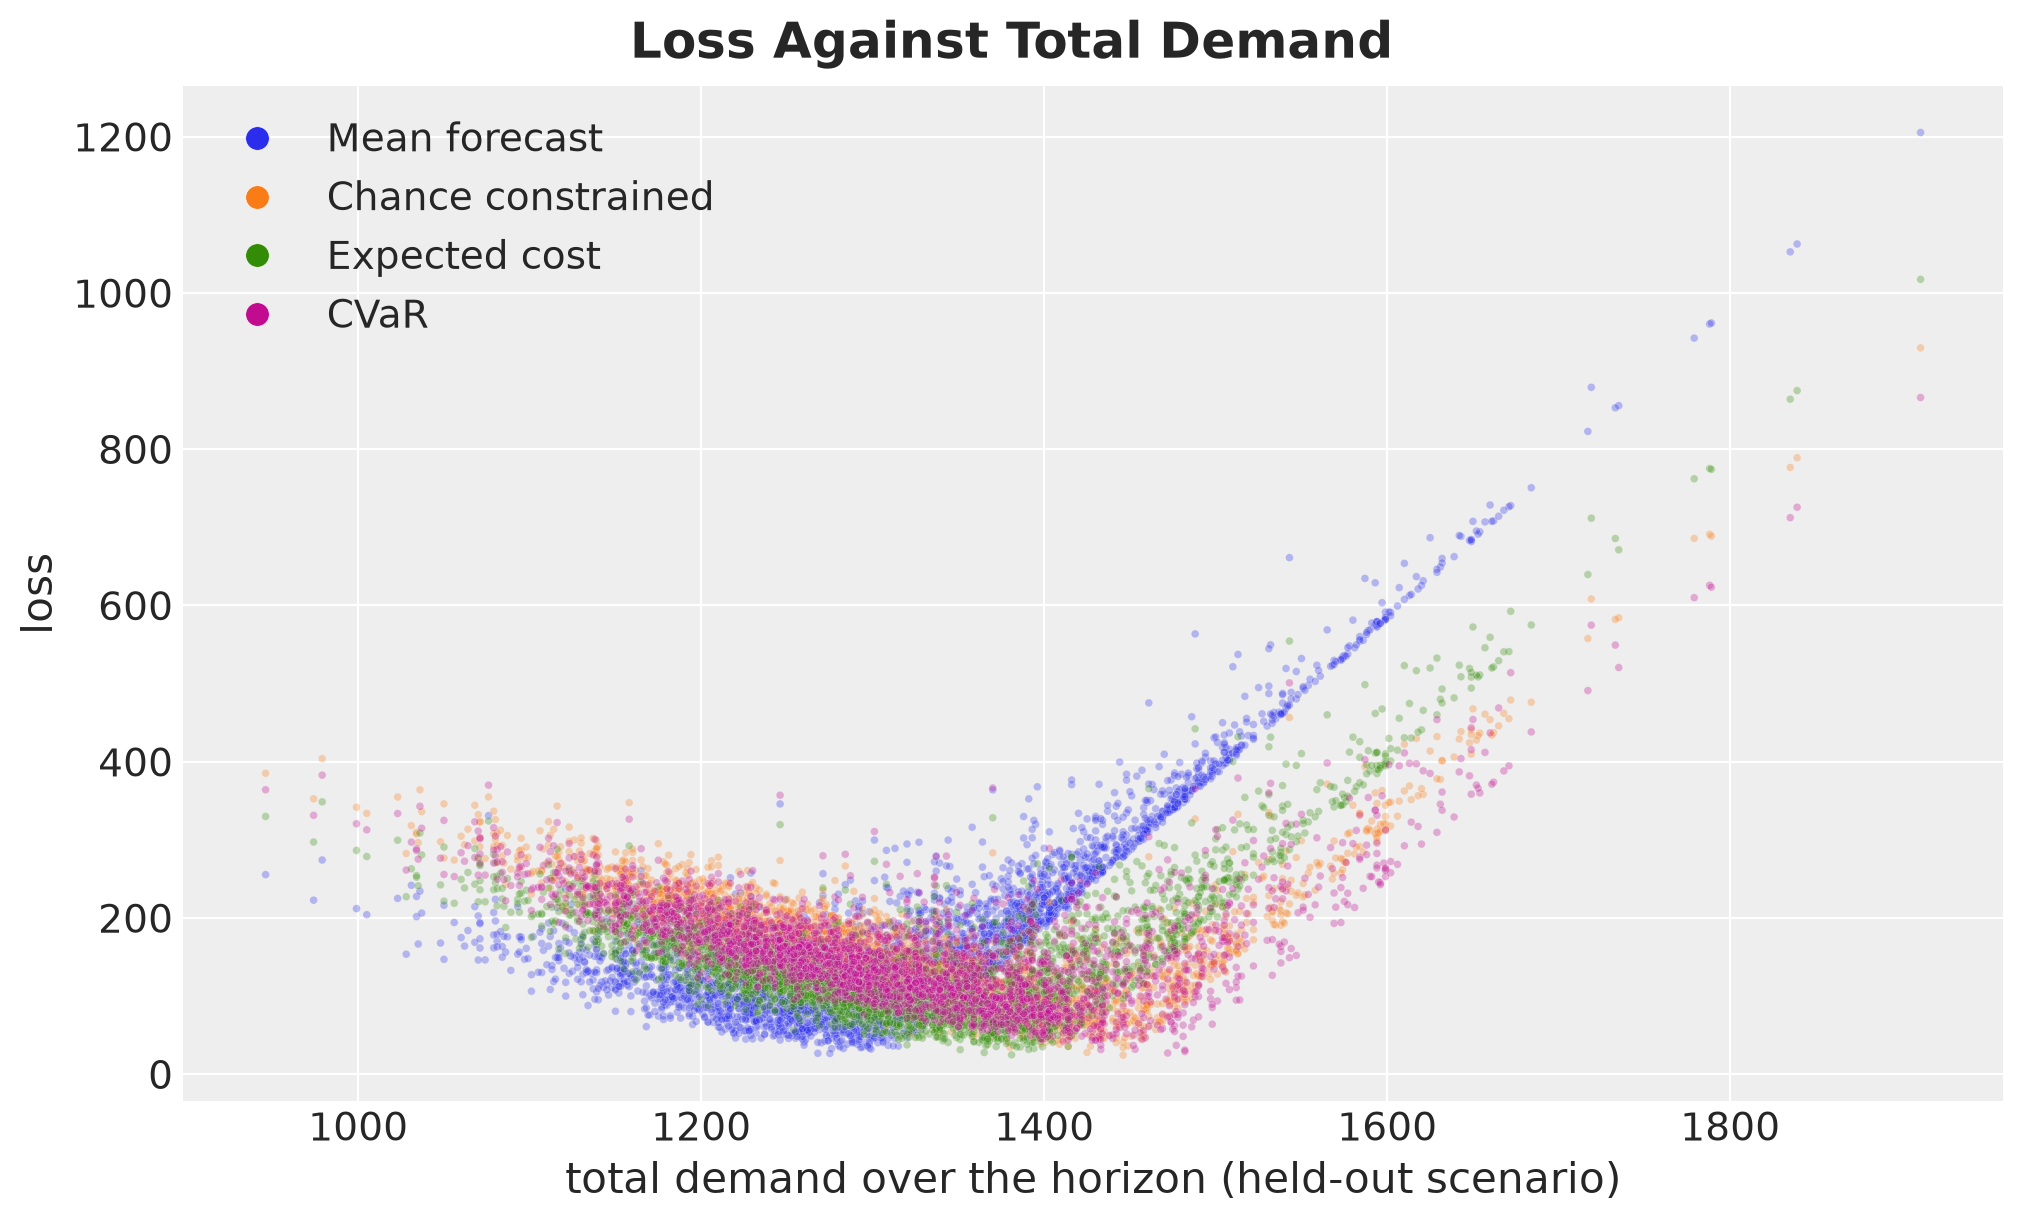

In [35]:
scatter_long = pl.DataFrame(
    {
        "plan": np.repeat(plan_names, demand_eval.shape[0]),
        "total demand": np.tile(np.asarray(demand_eval.sum(axis=1)), len(plans)),
        "loss": np.concatenate(
            [np.asarray(losses) for losses, _, _ in scores.values()]
        ),
    }
)

fig, ax = plt.subplots()
sns.scatterplot(
    data=scatter_long,
    x="total demand",
    y="loss",
    hue="plan",
    hue_order=plan_names,
    palette=PLAN_COLORS,
    s=8,
    alpha=0.3,
    ax=ax,
)
legend = ax.legend(loc="upper left", markerscale=3)
for handle in legend.legend_handles:
    handle.set_alpha(1.0)
ax.set(xlabel="total demand over the horizon (held-out scenario)", ylabel="loss")
fig.suptitle("Loss Against Total Demand", fontsize=18, fontweight="bold");

Each plan traces a check mark: a left arm where we pay holding costs on stock that is never sold, with a slope of about $0.6$ per unit of missing demand, and a right arm where we pay the margin on lost sales, with a slope of about $2$ per unit of excess demand. The buffered plans move the bottom of the check mark to the right, so fewer scenarios reach the steep arm. The mean forecast plan has its bottom at the mean demand, and half of the scenarios climb the steep arm.

Next, let's look at the stock on hand under each plan with `az.plot_lm`, one panel per plan. The black dots are the stock path under the true future demand, which we return to at the end. The held-out truth sits in the `observed_data` group only because `plot_lm` requires that group.

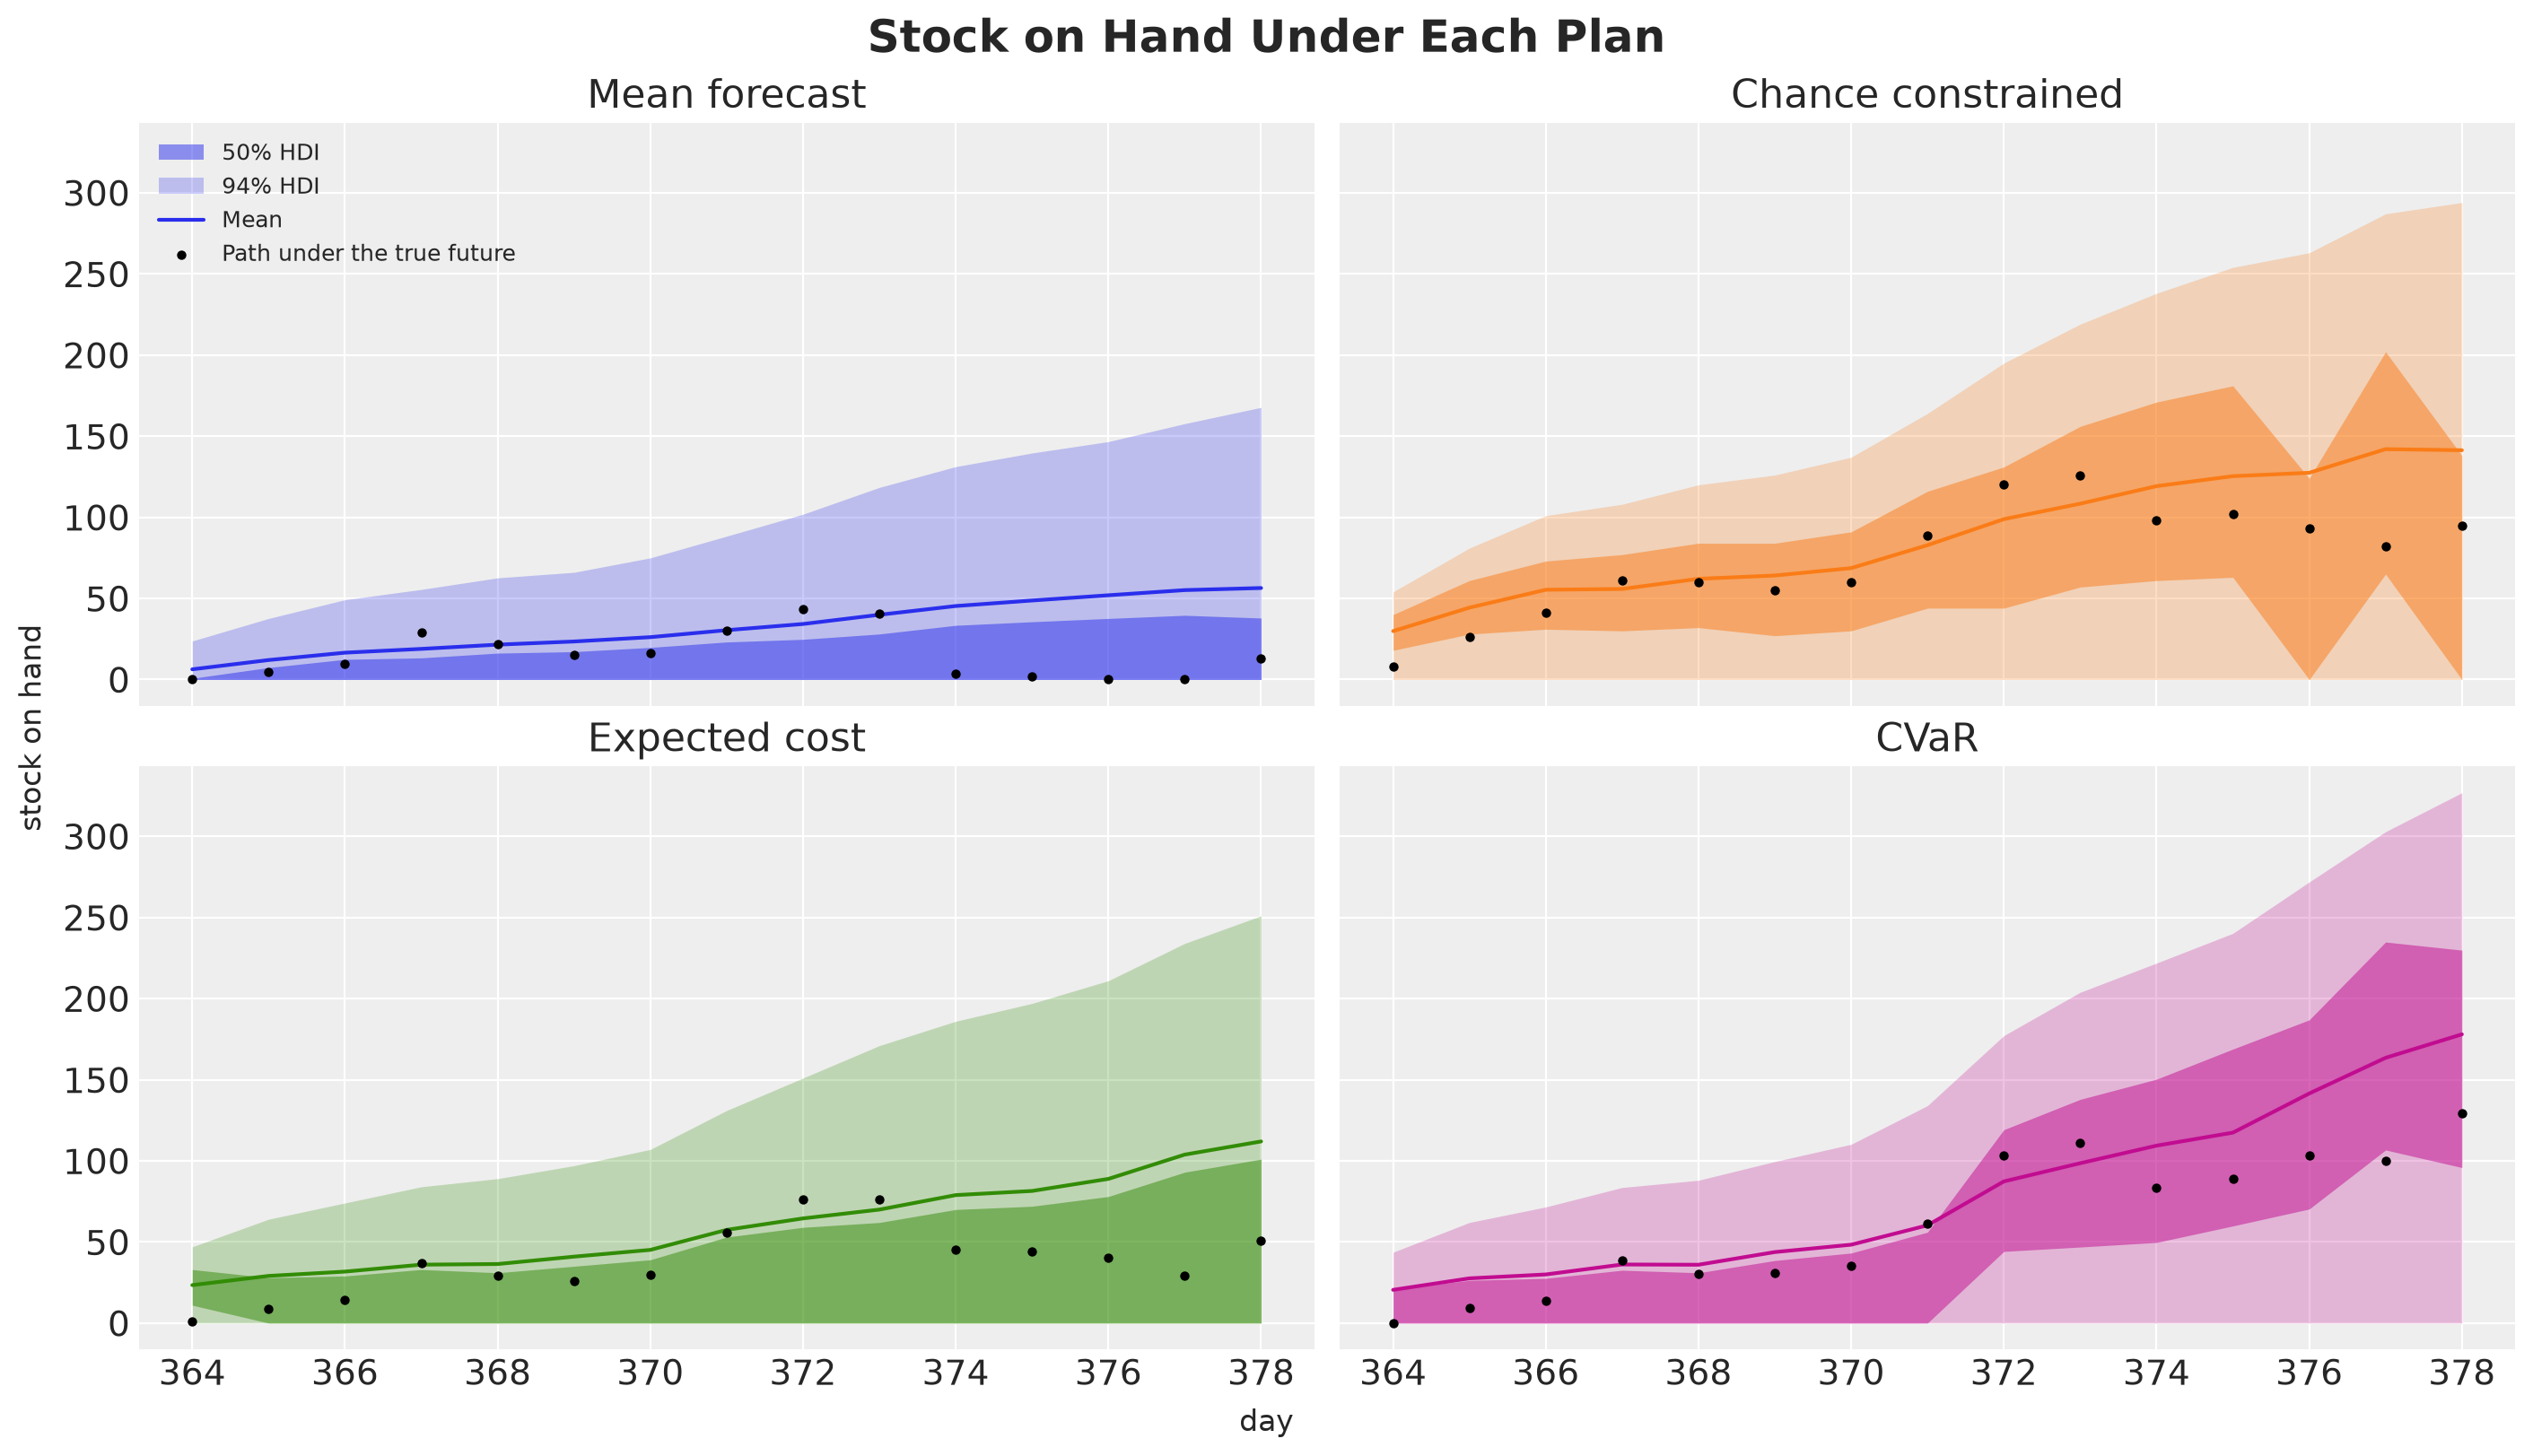

In [36]:
realized_paths = {
    plan.name: simulate(plan.orders, demand_future_true, problem) for plan in plans
}
inventory_tree = az.from_dict(
    {
        "posterior_predictive": {
            "inventory": np.stack(
                [np.asarray(inventory) for _, inventory, _ in scores.values()], axis=1
            )[None]
        },
        "observed_data": {
            "inventory": np.stack(
                [np.asarray(inventory) for _, inventory, _ in realized_paths.values()]
            )
        },
        "constant_data": {"day": np.tile(days_future.astype(float), (len(plans), 1))},
    },
    coords={"time": days_future, "plan": plan_names},
    dims={"inventory": ["plan", "time"], "day": ["plan", "time"]},
)

pc = az.plot_lm(
    inventory_tree,
    x="day",
    y="inventory",
    y_obs="inventory",
    plot_dim="time",
    smooth=False,
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    aes={"color": ["plan"]},
    aes_by_visuals={"pe_line": ["color"]},
    color=[PLAN_COLORS[name] for name in plan_names],
    visuals={
        "pe_line": {"alpha": 1.0},
        "observed_scatter": {"color": "black", "alpha": 1.0, "s": 14},
        "xlabel": False,
        "ylabel": False,
    },
    col_wrap=2,
    figure_kwargs={"figsize": (14, 8), "sharex": True, "sharey": True},
)
lighten_bands(pc, "day")

for name in plan_names:
    pc.get_target("day", {"plan": name}).set(title=name)

# one legend for all panels, read from the first one
first = {"plan": plan_names[0]}
pc.viz["ci_band"]["day"].sel(prob=HDI_PROB, **first).item().set_label(
    f"{HDI_PROB:.0%} HDI"
)
pc.viz["ci_band"]["day"].sel(prob=0.5, **first).item().set_label("50% HDI")
pc.viz["pe_line"]["day"].sel(**first).item().set_label("Mean")
pc.viz["observed_scatter"]["day"].sel(**first).item().set_label(
    "Path under the true future"
)
pc.get_target("day", first).legend(loc="upper left", fontsize=9)

fig = pc.viz["figure"].item()
fig.supxlabel("day")
fig.supylabel("stock on hand")
fig.suptitle("Stock on Hand Under Each Plan", fontsize=18, fontweight="bold");

The bands are the $50\%$ and $94\%$ HDIs of the stock on hand over the held-out scenarios, and the line is the mean. The stock never goes below zero, so a stockout shows up as a band that touches the horizontal axis. Under the mean forecast plan both bands start at zero on every day, because the shelf is empty at the end of a quarter of the scenario and day pairs.

The other plans lift the bands, and the lower edge of the wide band still reaches zero in every panel. The narrow band tells the plans apart: under the chance-constrained plan it reaches zero on day $14$ only, under the CVaR plan it sits on zero during the first week, where that plan accepts stockouts, and under the expected cost plan it sits on zero on every day, which is its $11\%$ per-day stockout rate.

Note that the mean stock grows over the horizon under every plan, even under the mean forecast plan, which carries no buffer. The growth is a property of lost sales: a surplus on one day carries over to the next, a shortfall does not, so the mean stock can only drift up over the days.

The buffered plans end the horizon with $110$ to $180$ units on the shelf on average. Only the holding charge pushes that stock down, because the loss does not mark the leftovers down at the end of the horizon, they keep their purchase value. A markdown on the last day would change the orders of the last days. The size of the buffer comes from the lack of recourse: a plan that cannot react has to hedge the demand of several days at once, while a plan that re-forecasts and re-orders every day would hedge one day at a time. We come back to this rolling horizon in the next steps.

## Pareto Frontier

The weight $\lambda$ has no natural scale. The useful object is the frontier it traces: for each $\lambda$ we solve the problem, score the plan out of sample, and plot the expected loss against the tail loss and against the stockout frequency. Because `solve` is a pure function, the whole sweep is one `jax.vmap` over the vector of weights, compiled once.

We also record which scenarios make up the worst $5\%$ under each plan. The share of them with a total demand below the median tells us whether the tail is made of high-demand or of low-demand scenarios.

In [37]:
def low_demand_tail_share(
    losses: Float[Array, " scenarios"],
    demand: Float[Array, "scenarios horizon"],
    alpha: float,
) -> float:
    """Share of the worst alpha fraction of scenarios with below-median total demand."""
    # indices of the k scenarios with the largest losses
    _, worst = jax.lax.top_k(losses, round(alpha * losses.shape[0]))
    total_demand = demand.sum(axis=1)
    return float((total_demand[worst] < jnp.median(total_demand)).mean())

Let's run the sweep and score every plan on the held-out scenarios, including the tail composition.

In [38]:
lambdas = jnp.array([0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 8.0])
solve_frontier = jax.jit(
    jax.vmap(solve, in_axes=(None, 0, None, None)),
    static_argnames=("problem", "n_steps"),
)
orders_frontier, _, _ = solve_frontier(demand_opt, lambdas, orders_mean, problem)

frontier_rows = []

for lam, orders in zip(lambdas, orders_frontier, strict=True):
    losses, _, lost_sales = simulate_scenarios(orders, demand_eval, problem)
    frontier_rows.append(
        {
            "lambda": float(lam),
            **summarize(losses, lost_sales, problem.alpha),
            "low-demand share of the tail": low_demand_tail_share(
                losses, demand_eval, problem.alpha
            ),
        }
    )

frontier = pl.DataFrame(frontier_rows)

First, let's look at the composition of the tail as a function of $\lambda$. The horizontal axis lists the solved weights at equal spacing.

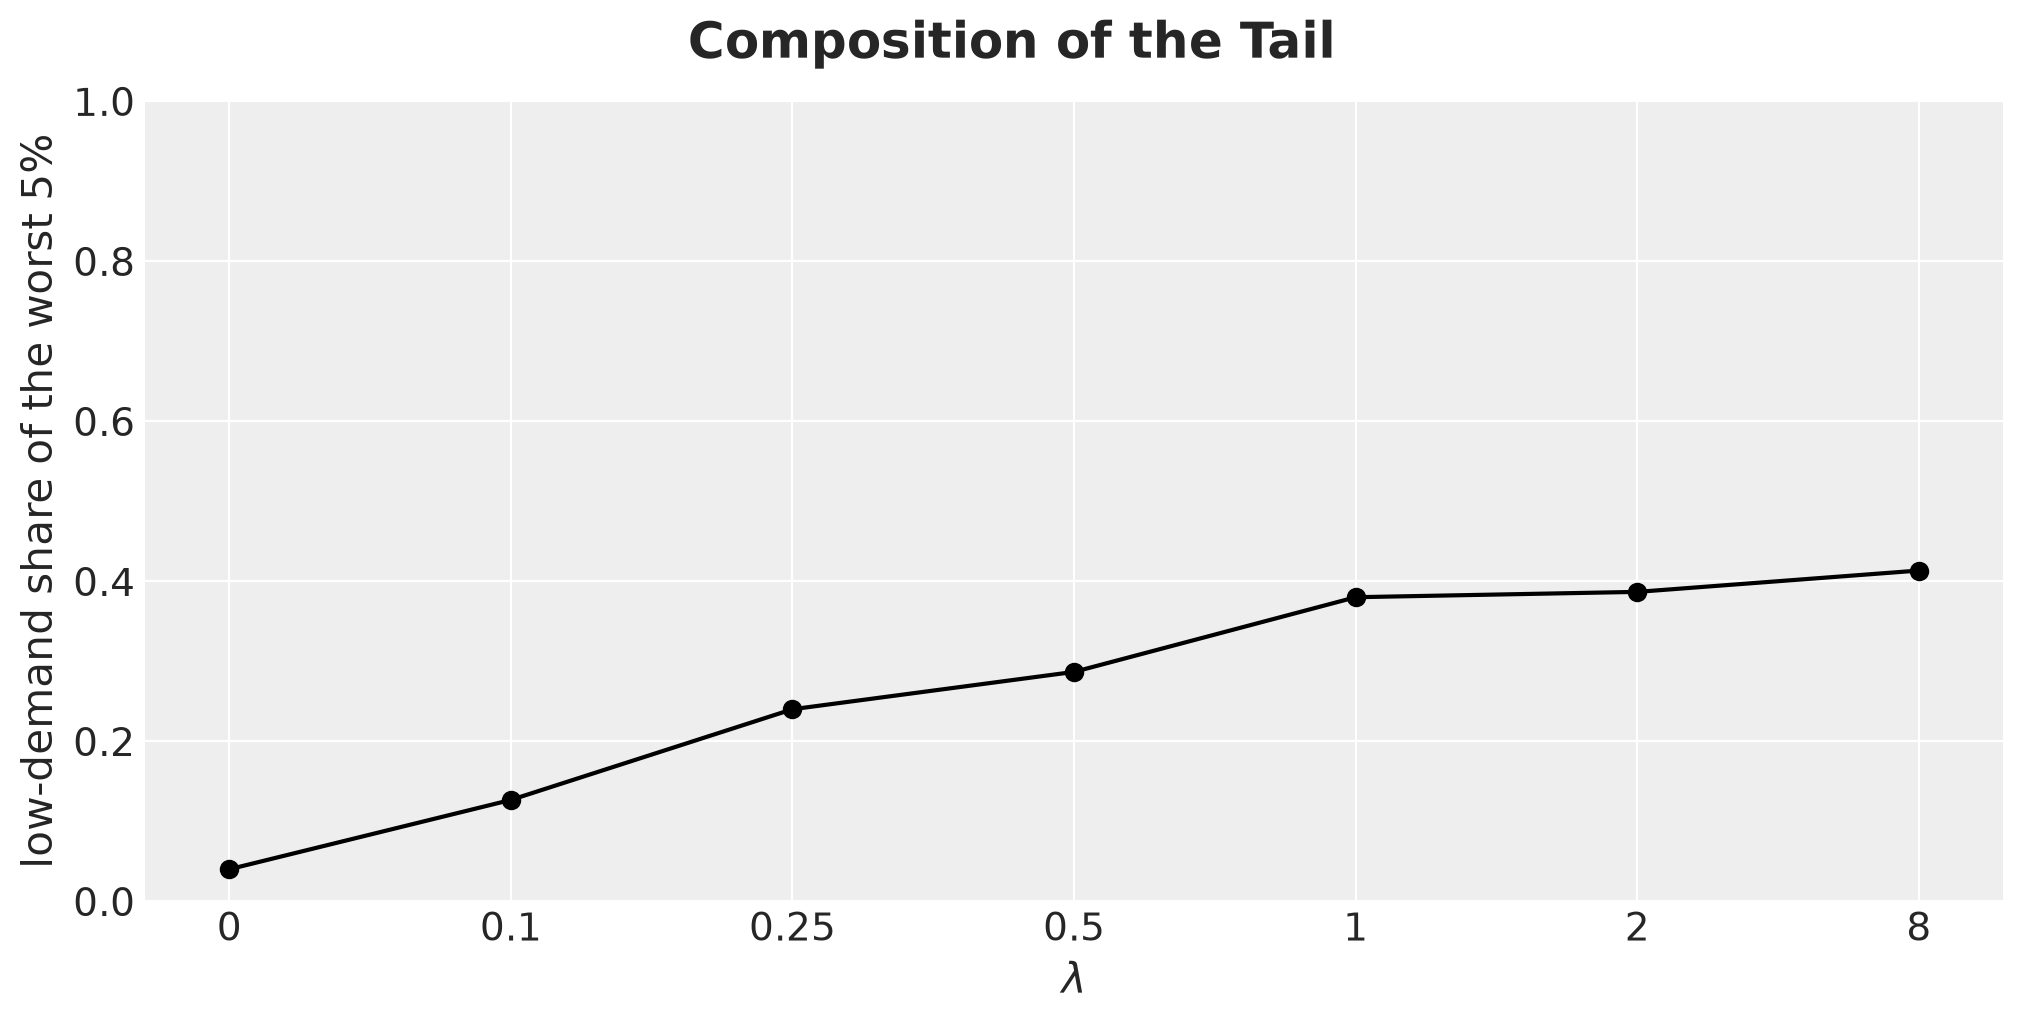

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    np.arange(len(lambdas)),
    frontier["low-demand share of the tail"].to_numpy(),
    "o-",
    color="black",
)
ax.set(
    xticks=np.arange(len(lambdas)),
    xticklabels=[f"{lam:g}" for lam in frontier["lambda"]],
    xlabel=r"$\lambda$",
    ylabel=f"low-demand share of the {TAIL_LABEL}",
    ylim=(0, 1),
)
fig.suptitle("Composition of the Tail", fontsize=18, fontweight="bold");

At $\lambda = 0$ the worst $5\%$ of the held-out scenarios are almost all high-demand horizons: $4\%$ of them have a below-median total demand. As $\lambda$ grows the plan carries more stock, and low-demand horizons that pay holding cost on the whole buffer enter the tail, up to $41\%$ of it at $\lambda = 8$. Next, let's plot the frontier and mark the three plans on it. The mean forecast plan is far outside both panels, so we leave it out.

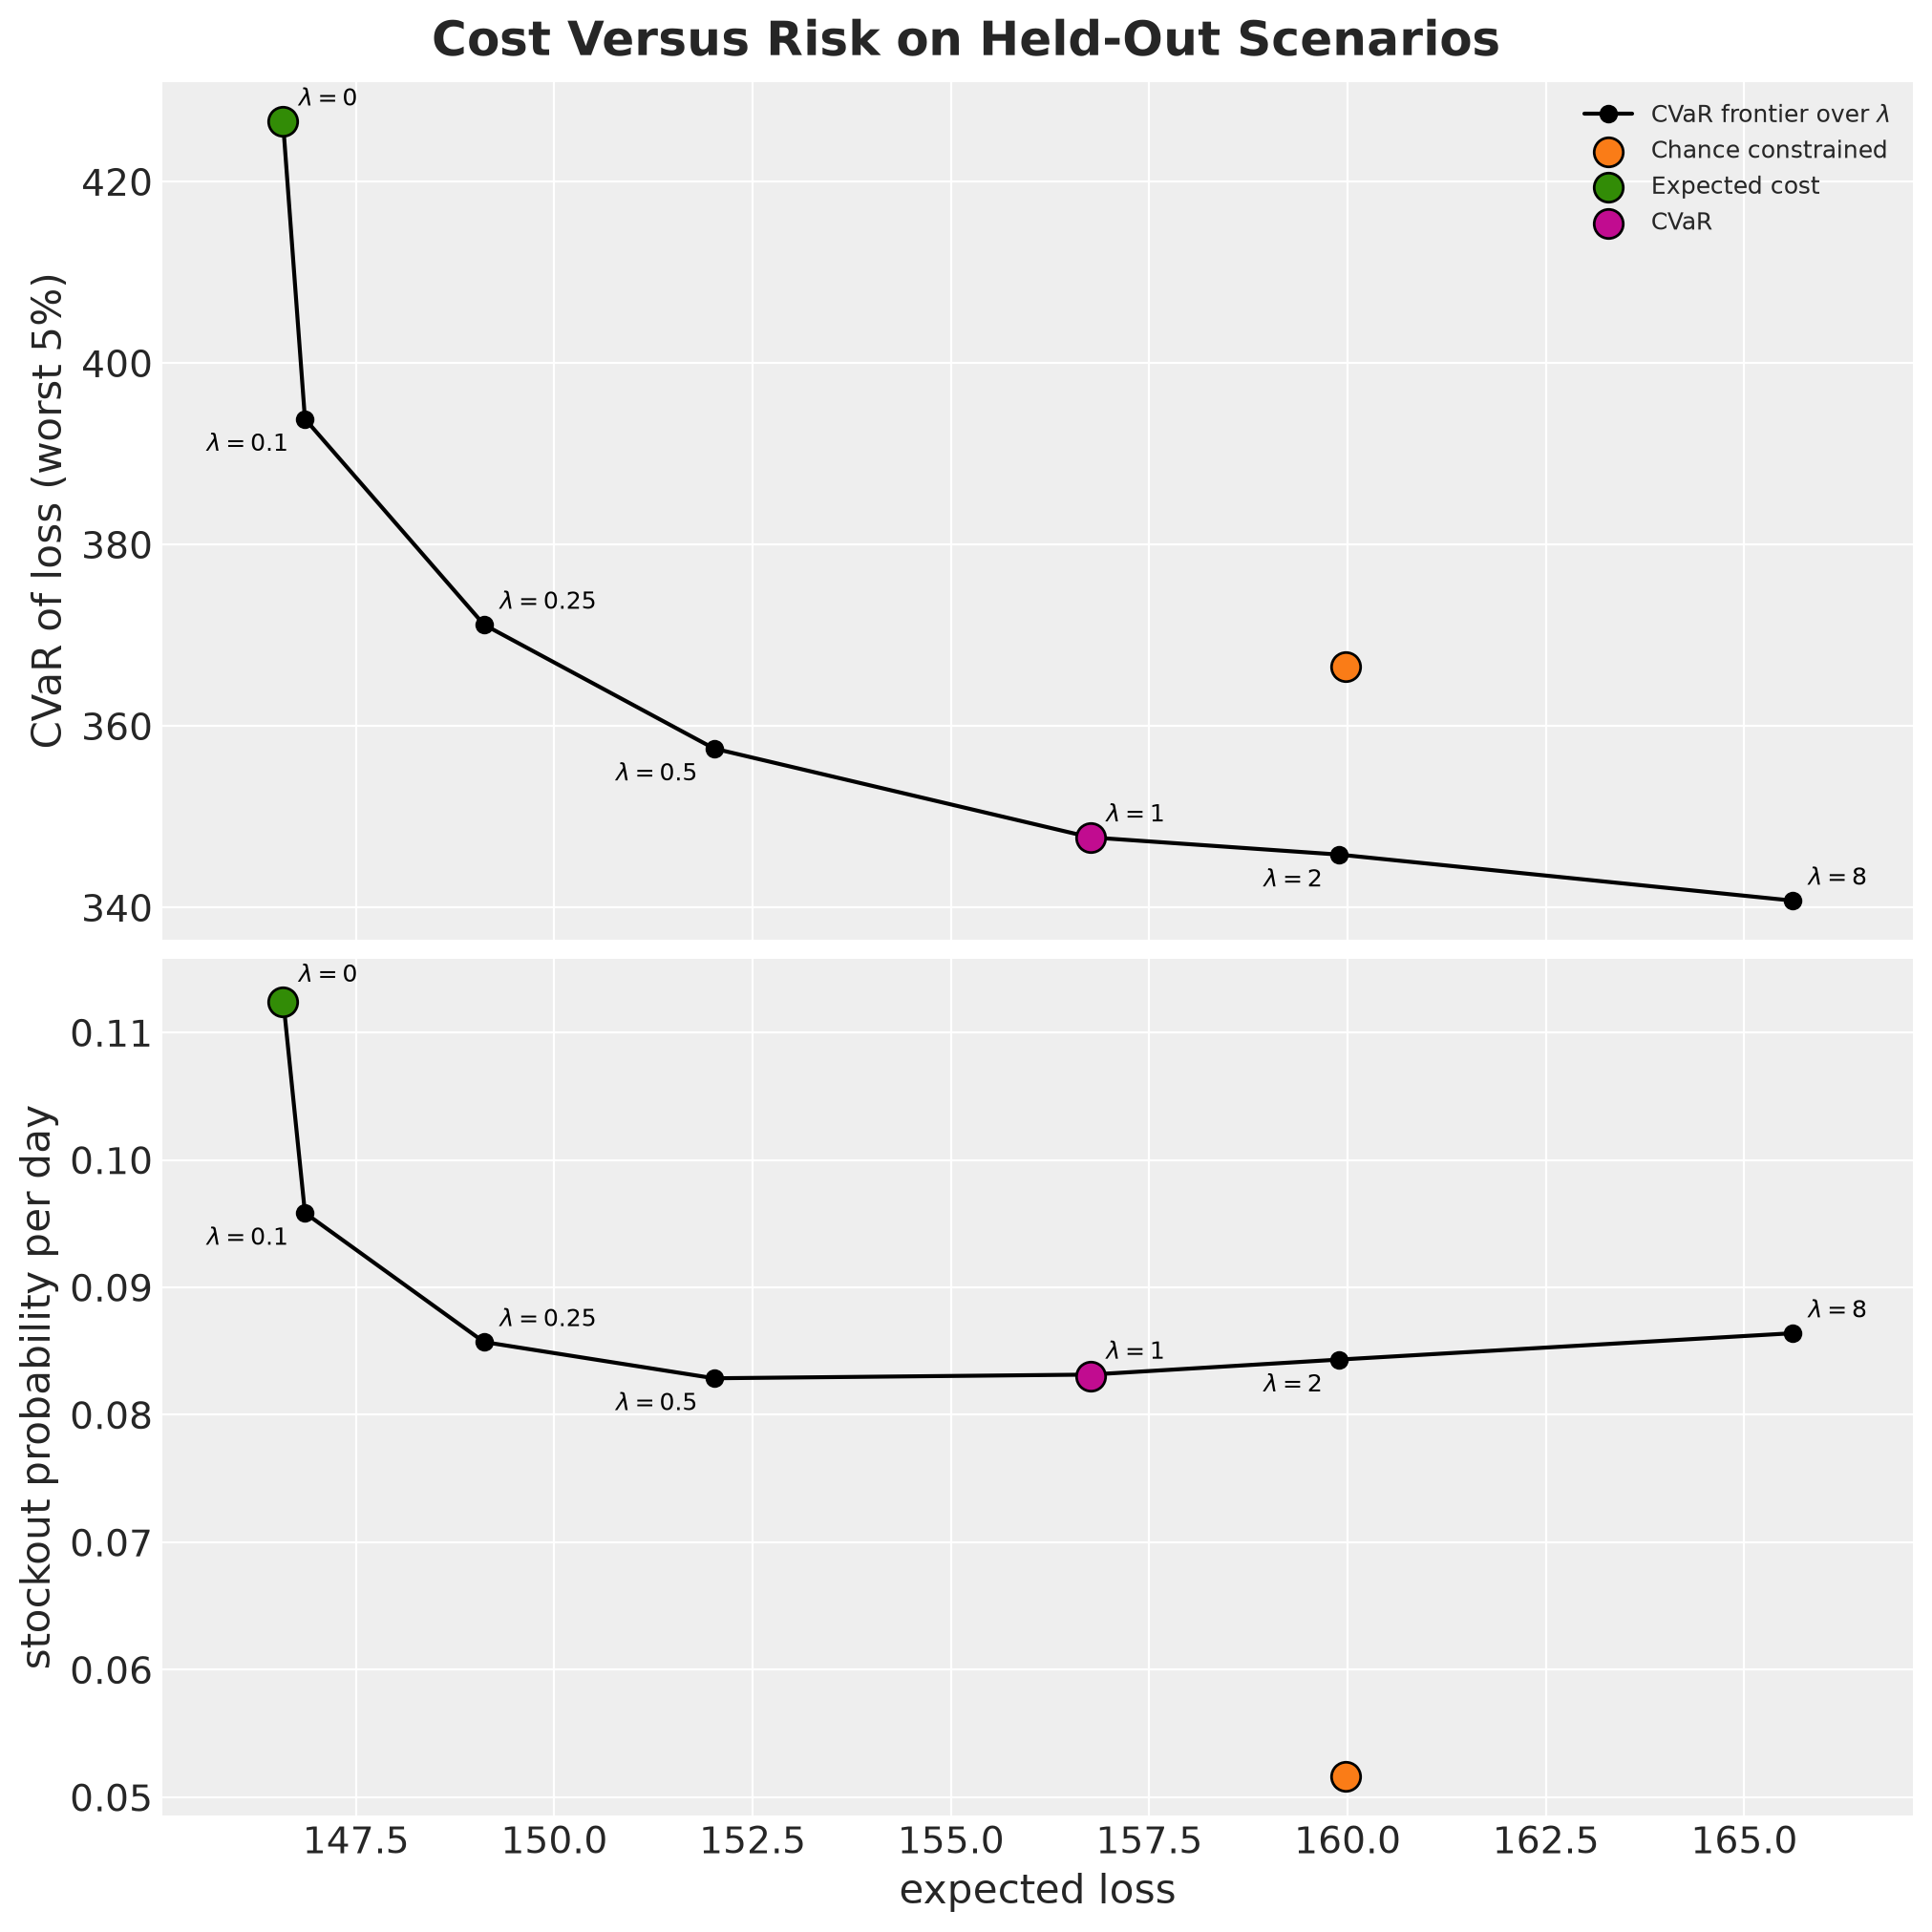

In [40]:
frontier_metrics = [CVAR_METRIC, STOCKOUT_METRIC]

fig, axes = plt.subplots(nrows=2, figsize=(10, 10), sharex=True, layout="constrained")

for ax, metric in zip(axes, frontier_metrics, strict=True):
    ax.plot(
        frontier["expected loss"],
        frontier[metric],
        "o-",
        color="black",
        label=r"CVaR frontier over $\lambda$",
    )

    for j, (lam, x_val, y_val) in enumerate(
        zip(
            frontier["lambda"], frontier["expected loss"], frontier[metric], strict=True
        )
    ):
        ax.annotate(
            rf"$\lambda={lam:g}$",
            (x_val, y_val),
            textcoords="offset points",
            xytext=(6, 6) if j % 2 == 0 else (-6, -12),
            ha="left" if j % 2 == 0 else "right",
            fontsize=9,
            color="black",
        )

    for row in results.iter_rows(named=True):
        if row["plan"] == "Mean forecast":
            continue

        ax.scatter(
            row["expected loss"],
            row[metric],
            s=120,
            color=PLAN_COLORS[row["plan"]],
            edgecolor="black",
            zorder=5,
            label=row["plan"],
        )

    ax.set(ylabel=metric)
    ax.margins(x=0.08)

axes[0].legend(loc="upper right", fontsize=9)
axes[-1].set(xlabel="expected loss")
fig.suptitle("Cost Versus Risk on Held-Out Scenarios", fontsize=18, fontweight="bold");

The expected cost plan is the $\lambda = 0$ point of the frontier and the CVaR plan is the $\lambda = 1$ point, so only the chance-constrained plan can sit off the curve. The frontier is steep on the left and flat on the right. A small $\lambda$ removes a good part of the tail loss for almost no increase in expected loss: $\lambda = 0.1$ cuts the tail loss by $8\%$ for a $0.2\%$ increase in expected loss, and $\lambda = 1$ cuts it by $18\%$ for $7\%$. Beyond $\lambda = 1$ the tail loss gains $2\%$ while the expected loss rises by another $6\%$.

In the lower panel the stockout frequency bottoms out near $8.3\%$ between $\lambda = 0.5$ and $\lambda = 1$ and rises slightly after that. The tail composition explains why: at large $\lambda$ the CVaR term shapes the plan around the low-demand horizons as well, and the scenarios in the middle run out as often as before.

This curve prices one unit of tail loss, or one percentage point of stockout probability, in units of expected loss, which is the number a planner needs.

Here is an important observation. The chance-constrained plan sits above the frontier in the upper panel and far below it in the lower panel. Both statements are consistent. CVaR trades expected loss against the tail average and does not control the frequency, while the chance constraint targets the frequency and pays for it with a worse tail at the same expected loss. The requirement decides which one to use: a service level calls for the chance constraint, a bound on bad outcomes calls for the CVaR weight.

## Convex Solver Cross Check

The projected gradient solver is convenient because it stays in JAX, but it is a first-order method on a non-smooth objective, so let's confirm that it reaches the optimum with a linear program. Two things make the objective a linear program: the loss is convex in the plan, and the CVaR has a representation with a threshold variable. Let's start with the second one. Let $z$ be a loss threshold. The Rockafellar and Uryasev representation of the conditional value at risk is

$$
\text{CVaR}_\alpha(L) = \min_{z} \left\{ z + \frac{1}{\alpha} \, \text{E}\left[(L - z)^{+}\right] \right\},
$$

where a minimizing $z$ is the value at risk. The function inside the braces is easy to picture. Let's evaluate it on the losses of the expected cost plan over the optimization scenarios, for a grid of thresholds, and compare its minimum with `cvar`.

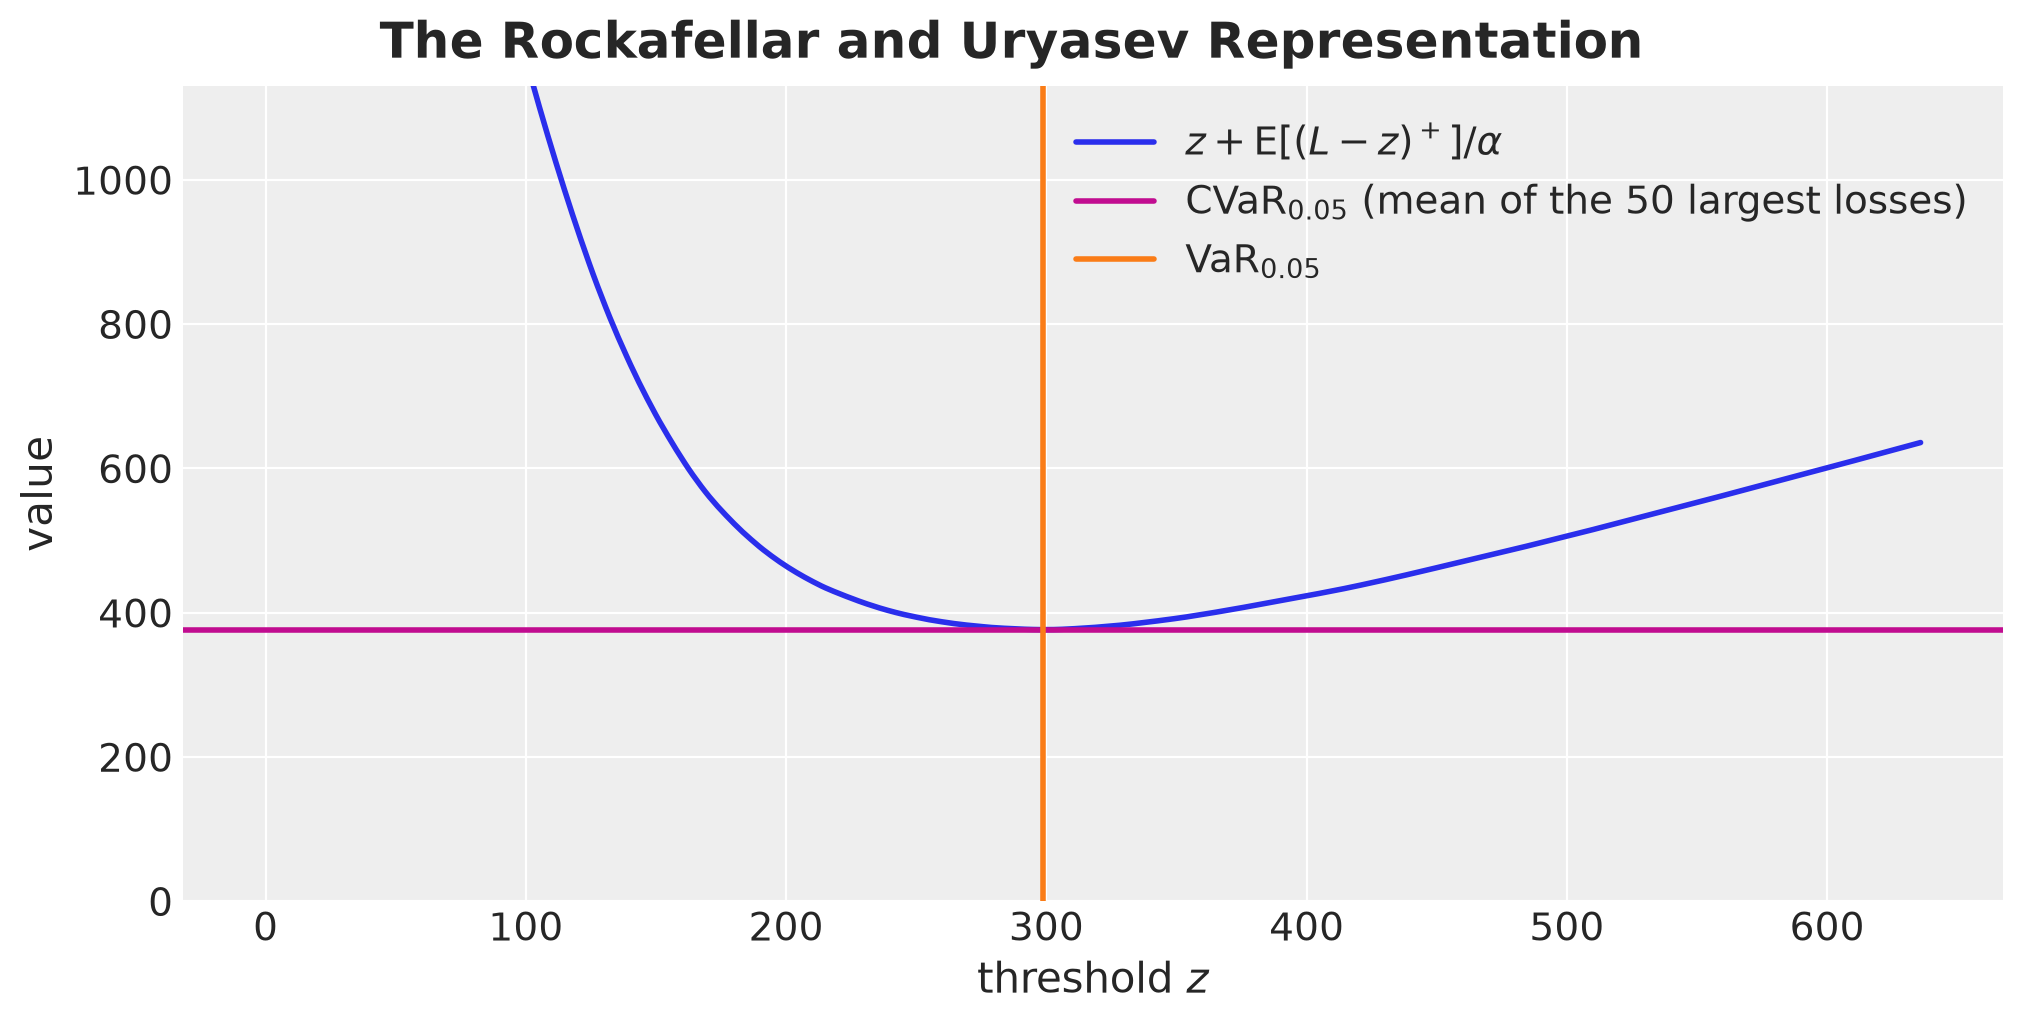

In [41]:
losses_saa_opt, _, _ = simulate_scenarios(orders_saa, demand_opt, problem)
threshold_grid = np.linspace(0, float(losses_saa_opt.max()), 400)
# z + E[(L - z)^+] / alpha on the grid, with the expectation as a scenario average
ru_objective = (
    threshold_grid
    + np.mean(
        np.maximum(np.asarray(losses_saa_opt)[None, :] - threshold_grid[:, None], 0.0),
        axis=1,
    )
    / problem.alpha
)
tail_size = round(problem.alpha * N_SCENARIOS_OPT)  # k = alpha * S

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    threshold_grid,
    ru_objective,
    color="C0",
    linewidth=2,
    label=r"$z + \text{E}[(L - z)^+] / \alpha$",
)
ax.axhline(
    float(cvar(losses_saa_opt, problem.alpha)),
    color="C3",
    linewidth=2,
    label=f"{CVAR_LABEL} (mean of the {tail_size} largest losses)",
)
ax.axvline(
    float(jnp.quantile(losses_saa_opt, 1 - problem.alpha)),
    color="C1",
    linewidth=2,
    label=VAR_LABEL,
)
ax.legend(loc="upper right")
ax.set(
    xlabel="threshold $z$",
    ylabel="value",
    ylim=(0, 3 * float(cvar(losses_saa_opt, problem.alpha))),
)
fig.suptitle(
    "The Rockafellar and Uryasev Representation", fontsize=18, fontweight="bold"
);

The curve is convex in $z$, its minimum sits at the value at risk, and the minimum value is the conditional value at risk that `cvar` computes with `top_k`. For $S$ equally weighted scenarios and an integer $k = \alpha S$, any $z$ between the $k$-th and the $(k + 1)$-th largest loss minimizes the curve, and the minimum equals the mean of the $k$ largest losses, so the linear program minimizes the same objective as `solve`. The linear program minimizes over $z$ and over the plan at the same time, with one auxiliary variable $u_s \geq (L_s - z)^{+}$ per scenario.

Now the loss. The lost sales of a day are the demand minus the stock available plus the leftover, $(D_t - y_t)^{+} = D_t - y_t + (y_t - D_t)^{+} = D_t - y_t + I_t$. With $y_t = I_{t-1} + a_t$, summing $h \, I_t + p \, L_t$ over the days gives

$$
L(a, D) = h \sum_{t=1}^{H} I_t + p \, I_H + p \left( C_H - I_0 - A_H \right),
$$

where $A_H = \sum_t a_t$ is the total order and $C_H = \sum_t D_t$ the total demand. The last term is linear in the plan. Each stock $I_t = \max(I_{t-1} + a_t - D_t, 0)$ is the positive part of a function that is convex in $a$ by induction, so it is convex in $a$ too, and so is the loss.

In the linear program we replace every $I_t^{(s)}$ by a variable with the two constraints $I_t^{(s)} \geq I_{t-1}^{(s)} + a_t - D_t^{(s)}$ and $I_t^{(s)} \geq 0$. Every stock variable has a positive coefficient in the objective, so the solver pushes each one down to the larger of the two bounds, which is the positive part we want. cvxpy hands the problem, with $S \times H$ stock variables, to HiGHS.

Building and solving the problem over $1{,}000$ scenarios sometimes raises a numpy `RuntimeWarning` (`overflow` or `invalid value encountered in reduce`). It comes from a shape check inside cvxpy (`Sum.shape_from_args` sums an uninitialized array), so we silence that one message inside the function. The agreement with the JAX solver below is the check that the solution is unaffected.

In [42]:
def solve_lp(
    demand: Float[Array, "scenarios horizon"], lam: float, problem: Problem
) -> Float[Array, " horizon"]:
    """The same objective as `solve`, as a linear program."""
    demand = np.asarray(demand, dtype=np.float64)
    num_scenarios, horizon = demand.shape
    orders = cp.Variable(horizon, nonneg=True)  # the plan a
    stock = cp.Variable((num_scenarios, horizon), nonneg=True)  # I_t of every scenario
    var = cp.Variable()  # the threshold z
    excess = cp.Variable(num_scenarios, nonneg=True)  # u_s >= (L_s - z)^+

    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message=".*encountered in reduce",
            category=RuntimeWarning,
        )
        # stock as lower bounds, I_t >= I_{t-1} + a_t - D_t, tight at the optimum
        constraints = [
            stock[:, 0] >= problem.initial_inventory + orders[0] - demand[:, 0]
        ]

        for t in range(1, horizon):
            constraints.append(
                stock[:, t] >= stock[:, t - 1] + orders[t] - demand[:, t]
            )

        # loss of every scenario: h sum_t I_t + p I_H + p (C_H - I_0 - A_H)
        losses = (
            problem.holding_cost * cp.sum(stock, axis=1)
            + problem.lost_sales_cost * stock[:, -1]
            + problem.lost_sales_cost
            * (demand.sum(axis=1) - problem.initial_inventory - cp.sum(orders))
        )
        # the same integer tail size as `cvar`, so both objectives agree
        cvar_term = var + cp.sum(excess) / round(problem.alpha * num_scenarios)
        lp = cp.Problem(
            cp.Minimize(cp.sum(losses) / num_scenarios + lam * cvar_term),
            [*constraints, excess >= losses - var],
        )
        lp.solve(solver=cp.HIGHS)

    return jnp.asarray(orders.value, dtype=jnp.float32)

We solve the two problems with cvxpy and overlay the order plans of both solvers. We evaluate `objective` at both solutions, so that the two values come from the same function, and the panel titles carry the relative gap and the largest difference between the two order vectors.

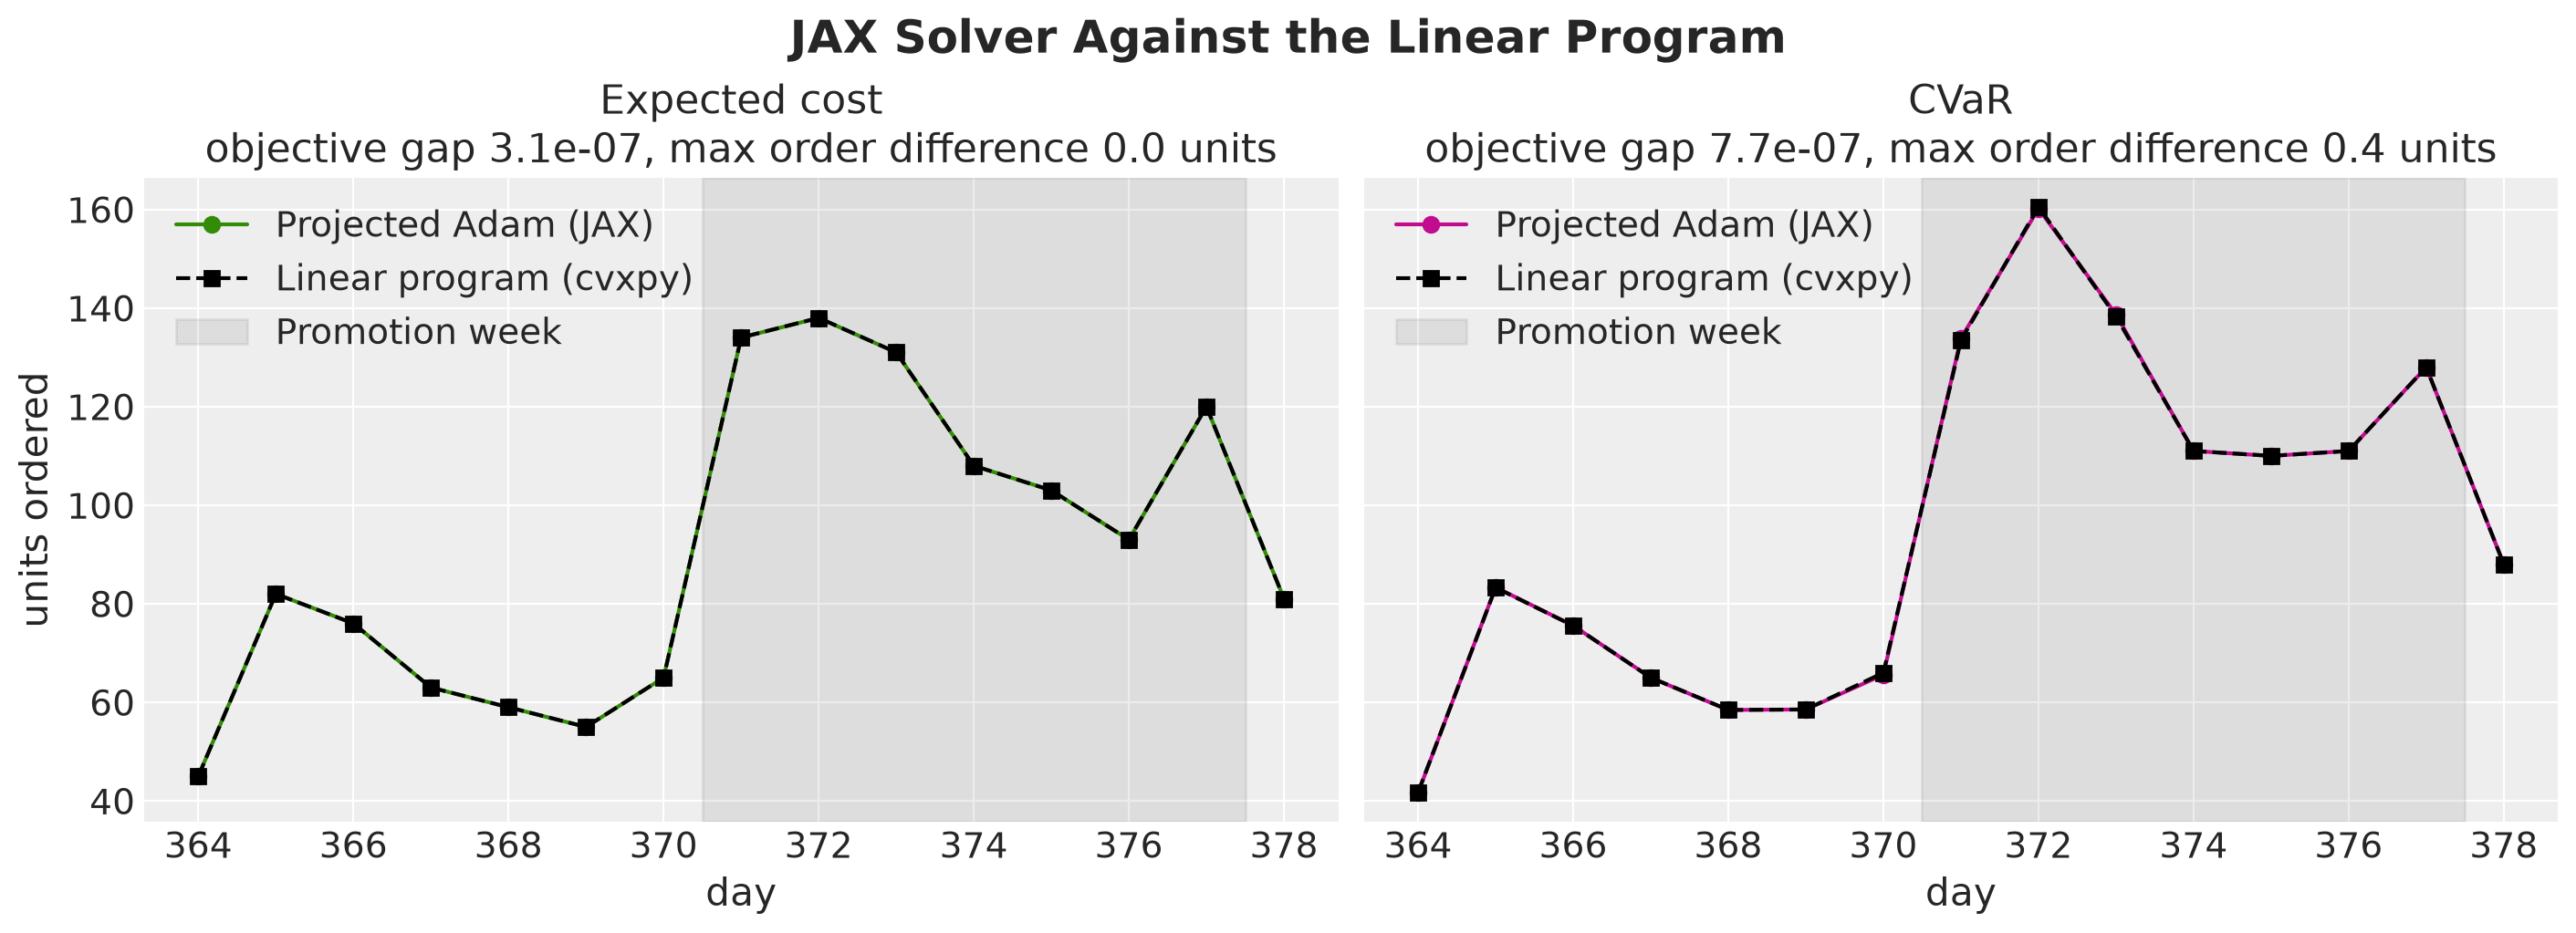

In [43]:
fig, axes = plt.subplots(ncols=2, figsize=(14, 5), sharey=True, layout="constrained")

for ax, (name, lam, orders_jax, color) in zip(
    axes,
    [("Expected cost", 0.0, orders_saa, "C2"), ("CVaR", 1.0, orders_cvar, "C3")],
    strict=True,
):
    orders_lp = solve_lp(demand_opt, lam, problem)
    value_jax = float(objective(orders_jax, demand_opt, lam, problem))
    value_lp = float(objective(orders_lp, demand_opt, lam, problem))
    relative_gap = value_jax / value_lp - 1
    max_order_diff = float(jnp.abs(orders_jax - orders_lp).max())
    ax.plot(
        days_future,
        np.asarray(orders_jax),
        "o-",
        color=color,
        label="Projected Adam (JAX)",
    )
    ax.plot(
        days_future,
        np.asarray(orders_lp),
        "s--",
        color="black",
        label="Linear program (cvxpy)",
    )
    shade_promotion(ax)
    ax.legend(loc="upper left")
    ax.set(
        xlabel="day",
        title=f"{name}\nobjective gap {relative_gap:.1e}, "
        f"max order difference {max_order_diff:.1f} units",
    )

axes[0].set(ylabel="units ordered")
fig.suptitle("JAX Solver Against the Linear Program", fontsize=18, fontweight="bold");

The two solvers agree! The relative objective gaps are $3 \times 10^{-7}$ for the expected cost plan and $8 \times 10^{-7}$ for the CVaR plan, and the order quantities differ by less than $0.5$ units on orders of about $100$ units, so the two solvers land on the same plan. We use the JAX solver to vectorize over weights or over products, and the LP when the problem gains integer decisions or coupling constraints.

Finally, as a single sanity check, we score the plans on the one true future path we held out at the start. One path is noisy, so we read this as a consistency check. We show the realized loss and the number of days with lost sales.

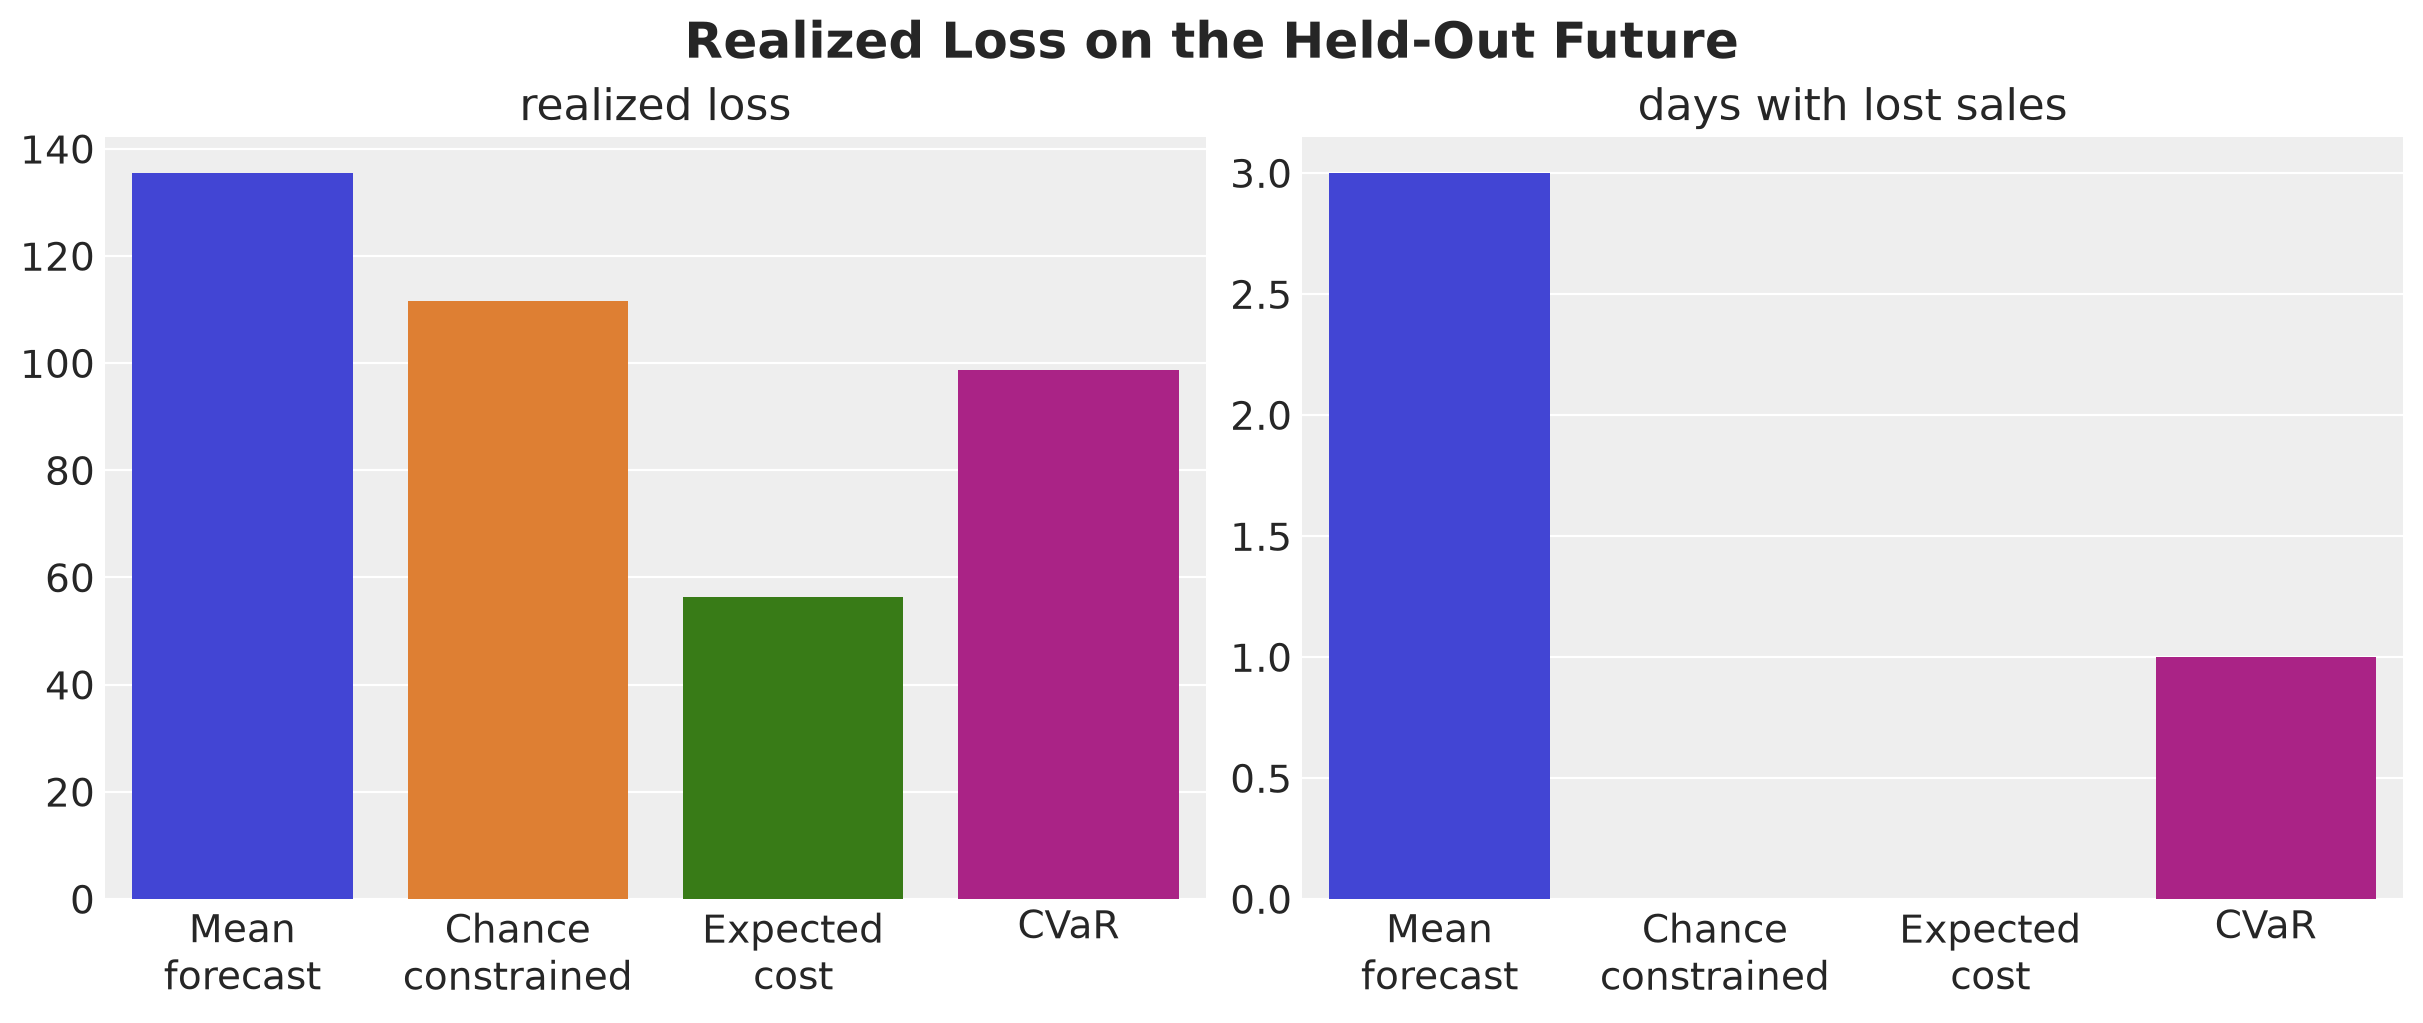

In [44]:
realized = pl.DataFrame(
    [
        {
            "plan": name,
            "realized loss": float(loss),
            "days with lost sales": int((lost_sales > 0).sum()),
        }
        for name, (loss, _, lost_sales) in realized_paths.items()
    ]
)

fig, axes = plt.subplots(ncols=2, figsize=(12, 5), layout="constrained")

for ax, metric in zip(axes, ["realized loss", "days with lost sales"], strict=True):
    sns.barplot(data=realized, x="plan", y=metric, hue="plan", legend=False, ax=ax)
    ax.set_xticks(range(len(plans)), plan_labels)
    ax.set(title=metric, xlabel="", ylabel="")

fig.suptitle("Realized Loss on the Held-Out Future", fontsize=18, fontweight="bold");

The true path ran above the forecast mean on $8$ of the $15$ days and by about $3\%$ in total. The mean forecast plan lost sales on three days: $22$ units on day one, where the true demand of $94$ units met an order of $22$ units plus the initial stock, and $34$ units across days $13$ and $14$, so it paid the most.

The CVaR plan lost $2$ units on day one and nothing afterwards, the other two plans never ran out, and the expected cost plan paid the least because it held the smallest buffer. On the $3{,}000$ held-out scenarios the CVaR plan has the best tail and the chance-constrained plan the best service level, so one path does not rank the plans.

## Conclusion

### Key Findings

- **The forecast is the scenario matrix.** All four plans are built from the same $1{,}000$ joint posterior predictive scenarios and scored on the same $3{,}000$ held-out ones. The only modeling choice at the decision step is the rule applied to the loss distribution, and that choice moved the expected loss by $25\%$ and the tail loss by $70\%$ across plans.
- **A point forecast hides the cost.** The mean forecast plan costs nothing on the mean path and the most on the distribution. The loss is non-linear in demand, so the expectation of the loss differs from the loss at the expected demand.
- **Lost sales change the risk-neutral plan.** A lost sale costs its margin once, a leftover costs holding on every day until it is sold, and the earlier leftovers cushion the later days. The plan that minimizes the expected loss accepts a stockout on $11\%$ of the days, more than twice the $4.8\%$ of the single-period fractile, and the myopic newsvendor rule overstocks, at an $11\%$ higher expected loss. A service level target needs a chance constraint. A CVaR term prices the tail loss and does not control the frequency.
- **Each rule is best at its own metric.** The expected cost plan has the lowest expected loss, the CVaR plan the lowest tail average, and the chance-constrained plan the lowest stockout frequency. A large CVaR weight stops improving the stockout frequency, because the tail fills with low-demand horizons that pay holding cost. Pick the rule that matches the requirement the business states.
- **Known covariates sharpen the scenarios.** The price path is set by the retailer, so the forecast knows the promotion week in the horizon and every plan raises its orders for that week.
- **JAX covers the whole pipeline.** The loss is a `lax.scan`, the scenarios are a `vmap`, the tail is a `lax.top_k`, the solver is a `lax.scan` under `jit`, and the frontier is a `vmap` over the weight. The projected gradient solver matched the LP optimum to $10^{-6}$.

### Model Limitations

- **No recourse.** All orders are fixed at the start of the horizon. A rolling horizon that re-forecasts and re-solves each day, and commits only the next order, is the practical version of this problem.
- **No lead time.** Orders arrive on the day we planned them for. The VN2 setting has a two-week delivery lead time, which moves the decision to the stock projected at the delivery date.
- **Unconstrained demand history.** The forecasting model sees the demand itself. In a real lost-sales setting the history is sales, which are censored on the days the shelf was empty. The VN2 report handles this with stockout-aware features, and the [censored demand example](https://juanitorduz.github.io/numpyro_forecast/docs/examples/censored_demand.html) of `numpyro_forecast` shows a likelihood for it.
- **Same model in and out of sample.** We evaluate the plans on scenarios from the same model that produced the optimization set, so model misspecification does not show up in the held-out scores. A backtest on real data would expose it.
- **Constant margin and linear holding cost.** A lost sale costs the same margin on every day, and leftovers keep their value at the end of the horizon. Perishable goods, order minimums and fixed ordering costs change the simulator, and integer order quantities change the solver.
- **In-sample optimism.** The sample average approximation with $1{,}000$ scenarios can be optimistic in sample, which is why we score out of sample. Here the two agree, because the held-out scenarios come from the same posterior.

### Recommendations

1. **Report the whole frontier.** The weight $\lambda$ is a business decision, and the frontier shows what one percentage point of reliability costs.
2. **Keep the scenarios joint.** Marginal quantiles per day break every constraint that couples days, products or hierarchy levels.
3. **Validate the first-order solver once.** Check it against a convex solver once per problem class, then use the JAX version for the sweeps.

## Next Steps

1. **Rolling horizon.** Wrap the solve in `numpyro_forecast.backtest` so that each window re-forecasts, re-solves and commits one order.
2. **Lead time.** Add a pipeline of in-transit orders to the scan carry, as in the VN2 setting, so that an order placed today arrives in two weeks. Only the simulator changes.
3. **Many products.** Fit a hierarchical forecast and `vmap` the solver over the product axis, with a shared budget constraint as a second projection step.
4. **Distributionally robust variant.** Reweight the scenarios adversarially within a divergence ball to see how much of the frontier survives when the forecast tails are not trusted.

## References

- Szabłowski, B. (2026). [One Global Model, Many Behaviors: Stockout-Aware Feature Engineering and Dynamic Scaling for Multi-Horizon Retail Demand Forecasting with a Cost-Aware Ordering Policy (VN2 Winner Report)](https://arxiv.org/abs/2601.18919). arXiv:2601.18919.
- Saunders, D., Viera, B., Laramore, J. and Wimpey, E. (2026). [Designing Optimal Energy Generation Plans with PyMC and FICO Xpress](https://www.pymc-labs.com/blog-posts/probabilistic-forecasting-optimization-under-uncertainty). PyMC Labs blog.
- Zipkin, P. (2008). [Old and New Methods for Lost-Sales Inventory Systems](https://doi.org/10.1287/opre.1070.0471). *Operations Research*, 56(5), 1256-1263.
- Bijvank, M. and Vis, I. F. A. (2011). [Lost-sales inventory theory: A review](https://doi.org/10.1016/j.ejor.2011.02.004). *European Journal of Operational Research*, 215(1), 1-13.
- Rockafellar, R. T. and Uryasev, S. (2000). [Optimization of conditional value-at-risk](https://www.risk.net/journal-risk/2161159/optimization-conditional-value-risk). *Journal of Risk*, 2(3), 21-41.
- Shapiro, A., Dentcheva, D. and Ruszczyński, A. (2021). [Lectures on Stochastic Programming: Modeling and Theory](https://doi.org/10.1137/1.9781611976595), third edition. SIAM.
- Birge, J. R. and Louveaux, F. (2011). [Introduction to Stochastic Programming](https://link.springer.com/book/10.1007/978-1-4614-0237-4), second edition. Springer.
- FICO Xpress Community. [Stochastic Energy Planning: PyMC + FICO Xpress Optimization](https://github.com/fico-xpress/xpress-community/tree/main/StochasticEnergyPlanning).
- Orduz, J. [NumPyro Forecast documentation](https://juanitorduz.github.io/numpyro_forecast/).
- Diamond, S. and Boyd, S. (2016). [CVXPY: A Python-embedded modeling language for convex optimization](https://jmlr.org/papers/v17/15-408.html). *Journal of Machine Learning Research*, 17(83), 1-5.
- DeepMind. [Optax documentation](https://optax.readthedocs.io/).